In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo
from pathlib import Path
import matplotlib.colorizer as mcolorizer
import matplotlib.colors as mcolors
import matplotlib.colors as mcolors

In [2]:
n_ellipses = 5

In [3]:
def ray_tracing_in_holes(boundary, xmid, ymid):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    x_start : float
        Start value of a square in x-direction.
    x_end : float
        End value of a square in x-direction.
    x_steps : int
        Number of points in x-direction that should be checked to be inside the given domain without holes.
    y_start : float
        Start value of a square in y-direction.
    y_end : float
        End value of a square in y-direction.
    y_steps : int
        Number of points in y-direction that should be checked to be inside the given domain without holes.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [4]:
def extract_parameters_of_path(sub_path, start_path):
    path_parts = sub_path.relative_to(start_path).parts
    a, b, dist = 0, 0, 0
    for path_part in path_parts:
        print (path_part)
        sub_path_parts = path_part.split("_")
        print(path_part.split("_"))
        if sub_path_parts[0] == "a":
            a = sub_path_parts[1]
        elif sub_path_parts[0] == "b":
            b = sub_path_parts[1]
        elif sub_path_parts[0] == "dist":
            dist = sub_path_parts[1]
    if a == 0 or b == 0 or dist == 0:
        print("error")
    return dist, a, b    

In [5]:
def check_nodal_line_rejects_paynes_conjecture(folder):
    try:
        file = folder / "eigenvalues_strong.out"
        content = file.read_text()
        rejects = "touches_boundary is False" in content
        return rejects
    except:
        print(f"No eigenvalues_strong.out exist")
        return False

In [6]:
def extract_nodal_line_second_eigenfunction_from_csv(file):
    df = pd.read_csv(file, low_memory=False)
    
    nodal_line_cols = df.loc[:, df.columns.str.startswith("nodal_line")]
    nodal_line_no_nan = nodal_line_cols.dropna(how="any")
    nodal_line = nodal_line_no_nan.to_numpy(dtype=float).T

    xy_inside_cols = df.loc[:, df.columns.str.startswith("Inside_higher_precision")]
    xy_inside_no_nan = xy_inside_cols.dropna(how="any")
    xy_inside = xy_inside_no_nan.to_numpy(dtype=float).T

    second_eigenfunction_cols = df.loc[:, df.columns.str.startswith("Solution_higher_precision")]
    second_eigenfunction_no_nan = second_eigenfunction_cols.dropna(how="any")
    second_eigenfunction = second_eigenfunction_no_nan.to_numpy(dtype=np.complex128).T[0,:]

    return nodal_line, xy_inside, second_eigenfunction

In [7]:
def plot_subplot(dist, a, b, xy_inside, sol, nodal_line, n_ellipses,axes = False):
    faces = np.array([55,55,55,55,55])
    n = 2*faces
    alpha = (1-np.sqrt(3/5))/2
    
    a_big_ell = 2
    b_big_ell = 2
    xm_big_ell = 0
    ym_big_ell = 0
    rot_big_ell = 0

    vi, collocation_nodes = geo.create_6_ellipses(a_big_ell,b_big_ell,xm_big_ell,ym_big_ell,rot_big_ell,a,b,dist,n_ellipses,n[0],alpha)
    
    x_inside = xy_inside[0,:]
    y_inside = xy_inside[1,:]

    real_sol = np.real(sol)
    vmin_sol=np.sort(real_sol)[0]
    vmax_sol=np.sort(real_sol)[-1]
    
    # Triangulation
    triang = tri.Triangulation(x_inside, y_inside)
    
    # Mask
    xmid = x_inside[triang.triangles].mean(axis=1)
    ymid = y_inside[triang.triangles].mean(axis=1)
    
    masks = []
    for i in range(n_ellipses+1):
        masks.append(ray_tracing_in_holes(np.array([vi[i]]), xmid, ymid))
        
    masks_array = np.array([masks])[0,:,:]
    
    mask1_inv = ~masks_array[0,:]
    
    masks_holes_comprimized = masks_array[1:,:].any( axis=0)
    mask = mask1_inv | masks_holes_comprimized
    
    if axes == False:
        triang.set_mask(mask)
        
        # Kontur-Plot
        plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40, vmin=vmin_sol, vmax=vmax_sol)
        plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1)
        
        plt.xlabel('x')
        plt.ylabel('y')
        plt.title(f'Distance = {dist}; a = {a}; b = {b}')
        plt.axis('square')
        plt.show()
    else:
        triang.set_mask(mask)
        
        # Kontur-Plot
        axes.tricontourf(triang, real_sol, cmap='plasma',levels= 40, vmin=vmin_sol, vmax=vmax_sol)
        axes.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1)
        
        plt.xlabel('x')
        plt.ylabel('y')
        axes.set_title(f'a = {a}; b = {b}')
        plt.axis('square')

In [8]:
def fitted_model(t, xa_hyp, xi_hyp, rot_hyp, n_ellipses_fixed,n_fixed):
    r_hyp = (xa_hyp+xi_hyp)/(2*(n_ellipses_fixed-1))
    R_hyp = (n_ellipses_fixed)*r_hyp
    a_hyp = (n_ellipses_fixed-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
    data_2d =  DL.create_hypotrochoid(R_hyp,r_hyp,a_hyp,0,0,rot_hyp,n_fixed)
    return np.concatenate(data_2d)

In [9]:
n = 100000

In [10]:
def fitted_model_hypotrochoid(xa_hyp, xi_hyp, rot_hyp, n_ellipses_fixed,n_fixed):
    r_hyp = (xa_hyp+xi_hyp)/(2*(n_ellipses_fixed-1))
    R_hyp = (n_ellipses_fixed)*r_hyp
    a_hyp = (n_ellipses_fixed-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
    data_2d =  DL.create_hypotrochoid(R_hyp,r_hyp,a_hyp,0,0,rot_hyp,n_fixed)
    return np.concatenate(data_2d)

In [11]:
def fitted_model_hypotrochoid_2d(xa_hyp, xi_hyp, rot_hyp, n_ellipses_fixed,n_fixed):
    r_hyp = (xa_hyp+xi_hyp)/(2*(n_ellipses_fixed-1))
    R_hyp = (n_ellipses_fixed)*r_hyp
    a_hyp = (n_ellipses_fixed-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
    data_2d =  DL.create_hypotrochoid(R_hyp,r_hyp,a_hyp,0,0,rot_hyp,n_fixed)
    return data_2d

In [12]:
def residual_datapoints_hypotrochoid(params, data_2d, n_ellipses_fixed, n_fixed):
    xa_hyp, xi_hyp, rot_hyp = params
    data_model_hypotrochoid = fitted_model_hypotrochoid_2d(xa_hyp, xi_hyp, rot_hyp, n_ellipses_fixed,n_fixed)
    data_differences = data_2d[:,:,np.newaxis] - data_model_hypotrochoid[:,np.newaxis,:]
    data_differences_squared = data_differences*data_differences
    data_all_errors = np.sqrt(data_differences_squared[0,:,:] + data_differences_squared[1,:,:])
    data_min_errors = np.min(data_all_errors, axis = 1)
    data_sum_error = np.mean(data_min_errors)
    return data_sum_error

In [13]:
base_dir = Path(".")
folder1 = base_dir / "Comparison_nodal_lines_6_holes_all_steps_new_2"
folder2 = base_dir / "Comparison_nodal_lines_6_holes_all_steps_new_6"
folder3 = base_dir / "Comparison_nodal_lines_6_holes_all_steps_new_7"
folder4 = base_dir / "Comparison_nodal_lines_6_holes_all_steps_new_8"
folder1_5holes = base_dir / "Comparison_nodal_lines_5_holes_all_steps_new_9"
folder2_5holes = base_dir / "Comparison_nodal_lines_5_holes_all_steps_new_10"
folder3_5holes = base_dir / "Comparison_nodal_lines_5_holes_all_steps_new_11"
folder4_5holes = base_dir / "Comparison_nodal_lines_5_holes_all_steps_new_12"
folder5_5holes = base_dir / "Comparison_nodal_lines_5_holes_all_steps_new_13"

In [14]:
nodal_line_df1 = pd.read_csv(folder1 / 'Nodal_lines_6_holes.csv', low_memory=False)
nodal_line_df1

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.709,nodal_line1.709,nodal_line0.710,nodal_line1.710,nodal_line0.711,nodal_line1.711,nodal_line0.712,nodal_line1.712,nodal_line0.713,nodal_line1.713
0,-0.136667,-0.415477,-0.218667,-0.414724,-0.410000,-0.739417,-0.355333,-0.666438,-0.382667,-0.690240,...,-0.246000,-0.421547,-0.246000,-0.438292,-0.273333,-0.438700,-0.218667,-0.438584,-0.218667,-0.417358
1,-0.109333,-0.423012,-0.191333,-0.419954,-0.412834,-0.738000,-0.377420,-0.656000,-0.394861,-0.683333,...,-0.218667,-0.432500,-0.218667,-0.447574,-0.274640,-0.437333,-0.191333,-0.438383,-0.191333,-0.422716
2,-0.082000,-0.428614,-0.164000,-0.422539,-0.437333,-0.723613,-0.382667,-0.653295,-0.410000,-0.673732,...,-0.191333,-0.436407,-0.191333,-0.450617,-0.298411,-0.410000,-0.183073,-0.437333,-0.164000,-0.423745
3,-0.054667,-0.432484,-0.136667,-0.423518,-0.447622,-0.710667,-0.410000,-0.630336,-0.426370,-0.656000,...,-0.164000,-0.437050,-0.164000,-0.450829,-0.300667,-0.407214,-0.164000,-0.435600,-0.136667,-0.422899
4,-0.027333,-0.434756,-0.109333,-0.423520,-0.464653,-0.683333,-0.411340,-0.628667,-0.437333,-0.642441,...,-0.136667,-0.436175,-0.136667,-0.449778,-0.315118,-0.382667,-0.136667,-0.432102,-0.109333,-0.421359
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
274,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
275,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
nodal_line_df2 = pd.read_csv(folder2 / 'Nodal_lines_6_holes.csv', low_memory=False)
nodal_line_df2

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.691,nodal_line1.691,nodal_line0.692,nodal_line1.692,nodal_line0.693,nodal_line1.693,nodal_line0.694,nodal_line1.694,nodal_line0.695,nodal_line1.695
0,-0.136667,-0.415477,-0.218667,-0.414724,-0.410000,-0.739417,-0.355333,-0.666438,-0.382667,-0.690240,...,-0.246000,-0.421547,-0.273333,-0.438700,-0.218667,-0.417358,-0.364444,-0.658282,-0.318889,-0.602258
1,-0.109333,-0.423012,-0.191333,-0.419954,-0.412834,-0.738000,-0.377420,-0.656000,-0.394861,-0.683333,...,-0.218667,-0.432500,-0.274640,-0.437333,-0.191333,-0.422716,-0.370325,-0.656000,-0.321738,-0.601333
2,-0.082000,-0.428614,-0.164000,-0.422539,-0.437333,-0.723613,-0.382667,-0.653295,-0.410000,-0.673732,...,-0.191333,-0.436407,-0.298411,-0.410000,-0.164000,-0.423745,-0.373556,-0.654674,-0.328000,-0.599229
3,-0.054667,-0.432484,-0.136667,-0.423518,-0.447622,-0.710667,-0.410000,-0.630336,-0.426370,-0.656000,...,-0.164000,-0.437050,-0.300667,-0.407214,-0.136667,-0.422899,-0.382667,-0.649112,-0.337111,-0.595217
4,-0.027333,-0.434756,-0.109333,-0.423520,-0.464653,-0.683333,-0.411340,-0.628667,-0.437333,-0.642441,...,-0.136667,-0.436175,-0.315118,-0.382667,-0.109333,-0.421359,-0.385257,-0.646889,-0.342427,-0.592222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
636,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.328000,-0.661265,NaN,NaN
637,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.337111,-0.661657,NaN,NaN
638,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.346222,-0.661442,NaN,NaN
639,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.355333,-0.660418,NaN,NaN


In [16]:
nodal_line_df3 = pd.read_csv(folder3 / 'Nodal_lines_6_holes.csv', low_memory=False)
nodal_line_df3

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.26,nodal_line1.26,nodal_line0.27,nodal_line1.27,nodal_line0.28,nodal_line1.28,nodal_line0.29,nodal_line1.29,nodal_line0.30,nodal_line1.30
0,-0.227778,-0.556153,-0.391778,-0.713633,-0.309778,-0.593794,-0.218667,-0.474580,-0.264222,-0.468077,...,-0.373556,-0.674971,-0.455556,-0.797934,-0.373556,-0.674971,-0.364444,-0.640678,-0.300667,-0.585267
1,-0.235238,-0.555778,-0.399784,-0.710667,-0.315347,-0.592222,-0.209556,-0.475386,-0.255111,-0.469551,...,-0.375832,-0.674222,-0.463633,-0.792667,-0.375832,-0.674222,-0.369501,-0.637778,-0.309692,-0.583111
2,-0.236889,-0.555692,-0.400889,-0.710239,-0.318889,-0.591187,-0.200444,-0.475834,-0.246000,-0.469139,...,-0.382667,-0.671833,-0.464667,-0.791843,-0.382667,-0.671833,-0.373556,-0.635251,-0.309778,-0.583090
3,-0.246000,-0.554977,-0.410000,-0.705504,-0.328000,-0.587696,-0.191333,-0.476002,-0.236889,-0.467718,...,-0.391778,-0.666325,-0.470032,-0.783556,-0.391778,-0.666325,-0.380537,-0.628667,-0.318889,-0.580129
4,-0.255111,-0.553945,-0.415508,-0.701556,-0.336849,-0.583111,-0.182222,-0.475950,-0.227778,-0.465697,...,-0.393161,-0.665111,-0.473778,-0.774620,-0.393161,-0.665111,-0.382667,-0.626428,-0.328000,-0.576016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
820,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
821,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
822,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
823,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
nodal_line_df4 = pd.read_csv(folder4 / 'Nodal_lines_6_holes.csv', low_memory=False)
nodal_line_df4

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.7,nodal_line1.7,nodal_line0.8,nodal_line1.8,nodal_line0.9,nodal_line1.9,nodal_line0.10,nodal_line1.10,nodal_line0.11,nodal_line1.11
0,-0.364444,-0.658282,-0.291556,-0.522023,-0.264222,-0.483484,-0.364444,-0.658282,-0.364444,-0.658282,...,-0.356522,-0.660141,-0.367043,-0.657419,-0.367043,-0.657420,-0.367043,-0.639360,-0.279652,-0.524367
1,-0.370325,-0.656000,-0.297400,-0.519333,-0.265580,-0.482889,-0.370325,-0.656000,-0.370325,-0.656000,...,-0.358947,-0.659565,-0.371627,-0.655435,-0.371629,-0.655435,-0.369268,-0.637957,-0.279774,-0.524348
2,-0.373556,-0.654674,-0.300667,-0.517698,-0.273333,-0.479337,-0.373556,-0.654674,-0.373556,-0.654674,...,-0.365435,-0.657953,-0.375783,-0.653531,-0.375783,-0.653532,-0.375783,-0.633477,-0.288391,-0.522910
3,-0.382667,-0.649112,-0.309502,-0.510222,-0.282270,-0.473778,-0.382667,-0.649112,-0.382667,-0.649112,...,-0.374348,-0.654322,-0.384522,-0.647621,-0.384522,-0.647622,-0.379999,-0.629217,-0.297130,-0.519729
4,-0.385257,-0.646889,-0.309778,-0.509962,-0.282444,-0.473665,-0.385257,-0.646889,-0.385257,-0.646889,...,-0.380256,-0.650652,-0.385541,-0.646696,-0.385542,-0.646696,-0.384522,-0.624106,-0.303411,-0.515609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.332087,-0.661491,-0.332087,-0.661492,NaN,NaN,NaN,NaN
665,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.340826,-0.661636,-0.340826,-0.661637,NaN,NaN,NaN,NaN
666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.349565,-0.661159,-0.349565,-0.661160,NaN,NaN,NaN,NaN
667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.358304,-0.659856,-0.358304,-0.659857,NaN,NaN,NaN,NaN


# Delete wrong data

In [18]:
nodal_line_df1_5_holes = pd.read_csv(folder1_5holes / 'Nodal_lines_5_holes.csv', low_memory=False)
nodal_line_df1_5_holes

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.44,nodal_line1.44,nodal_line0.45,nodal_line1.45,nodal_line0.46,nodal_line1.46,nodal_line0.47,nodal_line1.47,nodal_line0.48,nodal_line1.48
0,0.218667,-0.822413,0.209556,-0.794398,0.246000,-0.838502,0.209556,-0.811418,0.209556,-0.785384,...,0.154889,-0.629845,0.191333,-0.676815,0.173111,-0.638973,0.191333,-0.657866,0.154889,-0.612302
1,0.211505,-0.820000,0.202503,-0.792667,0.244872,-0.838222,0.208328,-0.810889,0.202093,-0.783556,...,0.151701,-0.628667,0.186333,-0.674222,0.169724,-0.637778,0.186702,-0.656000,0.150275,-0.610444
2,0.209556,-0.819436,0.200444,-0.792224,0.236889,-0.836635,0.200444,-0.807978,0.200444,-0.783205,...,0.145778,-0.626796,0.182222,-0.672640,0.164000,-0.636142,0.182222,-0.654687,0.145778,-0.608951
3,0.200444,-0.816119,0.191333,-0.789666,0.227778,-0.833898,0.191333,-0.804040,0.191333,-0.780628,...,0.136667,-0.623342,0.173111,-0.667918,0.154889,-0.632715,0.173111,-0.650664,0.136667,-0.605186
4,0.191333,-0.812275,0.182222,-0.786629,0.218667,-0.830351,0.186798,-0.801778,0.182222,-0.777549,...,0.127860,-0.619556,0.168763,-0.665111,0.145865,-0.628667,0.166511,-0.646889,0.128524,-0.601333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
760,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
761,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
nodal_line_df2_5_holes = pd.read_csv(folder2_5holes / 'Nodal_lines_5_holes.csv', low_memory=False)
nodal_line_df2_5_holes

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.77,nodal_line1.76,nodal_line0.78,nodal_line1.77,nodal_line0.79,nodal_line1.78,nodal_line0.80,nodal_line1.79,nodal_line0.81,nodal_line1.80
0,246.000000,-0.879822,0.191333,-0.799368,0.164000,-0.769422,0.191333,-0.777666,0.218667,-0.830023,...,0.136667,-0.610764,0.109333,-0.582433,0.164000,-0.632362,0.164000,-0.607714,0.164000,-0.617168
1,0.241384,-0.874667,0.180084,-0.792667,0.156389,-0.765333,0.164462,-0.765333,0.207669,-0.820000,...,0.118606,-0.601333,0.094417,-0.574000,0.160727,-0.628667,0.153175,-0.601333,0.141394,-0.601333
2,0.218667,-0.862750,0.164000,-0.786149,0.136667,-0.757526,0.164000,-0.765187,0.191333,-0.811816,...,0.109333,-0.598077,0.082000,-0.568993,0.136667,-0.616033,0.136667,-0.596163,0.136667,-0.599658
3,0.200796,-0.847333,0.136667,-0.771222,0.109333,-0.743902,0.136667,-0.752167,0.165660,-0.792667,...,0.082000,-0.584974,0.054667,-0.555476,0.117377,-0.601333,0.109333,-0.582131,0.109333,-0.583098
4,0.191333,-0.842468,0.128052,-0.765333,0.099455,-738.000000,0.112019,-738.000000,0.164000,-0.791863,...,0.062045,-0.574000,0.038530,-0.546667,0.109333,-0.597570,0.097301,-0.574000,0.097919,-0.574000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
258,0.319888,-0.847333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
259,0.305498,-0.874667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
260,0.300667,-0.884834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
261,0.273333,-0.892530,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
nodal_line_df3_5_holes = pd.read_csv(folder3_5holes / 'Nodal_lines_5_holes.csv', low_memory=False)
nodal_line_df3_5_holes

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.6,nodal_line1.6,nodal_line0.7,nodal_line1.7,nodal_line0.8,nodal_line1.8,nodal_line0.9,nodal_line1.9,nodal_line0.10,nodal_line1.10
0,0.200444,-0.722246,0.200444,-0.711050,0.173111,-0.676434,0.200444,-0.684097,0.182222,-0.665601,...,0.154889,-0.630450,0.173111,-0.640210,0.173111,-0.622149,0.182222,-0.619679,0.173111,-0.623692
1,0.192694,-0.719778,0.199321,-0.710667,0.166225,-0.674222,0.195761,-0.683333,0.180769,-0.665111,...,0.150359,-0.628667,0.166857,-0.637778,0.164776,-0.619556,0.181938,-0.619556,0.167160,-0.619556
2,0.191333,-0.719424,0.191333,-0.708491,0.164000,-0.673611,0.191333,-0.682758,0.173111,-0.663012,...,0.145778,-0.627133,0.164000,-0.636885,0.164000,-0.619364,0.173111,-0.616889,0.164000,-0.618021
3,0.182222,-0.716180,0.182222,-0.705164,0.154889,-0.670463,0.182222,-0.680592,0.164000,-0.659751,...,0.136667,-0.623484,0.154889,-0.633150,0.154889,-0.616118,0.164000,-0.612673,0.154889,-0.611699
4,0.173111,-0.712289,0.174154,-0.701556,0.145778,-0.666842,0.173111,-0.677633,0.155263,-0.656000,...,0.127950,-0.619556,0.145778,-0.628761,0.145778,-0.612153,0.160485,-0.610444,0.153502,-0.610444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
628,0.236889,-0.721897,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
629,0.227778,-0.724373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
630,0.218667,-0.724979,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
631,0.209556,-0.724176,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
nodal_line_df4_5_holes = pd.read_csv(folder4_5holes / 'Nodal_lines_5_holes.csv', low_memory=False)
nodal_line_df4_5_holes

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.7,nodal_line1.7,nodal_line0.8,nodal_line1.8,nodal_line0.10,nodal_line1.10,nodal_line0.11,nodal_line1.11,nodal_line0.9,nodal_line1.9
0,0.164000,-0.601360,0.154889,-0.592572,0.145778,-0.575420,0.145778,-0.568459,0.127556,-0.556979,...,0.154889,-0.586384,0.145778,-0.574507,0.145778,-0.575119,0.145778,-0.575119,0.145778,-0.575119
1,0.163951,-0.601333,0.164000,-0.596722,0.154889,-0.578522,0.136710,-0.564889,0.125800,-0.555778,...,0.148864,-0.583111,0.154889,-0.578344,0.143130,-0.574000,0.143130,-0.574000,0.143130,-0.574000
2,0.154889,-0.597615,0.173111,-0.599039,0.164000,-0.580245,0.136667,-0.564876,0.118444,-0.552044,...,0.145778,-0.582184,0.164000,-0.578084,0.136667,-0.571761,0.136667,-0.571761,0.136667,-0.571761
3,0.145778,-0.592735,0.182222,-0.599439,0.173111,-0.580436,0.127556,-0.560962,0.109333,-0.546978,...,0.136667,-0.576045,0.173111,-0.575613,0.127556,-0.567911,0.127556,-0.567911,0.127556,-0.567911
4,0.145025,-0.592222,0.191333,-0.597980,0.182222,-0.579092,0.118444,-0.556433,0.108825,-0.546667,...,0.134389,-0.574000,0.177833,-0.574000,0.121406,-0.564889,0.121406,-0.564889,0.121406,-0.564889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
539,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
540,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
541,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
nodal_line_df5_5_holes = pd.read_csv(folder5_5holes / 'Nodal_lines_5_holes.csv', low_memory=False)
nodal_line_df5_5_holes

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.25,nodal_line1.25,nodal_line0.26,nodal_line1.26,nodal_line0.27,nodal_line1.27,nodal_line0.28,nodal_line1.28,nodal_line0.29,nodal_line1.29
0,0.236889,-0.849963,0.246000,-0.838927,0.218667,-0.820668,0.200444,-0.793652,0.218667,-0.792674,...,0.236889,-0.785116,0.209556,-0.768288,0.218667,-0.774522,0.227778,-0.765674,0.218667,-0.757469
1,0.231235,-0.847333,0.243236,-0.838222,0.217114,-0.820000,0.197909,-0.792667,0.218634,-0.792667,...,0.228789,-0.783556,0.202452,-0.765333,0.218522,-0.774444,0.226473,-0.765333,0.215782,-0.756222
2,0.227778,-0.846034,0.236889,-0.836927,0.209556,-0.817259,0.191333,-0.790446,0.209556,-0.790936,...,0.227778,-0.783408,0.200444,-0.764650,0.209556,-0.770743,0.218667,-0.763780,0.209556,-0.754181
3,0.218667,-0.841663,0.227778,-0.834103,0.200444,-0.813283,0.182222,-0.786819,0.200444,-0.788556,...,0.218667,-0.780819,0.191333,-0.760660,0.200444,-0.766004,0.209556,-0.760845,0.200444,-0.750066
4,0.212681,-0.838222,0.218667,-0.830446,0.195780,-0.810889,0.175027,-0.783556,0.191333,-0.785593,...,0.209556,-0.777230,0.182695,-0.756222,0.199420,-0.765333,0.200444,-0.756936,0.195287,-0.747111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
768,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
770,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
771,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
dist_a_b_df1 = pd.read_csv(folder1 / 'dist_a_b_6_holes.csv', low_memory=False)
dist_a_b_df1

,dist0,a0,b0
0,1.32,0.40,0.55
1,1.32,0.60,0.45
2,1.04,0.01,0.35
3,1.04,0.01,0.55
4,1.04,0.01,0.45
...,...,...,...
709,1.14,0.48,0.49
710,1.14,0.46,0.47
711,1.14,0.44,0.45
712,1.14,0.52,0.49


In [24]:
dist_a_b_df2 = pd.read_csv(folder2 / 'dist_a_b_6_holes.csv', low_memory=False)
dist_a_b_df2

,dist0,a0,b0
0,1.32,0.40,0.55
1,1.32,0.60,0.45
2,1.04,0.01,0.35
3,1.04,0.01,0.55
4,1.04,0.01,0.45
...,...,...,...
691,1.14,0.48,0.49
692,1.14,0.44,0.45
693,1.14,0.50,0.51
694,1.02,0.12,0.53


In [25]:
dist_a_b_df3 = pd.read_csv(folder3 / 'dist_a_b_6_holes.csv', low_memory=False)
dist_a_b_df3

,nodal_line0,nodal_line0.1,nodal_line0.2,nodal_line0.3,nodal_line0.4,dist_a_b0,dist_a_b0.1,dist_a_b0.2,dist_a_b0.3,dist_a_b0.4,...,dist_a_b0.16,dist_a_b0.17,dist_a_b0.18,dist_a_b0.19,dist_a_b0.20,dist_a_b0.21,dist_a_b0.22,dist_a_b0.23,dist_a_b0.24,dist_a_b0.25
0,1.06,1.02,1.04,1.08,1.14,1.14,1.14,1.12,1.12,1.10,...,1.12,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.04
1,0.20,0.02,0.16,0.36,0.54,0.52,0.46,0.46,0.44,0.40,...,0.40,0.12,0.12,0.12,0.12,0.12,0.04,0.12,0.16,0.18
2,0.55,0.49,0.56,0.53,0.47,0.45,0.37,0.41,0.39,0.39,...,0.43,0.49,0.49,0.49,0.49,0.49,0.35,0.49,0.53,0.56


In [26]:
dist_a_b_df4 = pd.read_csv(folder4 / 'dist_a_b_6_holes.csv', low_memory=False)
dist_a_b_df4

,dist_a_b0,dist_a_b0.1,dist_a_b0.2,dist_a_b0.3,dist_a_b0.4,dist_a_b0.5,dist_a_b0.6,dist_a_b0.7,dist_a_b0.8,dist_a_b0.9,dist_a_b0.10,dist_a_b0.11
0,1.02,1.06,1.14,1.02,1.02,1.02,1.02,1.02,1.020000,1.02,1.02,1.06
1,0.12,0.36,0.42,0.12,0.12,0.12,0.12,0.12,0.120001,0.12,0.16,0.36
2,0.53,0.49,0.41,0.53,0.53,0.53,0.53,0.53,0.530001,0.53,0.53,0.49


In [27]:
dist_a_b_df1_5_holes = pd.read_csv(folder1_5holes / 'dist_a_b_5_holes.csv', low_memory=False)
dist_a_b_df1_5_holes

,dist0,a0,b0
0,1.04,0.01,0.51
1,1.04,0.01,0.55
2,1.04,0.03,0.49
3,1.04,0.03,0.51
4,1.04,0.03,0.55
5,1.04,0.03,0.57
6,1.04,0.05,0.47
7,1.04,0.05,0.51
8,1.04,0.05,0.55
9,1.04,0.05,0.59


In [28]:
dist_a_b_df2_5_holes = pd.read_csv(folder2_5holes / 'dist_a_b_5_holes.csv', low_memory=False)
dist_a_b_df2_5_holes

,dist0,a0,b0
0,1.02,0.01,0.55
1,1.02,0.01,0.65
2,1.02,0.01,0.72
3,1.02,0.03,0.70
4,1.02,0.05,0.58
...,...,...,...
76,1.08,0.30,0.55
77,1.08,0.32,0.57
78,1.08,0.34,0.55
79,1.08,0.34,0.57


In [29]:
dist_a_b_df3_5_holes = pd.read_csv(folder3_5holes / 'dist_a_b_5_holes.csv', low_memory=False)
dist_a_b_df3_5_holes

,dist0,a0,b0
0,1.06,0.18,0.500
1,1.06,0.20,0.510
2,1.06,0.20,0.540
3,1.06,0.22,0.535
4,1.06,0.24,0.550
5,1.06,0.26,0.550
6,1.06,0.26,0.580
7,1.06,0.28,0.575
8,1.06,0.30,0.595
9,1.06,0.34,0.610


In [30]:
dist_a_b_df4_5_holes = pd.read_csv(folder4_5holes / 'dist_a_b_5_holes.csv', low_memory=False)
dist_a_b_df4_5_holes

,dist_a_b0,dist_a_b0.1,dist_a_b0.2,dist_a_b0.3,dist_a_b0.4,dist_a_b0.5,dist_a_b0.6,dist_a_b0.7,dist_a_b0.8,dist_a_b0.10,dist_a_b0.11,dist_a_b0.9
0,1.06,1.06,1.06,1.06,1.06,1.06,1.06,1.06,1.06,1.06,1.06,1.06
1,0.35,0.35,0.35,0.35,0.35,0.36,0.36,0.36,0.37,0.34,0.34,0.34
2,0.62,0.63,0.64,0.65,0.66,0.62,0.63,0.64,0.65,0.64,0.64,0.64


In [31]:
dist_a_b_df5_5_holes = pd.read_csv(folder5_5holes / 'dist_a_b_5_holes.csv', low_memory=False)
dist_a_b_df5_5_holes

,dist_a_b0,dist_a_b0.1,dist_a_b0.2,dist_a_b0.3,dist_a_b0.4,dist_a_b0.5,dist_a_b0.6,dist_a_b0.7,dist_a_b0.8,dist_a_b0.9,...,dist_a_b0.20,dist_a_b0.21,dist_a_b0.22,dist_a_b0.23,dist_a_b0.24,dist_a_b0.25,dist_a_b0.26,dist_a_b0.27,dist_a_b0.28,dist_a_b0.29
0,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,...,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02,1.02
1,0.01,0.01,0.01,0.01,0.01,0.03,0.03,0.03,0.03,0.03,...,0.07,0.07,0.07,0.07,0.09,0.09,0.09,0.11,0.11,0.13
2,0.58,0.60,0.62,0.68,0.70,0.56,0.58,0.60,0.62,0.64,...,0.62,0.64,0.66,0.68,0.62,0.64,0.66,0.64,0.66,0.66


In [32]:
xy_inside_df1 = pd.read_csv(folder1 / 'xy_inside_6_holes.csv', low_memory=False)
xy_inside_df1

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.709,xy_inside1.709,xy_inside0.710,xy_inside1.710,xy_inside0.711,xy_inside1.711,xy_inside0.712,xy_inside1.712,xy_inside0.713,xy_inside1.713
0,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
1,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,...,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333
2,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,...,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333
3,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,...,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333
4,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,...,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16730,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16731,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16733,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
xy_inside_df2 = pd.read_csv(folder2 / 'xy_inside_6_holes.csv', low_memory=False)
xy_inside_df2

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.691,xy_inside1.691,xy_inside0.692,xy_inside1.692,xy_inside0.693,xy_inside1.693,xy_inside0.694,xy_inside1.694,xy_inside0.695,xy_inside1.695
0,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
1,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,...,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
2,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,...,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
3,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,...,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
4,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,...,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.082000,1.995333,NaN,NaN
136851,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.091111,1.995333,NaN,NaN
136852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.100222,1.995333,NaN,NaN
136853,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.109333,1.995333,NaN,NaN


In [34]:
xy_inside_df3 = pd.read_csv(folder3 / 'xy_inside_6_holes.csv', low_memory=False)
xy_inside_df3

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.26,xy_inside1.26,xy_inside0.27,xy_inside1.27,xy_inside0.28,xy_inside1.28,xy_inside0.29,xy_inside1.29,xy_inside0.30,xy_inside1.30
0,-0.118444,-1.995333,-0.118444,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333
1,-0.109333,-1.995333,-0.109333,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
2,-0.100222,-1.995333,-0.100222,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
3,-0.091111,-1.995333,-0.091111,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
4,-0.082000,-1.995333,-0.082000,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150534,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150535,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150537,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
xy_inside_df4 = pd.read_csv(folder4 / 'xy_inside_6_holes.csv', low_memory=False)
xy_inside_df4

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.7,xy_inside1.7,xy_inside0.8,xy_inside1.8,xy_inside0.9,xy_inside1.9,xy_inside0.10,xy_inside1.10,xy_inside0.11,xy_inside1.11
0,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.106957,-1.996522,-0.157304,-1.992522,-0.157304,-1.992522,-0.157304,-1.992522,-0.157304,-1.992522
1,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.098043,-1.996522,-0.148565,-1.992522,-0.148565,-1.992522,-0.148565,-1.992522,-0.148565,-1.992522
2,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.089130,-1.996522,-0.139826,-1.992522,-0.139826,-1.992522,-0.139826,-1.992522,-0.139826,-1.992522
3,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.080217,-1.996522,-0.131087,-1.992522,-0.131087,-1.992522,-0.131087,-1.992522,-0.131087,-1.992522
4,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.071304,-1.996522,-0.122348,-1.992522,-0.122348,-1.992522,-0.122348,-1.992522,-0.122348,-1.992522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.122348,1.992522,0.122348,1.992522,NaN,NaN,NaN,NaN
148721,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.131087,1.992522,0.131087,1.992522,NaN,NaN,NaN,NaN
148722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.139826,1.992522,0.139826,1.992522,NaN,NaN,NaN,NaN
148723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.148565,1.992522,0.148565,1.992522,NaN,NaN,NaN,NaN


In [36]:
xy_inside_df1_5_holes = pd.read_csv(folder1_5holes / 'xy_inside_5_holes.csv', low_memory=False)
xy_inside_df1_5_holes

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.44,xy_inside1.44,xy_inside0.45,xy_inside1.45,xy_inside0.46,xy_inside1.46,xy_inside0.47,xy_inside1.47,xy_inside0.48,xy_inside1.48
0,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333
1,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
2,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
3,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
4,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
xy_inside_df2_5_holes = pd.read_csv(folder2_5holes / 'xy_inside_5_holes.csv', low_memory=False)
xy_inside_df2_5_holes

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.76,xy_inside1.76,xy_inside0.77,xy_inside1.77,xy_inside0.78,xy_inside1.78,xy_inside0.79,xy_inside1.79,xy_inside0.80,xy_inside1.80
0,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
1,-82.000000,-1.995333,-82.000000,-1.995333,-82.000000,-1.995333,-82.000000,-1.995333,-82.000000,-1.995333,...,-82.000000,-1.995333,-82.000000,-1.995333,-82.000000,-1.995333,-82.000000,-1.995333,-82.000000,-1.995333
2,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,...,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333
3,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,...,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333
4,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,...,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16695,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16696,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16697,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16698,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
xy_inside_df3_5_holes = pd.read_csv(folder3_5holes / 'xy_inside_5_holes.csv', low_memory=False)
xy_inside_df3_5_holes

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.6,xy_inside1.6,xy_inside0.7,xy_inside1.7,xy_inside0.8,xy_inside1.8,xy_inside0.9,xy_inside1.9,xy_inside0.10,xy_inside1.10
0,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333
1,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
2,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
3,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
4,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.091111,1.995333
134293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.100222,1.995333
134294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.109333,1.995333
134295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.118444,1.995333


In [39]:
xy_inside_df4_5_holes = pd.read_csv(folder4_5holes / 'xy_inside_5_holes.csv', low_memory=False)
xy_inside_df4_5_holes

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.7,xy_inside1.7,xy_inside0.8,xy_inside1.8,xy_inside0.10,xy_inside1.10,xy_inside0.11,xy_inside1.11,xy_inside0.9,xy_inside1.9
0,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333
1,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
2,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
3,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
4,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110281,0.091111,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110282,0.100222,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110283,0.109333,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110284,0.118444,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
xy_inside_df5_5_holes = pd.read_csv(folder5_5holes / 'xy_inside_5_holes.csv', low_memory=False)
xy_inside_df5_5_holes

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.25,xy_inside1.25,xy_inside0.26,xy_inside1.26,xy_inside0.27,xy_inside1.27,xy_inside0.28,xy_inside1.28,xy_inside0.29,xy_inside1.29
0,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333
1,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
2,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
3,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
4,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150211,0.091111,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150212,0.100222,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150213,0.109333,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150214,0.118444,1.995333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
second_eigenfunction_df1 = pd.read_csv(folder1 / 'second_eigenfunction_6_holes.csv', low_memory=False)
second_eigenfunction_df1

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.704,second_eigenfunction0.705,second_eigenfunction0.706,second_eigenfunction0.707,second_eigenfunction0.708,second_eigenfunction0.709,second_eigenfunction0.710,second_eigenfunction0.711,second_eigenfunction0.712,second_eigenfunction0.713
0,(-1.6398025555235595e-06-1.9303524688909644e-06j),(-8.016591211793347e-06-6.509015050821241e-06j),(3.445021266194133e-06+3.3053070220283754e-06j),(5.5931776117596355e-06+5.707913940096107e-06j),(4.509315136907543e-06+4.485233824042304e-06j),(0.00014978173081281378+0.00014672525423373509j),(0.00013019754073177194+0.00010864406176230162j),(3.684856439972045e-05+3.681712175588117e-05j),(6.185824537587904e-05+7.005734140796971e-05j),(5.1270276503516225e-05+5.237157481333479e-05j),...,(-0.00024931709263395843-0.0002696422024712989j),(-0.0002010575492093821-0.00022208333920904072j),(-0.00013991562048311715-0.00017608759673268075j),(-0.00018445437328288433-0.000206425447721122j),(-0.00015184097323274817-0.00018083587105982048j),(-0.00022431316206232219-0.0002429631888650561j),(-0.000225299147838684-0.00026016390642570435j),(0.00018932266173608651+0.00020304757014204255j),(-0.0001818340578470263-0.00020873793164451204j),(-0.00014999671961989439-0.00018236852118047597j)
1,(-2.9260765633872953e-06-2.95887530459311e-06j),(-1.4372778431876213e-05-9.810482095846387e-06j),(6.1484240831564865e-06+5.880181466556372e-06j),(9.941346609661185e-06+1.0204262202004343e-05j),(8.031297429800114e-06+8.000433781296884e-06j),(0.00026721919760179947+0.00026122409584854005j),(0.00023289899619833025+0.00019288507894950346j),(6.589784508556022e-05+6.540618059768053e-05j),(0.0001100463524180981+0.00012501808064198025j),(9.145899075905378e-05+9.326397348717076e-05j),...,(-0.0004495135436747115-0.00046671519024506225j),(-0.00036263951713662833-0.0003803986674310138j),(-0.00025424442577838893-0.00030027132385137927j),(-0.0003335132429305287-0.00035255907575644507j),(-0.0002758966867980536-0.0003088903263274625j),(-0.0004048081844990198-0.00041837783533391765j),(-0.00040695552601359083-0.00045258325931064186j),(0.00034192473416104485+0.00035515688724400973j),(-0.00032903649922809593-0.0003567418786756052j),(-0.00027274561799993033-0.0003116761834772979j)
2,(-3.890799576534992e-06-3.7637754460510375e-06j),(-1.905570088836327e-05-1.2413841372280892e-05j),(8.083242817175096e-06+7.724048885177477e-06j),(1.304548752744392e-05+1.3410782302904147e-05j),(1.054898889579119e-05+1.0512519666623166e-05j),(0.0003512746686148158+0.00034320329330384675j),(0.00030654275862205984+0.00025337413548396845j),(8.670794041672897e-05+8.59109385388827e-05j),(0.0001444737988368413+0.000164261563112977j),(0.00012021477612137073+0.00012253169129004295j),...,(-0.0005952207951175174-0.0005970952821703086j),(-0.00048029316410256456-0.0004821216087717885j),(-0.0003387450048667577-0.0003790155560123021j),(-0.00044260151141734504-0.0004456723344947733j),(-0.0003675968790863137-0.0003905096184481042j),(-0.0005364391180312129-0.0005328221702822159j),(-0.0005397265938175515-0.0005816227508425118j),(0.00045346897706813327+0.0004586256996658364j),(-0.00043694079438314805-0.0004512249957792716j),(-0.00036361222175231543-0.00039422250038191435j)
3,(-4.552469021940894e-06-4.638411064394158e-06j),(-2.2071449961866567e-05-1.516865379191278e-05j),(9.244686342894351e-06+8.842793327215425e-06j),(1.492018444889027e-05+1.5310148511143637e-05j),(1.2065198931900806e-05+1.2017880252078277e-05j),(0.00040179917084836366+0.0003928134860170466j),(0.00035066434385368163+0.0002905271847190097j),(9.91552591567699e-05+9.844791016522594e-05j),(0.0001652456353366267+0.00018770162925265364j),(0.0001374902422693761+0.00014021740109589932j),...,(-0.0006828710081874488-0.000655973040641673j),(-0.0005509379473208377-0.00052288411923

In [42]:
second_eigenfunction_df2 = pd.read_csv(folder2 / 'second_eigenfunction_6_holes.csv', low_memory=False)
second_eigenfunction_df2

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.686,second_eigenfunction0.687,second_eigenfunction0.688,second_eigenfunction0.689,second_eigenfunction0.690,second_eigenfunction0.691,second_eigenfunction0.692,second_eigenfunction0.693,second_eigenfunction0.694,second_eigenfunction0.695
0,(-1.6398025555235595e-06-1.9303524688909644e-06j),(-8.016591211793347e-06-6.509015050821241e-06j),(3.445021266194133e-06+3.3053070220283754e-06j),(5.5931776117596355e-06+5.707913940096107e-06j),(4.509315136907543e-06+4.485233824042304e-06j),(0.00014978173081281378+0.00014672525423373509j),(0.00013019754073177194+0.00010864406176230162j),(3.684856439972045e-05+3.681712175588117e-05j),(6.185824537587904e-05+7.005734140796971e-05j),(5.1270276503516225e-05+5.237157481333479e-05j),...,(-0.00024931709263395843-0.0002696422024712989j),(-0.0002010575492093821-0.00022208333920904072j),(-0.00013991562048311715-0.00017608759673268075j),(-0.00018445437328288433-0.000206425447721122j),(-0.00015184097323274817-0.00018083587105982048j),(-0.00022431316206232219-0.0002429631888650561j),(0.00018932266173608651+0.00020304757014204255j),(-0.00014999671961989439-0.00018236852118047597j),(5.289958929817311e-05+5.08639146744351e-05j),(6.794844792402683e-05+7.124196767592864e-05j)
1,(-2.9260765633872953e-06-2.95887530459311e-06j),(-1.4372778431876213e-05-9.810482095846387e-06j),(6.1484240831564865e-06+5.880181466556372e-06j),(9.941346609661185e-06+1.0204262202004343e-05j),(8.031297429800114e-06+8.000433781296884e-06j),(0.00026721919760179947+0.00026122409584854005j),(0.00023289899619833025+0.00019288507894950346j),(6.589784508556022e-05+6.540618059768053e-05j),(0.0001100463524180981+0.00012501808064198025j),(9.145899075905378e-05+9.326397348717076e-05j),...,(-0.0004495135436747115-0.00046671519024506225j),(-0.00036263951713662833-0.0003803986674310138j),(-0.00025424442577838893-0.00030027132385137927j),(-0.0003335132429305287-0.00035255907575644507j),(-0.0002758966867980536-0.0003088903263274625j),(-0.0004048081844990198-0.00041837783533391765j),(0.00034192473416104485+0.00035515688724400973j),(-0.00027274561799993033-0.0003116761834772979j),(7.666477320122152e-05+7.378006687577127e-05j),(9.845607165460848e-05+0.00010333687995689109j)
2,(-3.890799576534992e-06-3.7637754460510375e-06j),(-1.905570088836327e-05-1.2413841372280892e-05j),(8.083242817175096e-06+7.724048885177477e-06j),(1.304548752744392e-05+1.3410782302904147e-05j),(1.054898889579119e-05+1.0512519666623166e-05j),(0.0003512746686148158+0.00034320329330384675j),(0.00030654275862205984+0.00025337413548396845j),(8.670794041672897e-05+8.59109385388827e-05j),(0.0001444737988368413+0.000164261563112977j),(0.00012021477612137073+0.00012253169129004295j),...,(-0.0005952207951175174-0.0005970952821703086j),(-0.00048029316410256456-0.0004821216087717885j),(-0.0003387450048667577-0.0003790155560123021j),(-0.00044260151141734504-0.0004456723344947733j),(-0.0003675968790863137-0.0003905096184481042j),(-0.0005364391180312129-0.0005328221702822159j),(0.00045346897706813327+0.0004586256996658364j),(-0.00036361222175231543-0.00039422250038191435j),(9.852755365741522e-05+9.487525299742977e-05j),(0.00012651666915213574+0.00013287981022633635j)
3,(-4.552469021940894e-06-4.638411064394158e-06j),(-2.2071449961866567e-05-1.516865379191278e-05j),(9.244686342894351e-06+8.842793327215425e-06j),(1.492018444889027e-05+1.5310148511143637e-05j),(1.2065198931900806e-05+1.2017880252078277e-05j),(0.00040179917084836366+0.0003928134860170466j),(0.00035066434385368163+0.0002905271847190097j),(9.91552591567699e-05+9.844791016522594e-05j),(0.0001652456353366267+0.00018770162925265364j),(0.0001374902422693761+0.00014021740109589932j),...,(-0.0006828710081874488-0.000655973040641673j),(-0.0005509379473208377-0.0005228841192350658j),(

In [43]:
second_eigenfunction_df3 = pd.read_csv(folder3 / 'second_eigenfunction_6_holes.csv', low_memory=False)
second_eigenfunction_df3

,nodal_line0,nodal_line0.1,nodal_line0.2,nodal_line0.3,nodal_line0.4,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,...,second_eigenfunction0.16,second_eigenfunction0.17,second_eigenfunction0.18,second_eigenfunction0.19,second_eigenfunction0.20,second_eigenfunction0.21,second_eigenfunction0.22,second_eigenfunction0.23,second_eigenfunction0.24,second_eigenfunction0.25
0,(0.00010541785893387933+0.00010776314088359589j),(7.0039766922826065e-06+6.378211195370029e-06j),(4.4418515152774667e-05+4.3352408212841975e-05j),(-3.6503925078209577e-06+5.846564503246771e-06j),(-6.097684504609985e-05-2.381725592829481e-05j),(-0.0001578446374598981-0.00014587372217022415j),(-7.358187981986765e-05-8.558235159978559e-05j),(0.00010288154383498484+0.00010051952261148911j),(-5.9804549552846045e-05-5.397562783188755e-05j),(9.165933458999331e-06+8.549068431913459e-06j),...,(1.2326338243777175e-05+9.059003979077765e-06j),(2.466401109815341e-05+2.6105749706675438e-05j),(2.466401109815341e-05+2.6105749706675438e-05j),(2.466401109815341e-05+2.6105749706675438e-05j),(2.466401109815341e-05+2.6105749706675438e-05j),(2.466401109815341e-05+2.6105749706675438e-05j),(5.180555173895599e-06+4.680148555361984e-06j),(2.5321030753757204e-05+2.5468980911554084e-05j),(4.045774180503822e-05+3.840333103334592e-05j),(5.1083695936734834e-05+4.899836390098375e-05j)
1,(0.0001529261450950118+0.00015608303645196428j),(1.0147912812845774e-05+9.258805423512225e-06j),(8.699770935058576e-05+8.422390780711206e-05j),(-8.973308571592984e-06+1.1270061338772026e-05j),(-0.00012103367396805453-0.00012346672463977963j),(-0.00023062616219109155-0.00022003027026697847j),(-0.00010630813460032768-0.00012633638466689502j),(0.00014928137460185412+0.00014890227961937823j),(-8.668125682276696e-05-7.980547752857838e-05j),(1.3267480413492374e-05+1.2594716556935202e-05j),...,(2.2436804213460827e-05+2.3234098221066712e-05j),(4.809051006477577e-05+5.1033063501643855e-05j),(4.809051006477577e-05+5.1033063501643855e-05j),(4.809051006477577e-05+5.1033063501643855e-05j),(4.809051006477577e-05+5.1033063501643855e-05j),(4.809051006477577e-05+5.1033063501643855e-05j),(1.002113607073479e-05+9.382705104759356e-06j),(4.937493189764719e-05+4.97914328167464e-05j),(7.890436309698767e-05+7.513854095964403e-05j),(9.97514368660038e-05+9.59802967744304e-05j)
2,(0.00019668493593458323+0.0002005385364068869j),(1.3039269581681476e-05+1.1911603187479865e-05j),(0.00012617555475899446+0.00012217973044413924j),(-1.2983034749944832e-05+1.6387434451664183e-05j),(-0.00017631841829858323-0.00017685061256726003j),(-0.00029834901588456086-0.00028949093990449266j),(-0.00013662179797947413-0.00016427223097381823j),(0.0001923092254475546+0.00019397703420405941j),(-0.00011158612726593813-0.00010384817485500865j),(1.7063127180971045e-05+1.635384753983799e-05j),...,(3.270692321085365e-05+3.36339916284659e-05j),(6.976087732226202e-05+7.402826535494664e-05j),(6.976087732226202e-05+7.402826535494664e-05j),(6.976087732226202e-05+7.402826535494664e-05j),(6.976087732226202e-05+7.402826535494664e-05j),(6.976087732226202e-05+7.402826535494664e-05j),(1.4542519852135064e-05+1.3605975817332621e-05j),(7.162405213571865e-05+7.222713592673104e-05j),(0.00011445989780662453+0.00010899417539017228j),(0.0001446956522798224+0.0001392220801329537j)
3,(0.00023668236346543938+0.00024111546887687577j),(1.5677943102377625e-05+1.4336649788886536e-05j),(0.00016223320564671267+0.00015711333982781212j),(-1.669227927222135e-05+2.112382850065421e-05j),(-0.00022780227206068565-0.0002265540192940025j),(-0.0003608244990584604-0.00035392996096878307j),(-0.00016447488575240324-0.0001992759885359168j),(0.00023188322404535215+0.00023559792036275968j),(-0.0001344764936177384-0.00012603135844309896j),(2.054761310001091e-05+1.9816853554268255e-05j),...,(4.223480940476927e-05+4.327478802224451e-05j),(8.970906138549162e-05+9.519572562142684e-05j),(8.970906138549162e-05+9.519572562142684e-05j),(8.970906138549

In [44]:
second_eigenfunction_df4 = pd.read_csv(folder4 / 'second_eigenfunction_6_holes.csv', low_memory=False)
second_eigenfunction_df4

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,second_eigenfunction0.10,second_eigenfunction0.11
0,(2.723736248760964e-05+2.8638159228549717e-05j),(1.7799927919245114e-05+1.4451089355612496e-05j),(2.8251806998283273e-05+1.943336710052675e-05j),(2.723736248760964e-05+2.8638159228549717e-05j),(2.549169991667051e-05+2.5626488778081324e-05j),(2.615073361828934e-05+2.4953613397132868e-05j),(3.0076727327085686e-05+2.004829575833443e-05j),(3.973918034013042e-05+9.925585585955632e-06j),(5.1881224223599906e-05+6.76656423120002e-05j),(6.002878448195612e-05+6.0553029903591404e-05j),(8.504542416272335e-05+8.56703646190081e-05j),(3.676621465655786e-05+3.5594091520298405e-05j)
1,(5.342345602183957e-05+5.5309928851955334e-05j),(3.29157242612353e-05+3.326509362563967e-05j),(5.1481749968732005e-05+5.196068619690028e-05j),(5.342345602183957e-05+5.5309928851955334e-05j),(4.959290543441429e-05+4.979644227881899e-05j),(5.0873495383550044e-05+4.84874148381758e-05j),(5.850119570484369e-05+3.894550076317428e-05j),(6.93103900974764e-05+1.733228032393258e-05j),(7.896625636239114e-05+0.00010314049098653771j),(9.138623499437872e-05+9.231347541736185e-05j),(0.0001295644790469913+0.00013047782403206865j),(5.646713470427219e-05+5.362926549004588e-05j)
2,(7.747625206208034e-05+8.024261126804086e-05j),(4.790925165959687e-05+4.819714436473527e-05j),(7.507025025731747e-05+7.5190711983978e-05j),(7.747625206208034e-05+8.024261126804086e-05j),(7.191620847921826e-05+7.218135247181318e-05j),(7.377244967436344e-05+7.028310146438115e-05j),(8.482843097469333e-05+5.64466649003708e-05j),(9.63174134591487e-05+2.4093346919194097e-05j),(0.00010450247851984291+0.0001366083476074427j),(0.00012095329590443987+0.00012227915670484993j),(0.00017156779910402912+0.00017274756034323102j),(7.520766594946516e-05+7.064259540051252e-05j)
3,(9.961060997630295e-05+0.00010318762199745465j),(6.178157132321867e-05+6.200482372504916e-05j),(9.696964859047096e-05+9.673926108390643e-05j),(9.961060997630295e-05+0.00010318762199745465j),(9.245930049022952e-05+9.278028511901237e-05j),(9.484526437242898e-05+9.033979950350338e-05j),(0.00010905598494409313+7.255133143460601e-05j),(0.00012075822574691584+3.0209328476877434e-05j),(0.00012851202035487827+0.00016804729717310833j),(0.00014874914440543303+0.00015042553399727786j),(0.00021105708563759918+0.0002124941512528268j),(9.287791724365071e-05+8.687881762707106e-05j)
4,(0.0001198269518899427+0.00012414096744910869j),(7.450503605995222e-05+7.46948341195069e-05j),(0.00011711415385159789+0.00011662904686207936j),(0.0001198269518899427+0.00012414096744910869j),(0.00011122011267739387+0.000111592388211618j),(0.00011408984919124461+0.00010865671113739414j),(0.00013118166075147585+8.725907656128955e-05j),(0.00014263102219595238+3.568060405288037e-05j),(0.00015114630887797312+0.0001973301377151352j),(0.0001749078852798236+0.00017660726147158794j),(0.00024807502502373693+0.0002498415956727028j),(0.00010889568371366025+0.00010401202164581492j)
...,...,...,...,...,...,...,...,...,...,...,...,...
148720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00015114630888690174+0.00019733013771980681j),(0.0001749078852900784+0.0001766072614759178j),NaN,NaN
148721,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.0001285120203643967+0.00016804729717538602j),(0.00014874914441600443+0.0001504255339991479j),NaN,NaN
148722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00010450247852824245+0.00013660834760875588j),(0.00012095329591365906+0.00012227915670592546j),NaN,NaN
148723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(7.896625636931616e-05+0.00010314049098702517j),(9.138623500213987e-05+9.231347541769318e-05j),NaN,NaN


In [45]:
second_eigenfunction_df1_5_holes = pd.read_csv(folder1_5holes / 'second_eigenfunction_5_holes.csv', low_memory=False)
second_eigenfunction_df1_5_holes

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.39,second_eigenfunction0.40,second_eigenfunction0.41,second_eigenfunction0.42,second_eigenfunction0.43,second_eigenfunction0.44,second_eigenfunction0.45,second_eigenfunction0.46,second_eigenfunction0.47,second_eigenfunction0.48
0,(3.6444095088744664e-05+3.966221192179542e-05j),(4.051916414717126e-05+4.031218002439711e-05j),(4.174453430320305e-05+3.791825062478965e-05j),(3.4180634025110165e-05+3.618501348926287e-05j),(3.687524165043015e-05+3.9263088428880856e-05j),(4.455563242605331e-05+5.0427769915719744e-05j),(1.722996203267109e-05+1.774167688359425e-05j),(2.226048666175654e-05+2.0286894154538174e-05j),(2.312234384159494e-05+2.239194811003674e-05j),(1.903187777611056e-05+1.99442587427677e-05j),...,(5.211436555362277e-05+5.279284053001654e-05j),(4.989935966573855e-05+5.065200359759877e-05j),(3.4962782768189393e-05+3.4757553418980625e-05j),(2.5670591073895764e-05+3.066103538931948e-05j),(3.064059074282333e-05+3.173062932180018e-05j),(3.4151730038621845e-05+3.272870933171412e-05j),(4.600171991444354e-05+4.418410159710666e-05j),(4.570680462152171e-05+4.380315458645326e-05j),(4.101142017948049e-05+4.3420060595492777e-05j),(4.3957395839607904e-05+4.415990907788783e-05j)
1,(7.07065212475432e-05+7.442007169851036e-05j),(7.62941091919417e-05+8.041446048671734e-05j),(7.976240982284031e-05+7.33361378638768e-05j),(6.732852481716517e-05+6.597024513397068e-05j),(7.25513410653562e-05+6.968204092305287e-05j),(8.902419083218994e-05+8.635005341958539e-05j),(3.3876850517087706e-05+3.274761623239808e-05j),(4.252902308268282e-05+3.961304343598829e-05j),(4.3557249262614946e-05+4.499931162512717e-05j),(3.6873792220115664e-05+3.7820779106866736e-05j),...,(0.00010174591612200062+9.55130053775198e-05j),(9.609598027823015e-05+9.485056378365393e-05j),(6.595540063914828e-05+6.920910864062317e-05j),(5.0924193418876336e-05+5.621592651644351e-05j),(5.9513162116645816e-05+5.950831285897462e-05j),(6.535233908280726e-05+6.322449147222464e-05j),(8.80391330955084e-05+8.468251414405804e-05j),(8.660516757068217e-05+8.610850582840834e-05j),(8.064646678767871e-05+7.894418488540653e-05j),(8.533997099749013e-05+8.197028408964482e-05j)
2,(0.000102191276320203+0.0001082685974797444j),(0.00011147765046703659+0.00011598235460331084j),(0.00011589137978090065+0.00010619863853160091j),(9.684198386756106e-05+9.645470084840985e-05j),(0.00010440110567742824+0.00010170828491837562j),(0.00012727905864897554+0.00012669166942589358j),(4.881571640790849e-05+4.783810878135515e-05j),(6.1836184599132e-05+5.731390807117015e-05j),(6.365512824300099e-05+6.484355357453363e-05j),(5.3364209446822054e-05+5.4980828370094353e-05j),...,(0.00014650352561942307+0.00013950070387708582j),(0.00013912675215103313+0.0001378076670745321j),(9.630915273411851e-05+9.985118040875714e-05j),(7.31662790316662e-05+8.214085483339469e-05j),(8.600507985556151e-05+8.661905112404555e-05j),(9.49203533843698e-05+9.159839342723006e-05j),(0.00012780133791006915+0.00012275575898281453j),(0.00012622943604149745+0.00012439369362760196j),(0.00011599113084636794+0.00011540279565734612j),(0.00012323485470041315+0.00011940748507428822j)
3,(0.00013113467171577868+0.00013935937204734294j),(0.00014394125731302535+0.0001488583942106346j),(0.0001491663490324098+0.00013647894543176303j),(0.00012392467070898626+0.00012437211540296603j),(0.00013362255702788293+0.00013104539900495602j),(0.00016228072171719544+0.0001634958823640317j),(6.253461602044683e-05+6.167262540170138e-05j),(7.962138038578297e-05+7.363007754155118e-05j),(8.21978051193488e-05+8.31870560843561e-05j),(6.853040186653812e-05+7.075387369829059e-05j),...,(0.00018757542281403264+0.00017979713310973915j),(0.0001787049617149759+0.00017730252175889982j),(0.00012430852444467768+0.0001281624316205182j),(9.35806252102

In [46]:
second_eigenfunction_df2_5_holes = pd.read_csv(folder2_5holes / 'second_eigenfunction_5_holes.csv', low_memory=False)
second_eigenfunction_df2_5_holes

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.71,second_eigenfunction0.72,second_eigenfunction0.73,second_eigenfunction0.74,second_eigenfunction0.75,second_eigenfunction0.76,second_eigenfunction0.77,second_eigenfunction0.78,second_eigenfunction0.79,second_eigenfunction0.80
0,(6.358272584904256e-08+2.783406743182162e-08j),(5.300756089997218e-06+5.510549420472029e-06j),(0.00012772943464602364+0.00012984510693199967j),(5.3593295901274186e-05+6.779193342933663e-05j),(9.674535622452955e-06+6.346225801966187e-05j),(6.307632743175664e-06+6.396580327875908e-06j),(5.38247202101663e-06+5.096943398373859e-06j),(7.33063614085025e-05+6.942240336347758e-05j),(0.00010497395215036589+0.00010098841434977041j),(0.00012215916769505158+0.00011502776407232122j),...,(0.00012958422202217958+0.00012114243216113075j),(0.00014289409717966315+0.000127095889981634j),(0.00013432074534079196+0.00013630698185456563j),(0.00012615693838829815+0.00012649139231669763j),(0.0001117877344031066+0.00011031791941210414j),(-9.055147256522861e-05-8.429036943603807e-05j),(8.222966148177784e-05+8.103483740486833e-05j),(0.00010184970854629455+9.708660965728963e-05j),(8.855416671026042e-05+8.413746196301013e-05j),(4.837793706638158e-05+4.573902655894877e-05j)
1,(9.657727003724656e-08+7.923423158325016e-08j),(9.504080229130654e-06+9.826675893863336e-06j),(0.00022825021626281033+0.00023204261696143855j),(9.556552927281279e-05+0.0001209901783388364j),(1.0754353351565861e-05+0.0001106758103431877j),(1.1399696273071578e-05+1.138812932052714e-05j),(9.649465082715858e-06+9.083264354837182e-06j),(0.00013205244406468315+0.00012373740784257445j),(0.0001849967731790466+0.0001816120146796176j),(0.0002095780057755712+0.0002067238209778944j),...,(0.00022684978589076078+0.00021713626689417185j),(0.00025072670556625576+0.00022770568188136184j),(0.00023568467015702352+0.0002436866026230321j),(0.00022158269774018042+0.00022605092654374298j),(0.00019649500724541096+0.00019710489308400608j),(-0.0001589220700662754-0.00015066278296334973j),(0.00014393025799850408+0.00014476941836169543j),(0.00017826607798287672+0.00017348539713221006j),(0.00015027054967491852+0.00015161790786566215j),(8.155569835293242e-05+8.267929440424734e-05j)
2,(1.309776306529731e-07+1.108162118253992e-07j),(1.2516748761978811e-05+1.2963758162165594e-05j),(0.00030020205120318+0.0003053869544870245j),(0.00012556760174814875+0.000158942431401762j),(1.3829140018108144e-05+0.00013831692440711583j),(1.5067793745789917e-05+1.512332750085773e-05j),(1.2710061024865044e-05+1.1986875122209145e-05j),(0.00017437842615099057+0.0001639432033552074j),(0.00024141547197291564+0.00023654625045169304j),(0.0002693768482797763+0.00026344576665287547j),...,(0.0002949771769926472+0.0002811964288072649j),(0.0003263270715849831+0.0002950567723597542j),(0.0003070802099347158+0.00031604846319356356j),(0.000288876600954671+0.0002933153211657699j),(0.00025628493978228245+0.0002558480742692361j),(-0.00020710748272144332-0.00019523657492774918j),(0.00018742937624532507+0.00018731720069414814j),(0.00023200142163030848+0.000224301605336312j),(0.00019195840407536854+0.0001918981185370823j),(0.00010382531404534712+0.00010446727083295883j)
3,(1.14351340562857e-07+9.214778074798476e-08j),(1.4362814753344621e-05+1.4846075989635808e-05j),(0.0003434143701086011+0.00034908163092987627j),(0.00014343381038053448+0.00018159759522366238j),(1.4329863902531534e-05+0.00014820301842742882j),(1.7411395445520676e-05+1.7380826221179797e-05j),(1.458841747951022e-05+1.3728278102589746e-05j),(0.00020098168430651361+0.00018822721565044456j),(0.0002725905372602715+0.0002679781298820707j),(0.000296724700693746+0.0002931092714417117j),...,(0.00033122804686391274+0.00031725339885037697j),(0.00036692808230876384+0.00033347677338435924j),(0.0003455592086747837+0.00035

In [47]:
second_eigenfunction_df3_5_holes = pd.read_csv(folder3_5holes / 'second_eigenfunction_5_holes.csv', low_memory=False)
second_eigenfunction_df3_5_holes

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,second_eigenfunction0.10
0,(1.7081696010172627e-05+2.395809022348144e-05j),(5.113030882493777e-05+6.042587235337033e-05j),(4.707188600580907e-05+5.881140911422739e-05j),(4.1052607778339564e-05+4.754725094021327e-05j),(5.250113856636058e-05+5.840085969600114e-05j),(4.8660921282391804e-05+5.471338076526444e-05j),(4.739297622128116e-05+5.820789279761124e-05j),(6.355551017958247e-05+2.9691098161246585e-05j),(4.472300032508933e-05+4.9588307374517915e-05j),(2.2400848861662062e-05+3.0442327813737775e-05j),(4.0101011805614064e-05+4.245390975459243e-05j)
1,(3.779969180975687e-05+3.3172268028389996e-05j),(0.00010480014122923658+9.634222614599008e-05j),(9.638499812648281e-05+9.585850718338924e-05j),(8.4683574281234e-05+7.145811164222145e-05j),(0.00010614822367773901+9.548090741993281e-05j),(9.924105023680768e-05+8.456193933303966e-05j),(9.668235064133265e-05+9.792840932374564e-05j),(0.00012142931716396105+4.565790333631824e-05j),(9.063360943022949e-05+8.347508210627269e-05j),(4.886656166211596e-05+4.301050709675109e-05j),(8.079059958636414e-05+7.227447550477509e-05j)
2,(5.26864051609453e-05+4.973043332404689e-05j),(0.00014810389920512498+0.00014305584875161457j),(0.0001365120401243299+0.00014156992975309306j),(0.00011949489216674797+0.00010650021081457612j),(0.00015067189289808079+0.00014140611505938407j),(0.0001403147607986193+0.00012586041395405267j),(0.0001371673739205756+0.0001445171343065297j),(0.00017482398493930303+6.892916297875952e-05j),(0.00012886526370791676+0.0001234601454207021j),(6.829007278121198e-05+6.435776909918708e-05j),(0.0001151469128677026+0.00010680887509082262j)
3,(6.612126418123997e-05+6.4581592262828e-05j),(0.0001875104790660452+0.0001853436191117568j),(0.0001730919881366059+0.00018305272600950404j),(0.00015109870836348214+0.00013814468040781536j),(0.00019126331762065948+0.00018308181914468077j),(0.00017765224540453126+0.00016320701443551296j),(0.00017412406090489257+0.00018685667568397145j),(0.00022358858429710575+9.007600857807892e-05j),(0.0001637716321481763+0.00015980479935338854j),(8.584523208816659e-05+8.353623403587599e-05j),(0.000146542678055287+0.00013823645150411526j)
4,(7.817334290025502e-05+7.768669471488603e-05j),(0.00022312641865213827+0.00022314155576151455j),(0.00020621340172817732+0.00022025202872962772j),(0.00017959310851219535+0.00016632531589917763j),(0.00022801031306866285+0.00022045077324599465j),(0.0002113559118217677+0.0001965326709860056j),(0.00020763195005805198+0.0002249015200391745j),(0.0002677601624231172+0.00010904028440002905j),(0.00019542100989719926+0.00019246693790344813j),(0.00010161428535232064+0.00010049833394257796j),(0.0001750311641907433+0.00016652199486664326j)
...,...,...,...,...,...,...,...,...,...,...,...
134292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00016227867913638566+0.0001528363127320763j)
134293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00013381891630629854+0.0001271884010018362j)
134294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00010282035743262796+9.951826043866352e-05j)
134295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(6.935993721425961e-05+6.981875596100834e-05j)


In [48]:
second_eigenfunction_df4_5_holes = pd.read_csv(folder4_5holes / 'second_eigenfunction_5_holes.csv', low_memory=False)
second_eigenfunction_df4_5_holes

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.10,second_eigenfunction0.11,second_eigenfunction0.9
0,(2.599710981768732e-05-4.6814534653775303e-07j),(-2.039427633437115e-05-9.544749033359862e-06j),(5.160457258570131e-07-1.8968476625839557e-05j),(1.1503491436344907e-05-1.0209891628277026e-05j),(1.1218217976555439e-05-3.3629341656916598e-06j),(1.249354039727351e-05+8.10055172530957e-06j),(5.642624352869899e-06+9.346062351850383e-06j),(1.139278191033188e-06+6.757006917851847e-06j),(-6.509525801529081e-06-9.605603991770214e-06j),(1.5951937432275194e-05+1.6725338714956677e-05j),(1.5951937432275194e-05+1.6725338714956677e-05j),(1.5951937432275194e-05+1.6725338714956677e-05j)
1,(4.331156125864533e-05-1.0939050764728966e-05j),(-3.8044731613510324e-05-8.148592813604985e-06j),(-6.420448355527221e-06-3.2363120259502106e-05j),(1.578624555226998e-05-2.180760648530988e-05j),(1.8076087295149307e-05-9.964790506649182e-06j),(2.4027966980212732e-05+8.192133085486823e-06j),(1.3270686903720658e-05+1.3211881949778135e-05j),(4.696566119625567e-06+1.0858666998320653e-05j),(-1.5065351242057878e-05-1.3202414777420228e-05j),(3.125782218317899e-05+3.130011815240664e-05j),(3.125782218317899e-05+3.130011815240664e-05j),(3.125782218317899e-05+3.130011815240664e-05j)
2,(6.289881346413463e-05-1.355516471550789e-05j),(-5.435941703344979e-05-1.35853714726482e-05j),(-7.720106252603193e-06-4.6877341219118355e-05j),(2.3699031816621675e-05-3.067271510126578e-05j),(2.644032929739206e-05-1.356424308510823e-05j),(3.412040921293427e-05+1.3076532675164714e-05j),(1.8396098671638085e-05+1.9692271965636617e-05j),(6.20657851796891e-06+1.5850327194970505e-05j),(-2.0954888318442354e-05-1.9745189291991852e-05j),(4.521006095633672e-05+4.451526429557692e-05j),(4.521006095633672e-05+4.451526429557692e-05j),(4.521006095633672e-05+4.451526429557692e-05j)
3,(8.051961081217496e-05-1.5962335748226537e-05j),(-6.906645059774532e-05-1.8438960382327445e-05j),(-8.928287321483507e-06-5.995518575154066e-05j),(3.0814570002275516e-05-3.868844450870615e-05j),(3.398293791906208e-05-1.6833587350752188e-05j),(4.320148682608084e-05+1.7437079178118193e-05j),(2.302145130756621e-05+2.5504551125033826e-05j),(7.578165795340836e-06+2.033718929821078e-05j),(-2.6264922620556578e-05-2.5609708098912193e-05j),(5.782262219728492e-05+5.641914120210084e-05j),(5.782262219728492e-05+5.641914120210084e-05j),(5.782262219728492e-05+5.641914120210084e-05j)
4,(9.618052122376724e-05-1.822979791961995e-05j),(-8.219744025253928e-05-2.2658920580614396e-05j),(-1.0093746905905261e-05-7.160454234225147e-05j),(3.711134450950799e-05-4.588761338704568e-05j),(4.070006772997876e-05-1.980171461813925e-05j),(5.1298121114622206e-05+2.1240646803381098e-05j),(2.717503226600578e-05+3.063591514528984e-05j),(8.830580318759228e-06+2.431855297410301e-05j),(-3.10265828021572e-05-3.078076972197171e-05j),(6.911039993825162e-05+6.705903429696865e-05j),(6.911039993825162e-05+6.705903429696865e-05j),(6.911039993825162e-05+6.705903429696865e-05j)
...,...,...,...,...,...,...,...,...,...,...,...,...
110281,(7.814118587406299e-05-1.5603434154358616e-05j),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110282,(6.434456933835731e-05-1.226755034961901e-05j),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110283,(4.9616626132048276e-05-8.569598943513647e-06j),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110284,(3.4005915719235395e-05-4.541915312909935e-06j),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [49]:
second_eigenfunction_df5_5_holes = pd.read_csv(folder5_5holes / 'second_eigenfunction_5_holes.csv', low_memory=False)
second_eigenfunction_df5_5_holes

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.20,second_eigenfunction0.21,second_eigenfunction0.22,second_eigenfunction0.23,second_eigenfunction0.24,second_eigenfunction0.25,second_eigenfunction0.26,second_eigenfunction0.27,second_eigenfunction0.28,second_eigenfunction0.29
0,(2.191147917960344e-06+1.927427817315845e-06j),(2.217061981188949e-06+2.058728931818971e-06j),(2.196822377025301e-06+2.2265540886523766e-06j),(2.4346458591885563e-06+2.3798031955960235e-06j),(2.6133572560709147e-06+2.3113996496610875e-06j),(6.282291508701975e-06+5.972572294368501e-06j),(6.491242452812129e-06+6.263299393343292e-06j),(6.882851461455751e-06+6.33782644833894e-06j),(6.984383440739039e-06+6.69406149014784e-06j),(7.0451079299586016e-06+7.059017383710155e-06j),...,(1.7243486111764676e-05+1.667782349563246e-05j),(1.7872554888726487e-05+1.7041591182563598e-05j),(1.8553762499123883e-05+1.725456301802583e-05j),(1.9687840472158886e-05+1.686241660193294e-05j),(2.362444494482304e-05+2.1205315420510726e-05j),(2.3432529177366303e-05+2.270769084383728e-05j),(2.4767224256806025e-05+2.2429135280306947e-05j),(2.8923734171859734e-05+2.883145075092443e-05j),(3.1059968778836614e-05+2.7826665559480684e-05j),(3.697414795663387e-05+3.3604260102008954e-05j)
1,(4.134988335638195e-06+3.9516521917796164e-06j),(4.152578787267351e-06+4.262972714959247e-06j),(4.071891571874944e-06+4.641959882992317e-06j),(4.457060261882102e-06+5.122210191667222e-06j),(4.8077206164219045e-06+5.057734212181655e-06j),(1.1918843392380758e-05+1.197480539907132e-05j),(1.2236500134423997e-05+1.2710472466030687e-05j),(1.2926466322847868e-05+1.3047896323579132e-05j),(1.3021155005943624e-05+1.3918989166657354e-05j),(1.3027632144939783e-05+1.4803755170627285e-05j),...,(3.2320536715528536e-05+3.418267122017385e-05j),(3.333796589696531e-05+3.537395108839207e-05j),(3.4482655988784736e-05+3.628309540614286e-05j),(3.66197908055468e-05+3.605820619217645e-05j),(4.455957168048898e-05+4.322864396755742e-05j),(4.381636010094073e-05+4.672526155110983e-05j),(4.623135166448734e-05+4.688202478593702e-05j),(5.421921647282696e-05+5.872936961754879e-05j),(5.818519731742031e-05+5.769087296392597e-05j),(6.945404753871042e-05+6.892510662876924e-05j)
2,(6.046822305814589e-06+5.677319029928282e-06j),(6.0876116685722355e-06+6.1170552508602385e-06j),(5.9882841313223766e-06+6.657201429975646e-06j),(6.5893412218680225e-06+7.3169974113883405e-06j),(7.10505277580595e-06+7.206600361730434e-06j),(1.73897793339017e-05+1.7265102113346673e-05j),(1.7892502907128956e-05+1.8293753028629858e-05j),(1.8932669515855233e-05+1.8739120849654758e-05j),(1.9118918615687683e-05+1.9966630268502487e-05j),(1.9180014451158738e-05+2.121743558146068e-05j),...,(4.736107699805127e-05+4.913951539102686e-05j),(4.894940257461119e-05+5.076711468222049e-05j),(5.0717886303255216e-05+5.1983636265681005e-05j),(5.3900010527667234e-05+5.1535041805220866e-05j),(6.517037688353634e-05+6.217842311318639e-05j),(6.426708402713227e-05+6.714354630709372e-05j),(6.790015071089783e-05+6.721897667185707e-05j),(7.943378625846053e-05+8.451613625897608e-05j),(8.534027427546708e-05+8.280576579903012e-05j),(0.00010173854066817785+9.907717883195222e-05j)
3,(7.811115121990862e-06+7.273656057363298e-06j),(7.874196455155691e-06+7.83392985147745e-06j),(7.758319445825114e-06+8.524971335217759e-06j),(8.561458267911494e-06+9.356714594504307e-06j),(9.231067860861631e-06+9.205555624460047e-06j),(2.2434068764292433e-05+2.2150606904855225e-05j),(2.311046198718008e-05+2.345564691250959e-05j),(2.4477223596522553e-05+2.400700976136049e-05j),(2.4750786990857497e-05+2.5570112036451664e-05j),(2.4864762354723062e-05+2.7165614985608447e-05j),...,(6.124652902447965e-05+6.298378647841274e-05j),(6.337067321634561e-05+6.503143000437077e-05j),(6.57243180879211e-05+6.654878567523802e-05j),(6

In [50]:
xa_xi_rot_ratio_df1 = pd.read_csv(folder1 / 'xa_xi_rot_ratio_xm_ym_6_holes.csv', low_memory=False)
xa_xi_rot_ratio_df1

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438253,0.435513,0.0,0.993747,-1.252779e-05,-1.854874e-08
1,0.445766,0.422922,0.0,0.948753,-3.648233e-02,-1.538172e-02
2,0.850721,0.699987,0.0,0.822816,3.003842e-07,3.118511e-06
3,0.759029,0.658812,0.0,0.867967,2.387183e-06,1.035331e-04
4,0.792384,0.673969,0.0,0.850558,2.258247e-05,1.500185e-06
...,...,...,...,...,...,...
709,0.488098,0.430951,0.0,0.882919,6.885638e-07,-1.145535e-06
710,0.503294,0.444692,0.0,0.883563,5.334392e-06,3.184101e-06
711,0.518426,0.458586,0.0,0.884574,5.600957e-07,5.742276e-06
712,0.497095,0.421836,0.0,0.848603,1.867773e-05,8.462471e-07


In [51]:
xa_xi_rot_ratio_df2 = pd.read_csv(folder2 / 'xa_xi_rot_ratio_xm_ym_6_holes.csv', low_memory=False)
xa_xi_rot_ratio_df2

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438195,0.435496,0.0,0.993841,1.697508e-05,3.501460e-07
1,0.453548,0.414096,0.0,0.913015,-2.665760e-02,-1.664639e-02
2,0.847809,0.701162,0.0,0.827028,-1.061091e-05,5.903570e-06
3,0.758368,0.659090,0.0,0.869089,-1.020536e-05,6.761400e-05
4,0.790878,0.674491,0.0,0.852838,-1.260609e-05,7.155298e-05
...,...,...,...,...,...,...
691,0.570964,0.401818,0.0,0.703754,-1.179416e-02,-9.420814e-03
692,0.518507,0.458799,0.0,0.884846,9.630208e-05,-3.008452e-05
693,0.573483,0.390688,0.0,0.681255,-1.203938e-02,1.188571e-02
694,0.756083,0.615025,0.0,0.813436,2.025908e-07,-5.011421e-07


In [52]:
xa_xi_rot_ratio_df3 = pd.read_csv(folder3 / 'xa_xi_rot_ratio_xm_ym_6_holes.csv', low_memory=False)
xa_xi_rot_ratio_df3

,nodal_line0,nodal_line0.1,nodal_line0.2,nodal_line0.3,nodal_line0.4,xa_xi_rot_ratio_xm_ym0,xa_xi_rot_ratio_xm_ym0.1,xa_xi_rot_ratio_xm_ym0.2,xa_xi_rot_ratio_xm_ym0.3,xa_xi_rot_ratio_xm_ym0.4,...,xa_xi_rot_ratio_xm_ym0.16,xa_xi_rot_ratio_xm_ym0.17,xa_xi_rot_ratio_xm_ym0.18,xa_xi_rot_ratio_xm_ym0.19,xa_xi_rot_ratio_xm_ym0.20,xa_xi_rot_ratio_xm_ym0.21,xa_xi_rot_ratio_xm_ym0.22,xa_xi_rot_ratio_xm_ym0.23,xa_xi_rot_ratio_xm_ym0.24,xa_xi_rot_ratio_xm_ym0.25
0,0.619840,0.817419,0.674266,0.676008,0.537765,0.549848,0.621097,0.603101,0.615007,0.631084,...,0.552520,7.708751e-01,7.708751e-01,7.708751e-01,0.774898,0.774898,0.921786,7.733889e-01,0.736218,0.663442
1,0.549354,0.672553,0.578903,0.450672,0.427380,0.440989,0.492812,0.475055,0.489392,0.502468,...,0.481314,6.228402e-01,6.228402e-01,6.228402e-01,0.621970,0.621970,0.695658,6.221959e-01,0.594547,0.568186
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
3,0.886284,0.822776,0.858568,0.666667,0.794735,0.802020,0.793454,0.787687,0.795751,0.796197,...,0.871126,8.079651e-01,8.079651e-01,8.079651e-01,0.802647,0.802647,0.754685,8.045060e-01,0.807568,0.856421
4,0.000027,0.000573,-0.001023,-0.002945,-0.000033,0.000001,0.000440,-0.000102,-0.000296,-0.007062,...,0.000027,-2.792366e-09,-2.792366e-09,-2.792366e-09,-0.002531,-0.002531,0.000175,-2.290139e-06,-0.000011,0.000056
5,-0.000381,-0.000173,-0.001719,-0.003118,-0.000493,0.000073,-0.000166,0.000179,-0.000033,-0.006169,...,-0.000095,7.688764e-10,7.688764e-10,7.688764e-10,0.000123,0.000123,-0.000806,9.252363e-07,-0.000047,0.000093


In [53]:
xa_xi_rot_ratio_df4 = pd.read_csv(folder4 / 'xa_xi_rot_ratio_xm_ym_6_holes.csv', low_memory=False)
xa_xi_rot_ratio_df4

,xa_xi_rot_ratio_xm_ym0,xa_xi_rot_ratio_xm_ym0.1,xa_xi_rot_ratio_xm_ym0.2,xa_xi_rot_ratio_xm_ym0.3,xa_xi_rot_ratio_xm_ym0.4,xa_xi_rot_ratio_xm_ym0.5,xa_xi_rot_ratio_xm_ym0.6,xa_xi_rot_ratio_xm_ym0.7,xa_xi_rot_ratio_xm_ym0.8,xa_xi_rot_ratio_xm_ym0.9,xa_xi_rot_ratio_xm_ym0.10,xa_xi_rot_ratio_xm_ym0.11
0,0.743228,0.588209,0.533550,0.743228,0.743266,0.740142,0.732843,0.734805,0.743131,0.755803,0.736168,0.600522
1,0.628308,0.502138,0.481442,0.628308,0.628289,0.629860,0.633526,0.632542,0.628360,0.613631,0.593349,0.487877
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.845378,0.853674,0.902337,0.845378,0.845309,0.850998,0.864478,0.860830,0.845558,0.811893,0.805996,0.812421
4,0.006651,0.000010,-0.002652,0.006651,-0.006657,-0.006177,-0.005054,-0.005356,-0.006636,-0.000339,0.000358,0.000339
5,0.018050,0.004370,-0.001464,0.018050,0.018026,0.019784,0.022963,0.022214,0.018110,-0.000314,-0.000350,0.000108


In [54]:
xa_xi_rot_ratio_df1_5_holes = pd.read_csv(folder1_5holes / 'xa_xi_rot_ratio_xm_ym_5_holes.csv', low_memory=False)
xa_xi_rot_ratio_df1_5_holes

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.868452,0.659329,0.0,0.759200,-0.000043,7.067467e-05
1,0.836273,0.649826,0.0,0.777050,0.000072,-1.182632e-05
2,0.882501,0.655332,0.0,0.742585,0.000012,1.352493e-06
3,0.860569,0.649872,0.0,0.755165,0.000335,2.217896e-04
4,0.825822,0.640442,0.0,0.775520,0.000357,-2.253532e-04
5,0.813246,0.636208,0.0,0.782307,-0.000007,1.916171e-05
6,0.907128,0.651821,0.0,0.718555,0.000049,6.707630e-04
7,0.850581,0.641031,0.0,0.753640,0.000013,1.283974e-07
8,0.817810,0.630348,0.0,0.770775,0.000122,-1.305620e-04
9,0.791755,0.622725,0.0,0.786512,0.000024,-5.090182e-06


In [55]:
xa_xi_rot_ratio_df2_5_holes = pd.read_csv(folder2_5holes / 'xa_xi_rot_ratio_xm_ym_5_holes.csv', low_memory=False)
xa_xi_rot_ratio_df2_5_holes

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.938551,0.660059,0.0,0.703275,-0.000373,4.408140e-05
1,0.850926,0.644986,0.0,0.757981,0.000099,-4.363923e-04
2,0.822756,0.639527,0.0,0.777298,0.000082,9.475238e-05
3,0.825722,0.629634,0.0,0.762526,-0.000883,1.846423e-04
4,0.891483,0.634829,0.0,0.712104,-0.000036,-2.620717e-04
...,...,...,...,...,...,...
82,0.497572,0.475151,0.0,0.954940,-0.000025,2.919544e-06
83,0.563503,0.557148,0.0,0.988722,0.000034,4.138318e-07
84,0.539140,0.516778,0.0,0.958523,-0.000226,5.590535e-04
85,0.574828,0.567029,0.0,0.986434,-0.000068,7.374108e-05


In [56]:
xa_xi_rot_ratio_df3_5_holes = pd.read_csv(folder3_5holes / 'xa_xi_rot_ratio_xm_ym_5_holes.csv', low_memory=False)
xa_xi_rot_ratio_df3_5_holes

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.760318,0.576828,0.0,0.758667,4.117707e-04,-7.332760e-04
1,0.748295,0.564981,0.0,0.755025,-1.608945e-05,-2.359522e-09
2,0.712540,0.555377,0.0,0.779433,1.699824e-04,7.693759e-05
3,0.716312,0.548680,0.0,0.765979,-9.881266e-08,4.816530e-09
4,0.700468,0.535339,0.0,0.764260,3.048470e-05,2.786328e-05
5,0.704480,0.527255,0.0,0.748431,9.890951e-05,2.910240e-06
6,0.667908,0.517549,0.0,0.774880,8.004426e-06,-3.514567e-04
7,0.675583,0.511147,0.0,0.756602,4.255057e-04,-2.361597e-04
8,0.654921,0.496886,0.0,0.758696,-1.059255e-05,-5.446311e-06
9,0.652298,0.477084,0.0,0.731390,6.697582e-07,-2.786930e-04


In [57]:
xa_xi_rot_ratio_df4_5_holes = pd.read_csv(folder4_5holes / 'xa_xi_rot_ratio_xm_ym_5_holes.csv', low_memory=False)
xa_xi_rot_ratio_df4_5_holes

,xa_xi_rot_ratio_xm_ym0,xa_xi_rot_ratio_xm_ym0.1,xa_xi_rot_ratio_xm_ym0.2,xa_xi_rot_ratio_xm_ym0.3,xa_xi_rot_ratio_xm_ym0.4,xa_xi_rot_ratio_xm_ym0.5,xa_xi_rot_ratio_xm_ym0.6,xa_xi_rot_ratio_xm_ym0.7,xa_xi_rot_ratio_xm_ym0.8,xa_xi_rot_ratio_xm_ym0.10,xa_xi_rot_ratio_xm_ym0.11,xa_xi_rot_ratio_xm_ym0.9
0,0.635922,0.629495,0.608772,0.598089,0.589342,0.646415,0.627434,0.611803,0.605965,0.607916,0.607916,0.607916
1,0.470765,0.466794,0.464216,0.461320,0.456336,0.469159,0.466677,0.464076,0.456322,0.467502,0.467502,0.467502
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.740288,0.741538,0.762544,0.771323,0.774315,0.725787,0.743786,0.758539,0.753050,0.769024,0.769024,0.769024
4,-0.000277,-0.000043,-0.000118,0.000021,-0.000050,-0.000070,-0.000013,0.000082,0.000021,0.000146,0.000146,0.000146
5,0.000005,0.000001,-0.000037,-0.000059,-0.000020,0.000025,-0.000017,-0.000040,-0.000189,-0.000061,-0.000061,-0.000061


In [58]:
xa_xi_rot_ratio_df5_5_holes = pd.read_csv(folder5_5holes / 'xa_xi_rot_ratio_xm_ym_5_holes.csv', low_memory=False)
xa_xi_rot_ratio_df5_5_holes

,xa_xi_rot_ratio_xm_ym0,xa_xi_rot_ratio_xm_ym0.1,xa_xi_rot_ratio_xm_ym0.2,xa_xi_rot_ratio_xm_ym0.3,xa_xi_rot_ratio_xm_ym0.4,xa_xi_rot_ratio_xm_ym0.5,xa_xi_rot_ratio_xm_ym0.6,xa_xi_rot_ratio_xm_ym0.7,xa_xi_rot_ratio_xm_ym0.8,xa_xi_rot_ratio_xm_ym0.9,...,xa_xi_rot_ratio_xm_ym0.20,xa_xi_rot_ratio_xm_ym0.21,xa_xi_rot_ratio_xm_ym0.22,xa_xi_rot_ratio_xm_ym0.23,xa_xi_rot_ratio_xm_ym0.24,xa_xi_rot_ratio_xm_ym0.25,xa_xi_rot_ratio_xm_ym0.26,xa_xi_rot_ratio_xm_ym0.27,xa_xi_rot_ratio_xm_ym0.28,xa_xi_rot_ratio_xm_ym0.29
0,0.899461,0.884295,0.870574,0.839190,0.833151,0.914786,0.893990,0.874745,0.859029,0.843919,...,0.847448,0.833073,0.822558,0.810677,0.838071,0.825636,0.809135,8.193217e-01,0.805516,7.956278e-01
1,0.654413,0.650737,0.647807,0.641629,0.640029,0.648823,0.644617,0.641297,0.638421,0.636532,...,0.618003,0.615211,0.611907,0.610739,0.608528,0.605024,0.603174,5.948929e-01,0.592129,5.822932e-01
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00
3,0.727561,0.735883,0.744116,0.764581,0.768203,0.709263,0.721056,0.733124,0.743190,0.754257,...,0.729251,0.738484,0.743907,0.753368,0.726106,0.732798,0.745456,7.260798e-01,0.735093,7.318663e-01
4,0.000584,-0.000096,0.000553,0.000749,0.000014,0.000605,0.001722,0.000065,-0.000038,-0.000007,...,0.000074,-0.000282,0.000070,-0.000030,-0.000493,-0.000075,0.000012,-5.886692e-06,0.000719,2.026033e-05
5,-0.000738,-0.000311,0.000489,-0.000496,0.000006,0.000302,0.000437,-0.000206,-0.000016,0.000006,...,-0.000115,-0.000159,0.000177,0.000153,0.000232,-0.000371,-0.000018,-2.624751e-07,0.000060,-8.141656e-10


In [59]:
xa_xi_rot_ratio_df4

,xa_xi_rot_ratio_xm_ym0,xa_xi_rot_ratio_xm_ym0.1,xa_xi_rot_ratio_xm_ym0.2,xa_xi_rot_ratio_xm_ym0.3,xa_xi_rot_ratio_xm_ym0.4,xa_xi_rot_ratio_xm_ym0.5,xa_xi_rot_ratio_xm_ym0.6,xa_xi_rot_ratio_xm_ym0.7,xa_xi_rot_ratio_xm_ym0.8,xa_xi_rot_ratio_xm_ym0.9,xa_xi_rot_ratio_xm_ym0.10,xa_xi_rot_ratio_xm_ym0.11
0,0.743228,0.588209,0.533550,0.743228,0.743266,0.740142,0.732843,0.734805,0.743131,0.755803,0.736168,0.600522
1,0.628308,0.502138,0.481442,0.628308,0.628289,0.629860,0.633526,0.632542,0.628360,0.613631,0.593349,0.487877
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.845378,0.853674,0.902337,0.845378,0.845309,0.850998,0.864478,0.860830,0.845558,0.811893,0.805996,0.812421
4,0.006651,0.000010,-0.002652,0.006651,-0.006657,-0.006177,-0.005054,-0.005356,-0.006636,-0.000339,0.000358,0.000339
5,0.018050,0.004370,-0.001464,0.018050,0.018026,0.019784,0.022963,0.022214,0.018110,-0.000314,-0.000350,0.000108


In [60]:
xa_xi_rot_ratio_df4.drop(xa_xi_rot_ratio_df4.columns[:9], axis=1, inplace=True)
# Datei wieder speichern
xa_xi_rot_ratio_df4

,xa_xi_rot_ratio_xm_ym0.9,xa_xi_rot_ratio_xm_ym0.10,xa_xi_rot_ratio_xm_ym0.11
0,0.755803,0.736168,0.600522
1,0.613631,0.593349,0.487877
2,0.000000,0.000000,0.000000
3,0.811893,0.805996,0.812421
4,-0.000339,0.000358,0.000339
5,-0.000314,-0.000350,0.000108


In [61]:
nodal_line_df4

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.7,nodal_line1.7,nodal_line0.8,nodal_line1.8,nodal_line0.9,nodal_line1.9,nodal_line0.10,nodal_line1.10,nodal_line0.11,nodal_line1.11
0,-0.364444,-0.658282,-0.291556,-0.522023,-0.264222,-0.483484,-0.364444,-0.658282,-0.364444,-0.658282,...,-0.356522,-0.660141,-0.367043,-0.657419,-0.367043,-0.657420,-0.367043,-0.639360,-0.279652,-0.524367
1,-0.370325,-0.656000,-0.297400,-0.519333,-0.265580,-0.482889,-0.370325,-0.656000,-0.370325,-0.656000,...,-0.358947,-0.659565,-0.371627,-0.655435,-0.371629,-0.655435,-0.369268,-0.637957,-0.279774,-0.524348
2,-0.373556,-0.654674,-0.300667,-0.517698,-0.273333,-0.479337,-0.373556,-0.654674,-0.373556,-0.654674,...,-0.365435,-0.657953,-0.375783,-0.653531,-0.375783,-0.653532,-0.375783,-0.633477,-0.288391,-0.522910
3,-0.382667,-0.649112,-0.309502,-0.510222,-0.282270,-0.473778,-0.382667,-0.649112,-0.382667,-0.649112,...,-0.374348,-0.654322,-0.384522,-0.647621,-0.384522,-0.647622,-0.379999,-0.629217,-0.297130,-0.519729
4,-0.385257,-0.646889,-0.309778,-0.509962,-0.282444,-0.473665,-0.385257,-0.646889,-0.385257,-0.646889,...,-0.380256,-0.650652,-0.385541,-0.646696,-0.385542,-0.646696,-0.384522,-0.624106,-0.303411,-0.515609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.332087,-0.661491,-0.332087,-0.661492,NaN,NaN,NaN,NaN
665,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.340826,-0.661636,-0.340826,-0.661637,NaN,NaN,NaN,NaN
666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.349565,-0.661159,-0.349565,-0.661160,NaN,NaN,NaN,NaN
667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,-0.358304,-0.659856,-0.358304,-0.659857,NaN,NaN,NaN,NaN


In [62]:
nodal_line_df4.drop(nodal_line_df4.columns[:18], axis=1, inplace=True)


In [63]:
dist_a_b_df4

,dist_a_b0,dist_a_b0.1,dist_a_b0.2,dist_a_b0.3,dist_a_b0.4,dist_a_b0.5,dist_a_b0.6,dist_a_b0.7,dist_a_b0.8,dist_a_b0.9,dist_a_b0.10,dist_a_b0.11
0,1.02,1.06,1.14,1.02,1.02,1.02,1.02,1.02,1.020000,1.02,1.02,1.06
1,0.12,0.36,0.42,0.12,0.12,0.12,0.12,0.12,0.120001,0.12,0.16,0.36
2,0.53,0.49,0.41,0.53,0.53,0.53,0.53,0.53,0.530001,0.53,0.53,0.49


In [64]:
dist_a_b_df4.drop(dist_a_b_df4.columns[:9], axis=1, inplace=True)


In [65]:
second_eigenfunction_df4

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,second_eigenfunction0.10,second_eigenfunction0.11
0,(2.723736248760964e-05+2.8638159228549717e-05j),(1.7799927919245114e-05+1.4451089355612496e-05j),(2.8251806998283273e-05+1.943336710052675e-05j),(2.723736248760964e-05+2.8638159228549717e-05j),(2.549169991667051e-05+2.5626488778081324e-05j),(2.615073361828934e-05+2.4953613397132868e-05j),(3.0076727327085686e-05+2.004829575833443e-05j),(3.973918034013042e-05+9.925585585955632e-06j),(5.1881224223599906e-05+6.76656423120002e-05j),(6.002878448195612e-05+6.0553029903591404e-05j),(8.504542416272335e-05+8.56703646190081e-05j),(3.676621465655786e-05+3.5594091520298405e-05j)
1,(5.342345602183957e-05+5.5309928851955334e-05j),(3.29157242612353e-05+3.326509362563967e-05j),(5.1481749968732005e-05+5.196068619690028e-05j),(5.342345602183957e-05+5.5309928851955334e-05j),(4.959290543441429e-05+4.979644227881899e-05j),(5.0873495383550044e-05+4.84874148381758e-05j),(5.850119570484369e-05+3.894550076317428e-05j),(6.93103900974764e-05+1.733228032393258e-05j),(7.896625636239114e-05+0.00010314049098653771j),(9.138623499437872e-05+9.231347541736185e-05j),(0.0001295644790469913+0.00013047782403206865j),(5.646713470427219e-05+5.362926549004588e-05j)
2,(7.747625206208034e-05+8.024261126804086e-05j),(4.790925165959687e-05+4.819714436473527e-05j),(7.507025025731747e-05+7.5190711983978e-05j),(7.747625206208034e-05+8.024261126804086e-05j),(7.191620847921826e-05+7.218135247181318e-05j),(7.377244967436344e-05+7.028310146438115e-05j),(8.482843097469333e-05+5.64466649003708e-05j),(9.63174134591487e-05+2.4093346919194097e-05j),(0.00010450247851984291+0.0001366083476074427j),(0.00012095329590443987+0.00012227915670484993j),(0.00017156779910402912+0.00017274756034323102j),(7.520766594946516e-05+7.064259540051252e-05j)
3,(9.961060997630295e-05+0.00010318762199745465j),(6.178157132321867e-05+6.200482372504916e-05j),(9.696964859047096e-05+9.673926108390643e-05j),(9.961060997630295e-05+0.00010318762199745465j),(9.245930049022952e-05+9.278028511901237e-05j),(9.484526437242898e-05+9.033979950350338e-05j),(0.00010905598494409313+7.255133143460601e-05j),(0.00012075822574691584+3.0209328476877434e-05j),(0.00012851202035487827+0.00016804729717310833j),(0.00014874914440543303+0.00015042553399727786j),(0.00021105708563759918+0.0002124941512528268j),(9.287791724365071e-05+8.687881762707106e-05j)
4,(0.0001198269518899427+0.00012414096744910869j),(7.450503605995222e-05+7.46948341195069e-05j),(0.00011711415385159789+0.00011662904686207936j),(0.0001198269518899427+0.00012414096744910869j),(0.00011122011267739387+0.000111592388211618j),(0.00011408984919124461+0.00010865671113739414j),(0.00013118166075147585+8.725907656128955e-05j),(0.00014263102219595238+3.568060405288037e-05j),(0.00015114630887797312+0.0001973301377151352j),(0.0001749078852798236+0.00017660726147158794j),(0.00024807502502373693+0.0002498415956727028j),(0.00010889568371366025+0.00010401202164581492j)
...,...,...,...,...,...,...,...,...,...,...,...,...
148720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00015114630888690174+0.00019733013771980681j),(0.0001749078852900784+0.0001766072614759178j),NaN,NaN
148721,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.0001285120203643967+0.00016804729717538602j),(0.00014874914441600443+0.0001504255339991479j),NaN,NaN
148722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0.00010450247852824245+0.00013660834760875588j),(0.00012095329591365906+0.00012227915670592546j),NaN,NaN
148723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(7.896625636931616e-05+0.00010314049098702517j),(9.138623500213987e-05+9.231347541769318e-05j),NaN,NaN


In [66]:
second_eigenfunction_df4.drop(second_eigenfunction_df4.columns[:9], axis=1, inplace=True)


In [67]:
xy_inside_df4

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.7,xy_inside1.7,xy_inside0.8,xy_inside1.8,xy_inside0.9,xy_inside1.9,xy_inside0.10,xy_inside1.10,xy_inside0.11,xy_inside1.11
0,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,-0.127556,-1.995333,...,-0.106957,-1.996522,-0.157304,-1.992522,-0.157304,-1.992522,-0.157304,-1.992522,-0.157304,-1.992522
1,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333,...,-0.098043,-1.996522,-0.148565,-1.992522,-0.148565,-1.992522,-0.148565,-1.992522,-0.148565,-1.992522
2,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.089130,-1.996522,-0.139826,-1.992522,-0.139826,-1.992522,-0.139826,-1.992522,-0.139826,-1.992522
3,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333,...,-0.080217,-1.996522,-0.131087,-1.992522,-0.131087,-1.992522,-0.131087,-1.992522,-0.131087,-1.992522
4,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333,...,-0.071304,-1.996522,-0.122348,-1.992522,-0.122348,-1.992522,-0.122348,-1.992522,-0.122348,-1.992522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.122348,1.992522,0.122348,1.992522,NaN,NaN,NaN,NaN
148721,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.131087,1.992522,0.131087,1.992522,NaN,NaN,NaN,NaN
148722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.139826,1.992522,0.139826,1.992522,NaN,NaN,NaN,NaN
148723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.148565,1.992522,0.148565,1.992522,NaN,NaN,NaN,NaN


In [68]:
xy_inside_df4.drop(xy_inside_df4.columns[:18], axis=1, inplace=True)


In [69]:
xa_xi_rot_ratio_df1

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438253,0.435513,0.0,0.993747,-1.252779e-05,-1.854874e-08
1,0.445766,0.422922,0.0,0.948753,-3.648233e-02,-1.538172e-02
2,0.850721,0.699987,0.0,0.822816,3.003842e-07,3.118511e-06
3,0.759029,0.658812,0.0,0.867967,2.387183e-06,1.035331e-04
4,0.792384,0.673969,0.0,0.850558,2.258247e-05,1.500185e-06
...,...,...,...,...,...,...
709,0.488098,0.430951,0.0,0.882919,6.885638e-07,-1.145535e-06
710,0.503294,0.444692,0.0,0.883563,5.334392e-06,3.184101e-06
711,0.518426,0.458586,0.0,0.884574,5.600957e-07,5.742276e-06
712,0.497095,0.421836,0.0,0.848603,1.867773e-05,8.462471e-07


In [70]:
xa_xi_rot_ratio_df1.drop(xa_xi_rot_ratio_df1.index[316:317], inplace=True)
# Datei wieder speichern
xa_xi_rot_ratio_df1

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438253,0.435513,0.0,0.993747,-1.252779e-05,-1.854874e-08
1,0.445766,0.422922,0.0,0.948753,-3.648233e-02,-1.538172e-02
2,0.850721,0.699987,0.0,0.822816,3.003842e-07,3.118511e-06
3,0.759029,0.658812,0.0,0.867967,2.387183e-06,1.035331e-04
4,0.792384,0.673969,0.0,0.850558,2.258247e-05,1.500185e-06
...,...,...,...,...,...,...
709,0.488098,0.430951,0.0,0.882919,6.885638e-07,-1.145535e-06
710,0.503294,0.444692,0.0,0.883563,5.334392e-06,3.184101e-06
711,0.518426,0.458586,0.0,0.884574,5.600957e-07,5.742276e-06
712,0.497095,0.421836,0.0,0.848603,1.867773e-05,8.462471e-07


In [71]:
xa_xi_rot_ratio_df1[314:318]

,xa0,xi0,rot0,ratio0,xm0,ym0
314,0.856992,0.638472,0.0,0.745014,6.208647e-06,0.000095
315,0.790984,0.624766,0.0,0.789858,7.904945e-04,0.000462
317,0.753696,0.596515,0.0,0.791453,5.994251e-04,0.000335
318,0.768507,0.600309,0.0,0.781137,-7.696039e-07,0.000042


In [72]:
nodal_line_df1

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.709,nodal_line1.709,nodal_line0.710,nodal_line1.710,nodal_line0.711,nodal_line1.711,nodal_line0.712,nodal_line1.712,nodal_line0.713,nodal_line1.713
0,-0.136667,-0.415477,-0.218667,-0.414724,-0.410000,-0.739417,-0.355333,-0.666438,-0.382667,-0.690240,...,-0.246000,-0.421547,-0.246000,-0.438292,-0.273333,-0.438700,-0.218667,-0.438584,-0.218667,-0.417358
1,-0.109333,-0.423012,-0.191333,-0.419954,-0.412834,-0.738000,-0.377420,-0.656000,-0.394861,-0.683333,...,-0.218667,-0.432500,-0.218667,-0.447574,-0.274640,-0.437333,-0.191333,-0.438383,-0.191333,-0.422716
2,-0.082000,-0.428614,-0.164000,-0.422539,-0.437333,-0.723613,-0.382667,-0.653295,-0.410000,-0.673732,...,-0.191333,-0.436407,-0.191333,-0.450617,-0.298411,-0.410000,-0.183073,-0.437333,-0.164000,-0.423745
3,-0.054667,-0.432484,-0.136667,-0.423518,-0.447622,-0.710667,-0.410000,-0.630336,-0.426370,-0.656000,...,-0.164000,-0.437050,-0.164000,-0.450829,-0.300667,-0.407214,-0.164000,-0.435600,-0.136667,-0.422899
4,-0.027333,-0.434756,-0.109333,-0.423520,-0.464653,-0.683333,-0.411340,-0.628667,-0.437333,-0.642441,...,-0.136667,-0.436175,-0.136667,-0.449778,-0.315118,-0.382667,-0.136667,-0.432102,-0.109333,-0.421359
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
274,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
275,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [73]:
nodal_line_df1.drop(nodal_line_df1.columns[632:634], axis=1, inplace=True)


In [74]:
dist_a_b_df1

,dist0,a0,b0
0,1.32,0.40,0.55
1,1.32,0.60,0.45
2,1.04,0.01,0.35
3,1.04,0.01,0.55
4,1.04,0.01,0.45
...,...,...,...
709,1.14,0.48,0.49
710,1.14,0.46,0.47
711,1.14,0.44,0.45
712,1.14,0.52,0.49


In [75]:
dist_a_b_df1.drop(dist_a_b_df1.index[316:317], inplace=True)


In [76]:
dist_a_b_df1[314:319]

,dist0,a0,b0
314,1.02,0.12,0.41
315,1.02,0.12,0.47
317,1.02,0.16,0.51
318,1.02,0.16,0.49
319,1.02,0.16,0.45


In [77]:
second_eigenfunction_df1

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.704,second_eigenfunction0.705,second_eigenfunction0.706,second_eigenfunction0.707,second_eigenfunction0.708,second_eigenfunction0.709,second_eigenfunction0.710,second_eigenfunction0.711,second_eigenfunction0.712,second_eigenfunction0.713
0,(-1.6398025555235595e-06-1.9303524688909644e-06j),(-8.016591211793347e-06-6.509015050821241e-06j),(3.445021266194133e-06+3.3053070220283754e-06j),(5.5931776117596355e-06+5.707913940096107e-06j),(4.509315136907543e-06+4.485233824042304e-06j),(0.00014978173081281378+0.00014672525423373509j),(0.00013019754073177194+0.00010864406176230162j),(3.684856439972045e-05+3.681712175588117e-05j),(6.185824537587904e-05+7.005734140796971e-05j),(5.1270276503516225e-05+5.237157481333479e-05j),...,(-0.00024931709263395843-0.0002696422024712989j),(-0.0002010575492093821-0.00022208333920904072j),(-0.00013991562048311715-0.00017608759673268075j),(-0.00018445437328288433-0.000206425447721122j),(-0.00015184097323274817-0.00018083587105982048j),(-0.00022431316206232219-0.0002429631888650561j),(-0.000225299147838684-0.00026016390642570435j),(0.00018932266173608651+0.00020304757014204255j),(-0.0001818340578470263-0.00020873793164451204j),(-0.00014999671961989439-0.00018236852118047597j)
1,(-2.9260765633872953e-06-2.95887530459311e-06j),(-1.4372778431876213e-05-9.810482095846387e-06j),(6.1484240831564865e-06+5.880181466556372e-06j),(9.941346609661185e-06+1.0204262202004343e-05j),(8.031297429800114e-06+8.000433781296884e-06j),(0.00026721919760179947+0.00026122409584854005j),(0.00023289899619833025+0.00019288507894950346j),(6.589784508556022e-05+6.540618059768053e-05j),(0.0001100463524180981+0.00012501808064198025j),(9.145899075905378e-05+9.326397348717076e-05j),...,(-0.0004495135436747115-0.00046671519024506225j),(-0.00036263951713662833-0.0003803986674310138j),(-0.00025424442577838893-0.00030027132385137927j),(-0.0003335132429305287-0.00035255907575644507j),(-0.0002758966867980536-0.0003088903263274625j),(-0.0004048081844990198-0.00041837783533391765j),(-0.00040695552601359083-0.00045258325931064186j),(0.00034192473416104485+0.00035515688724400973j),(-0.00032903649922809593-0.0003567418786756052j),(-0.00027274561799993033-0.0003116761834772979j)
2,(-3.890799576534992e-06-3.7637754460510375e-06j),(-1.905570088836327e-05-1.2413841372280892e-05j),(8.083242817175096e-06+7.724048885177477e-06j),(1.304548752744392e-05+1.3410782302904147e-05j),(1.054898889579119e-05+1.0512519666623166e-05j),(0.0003512746686148158+0.00034320329330384675j),(0.00030654275862205984+0.00025337413548396845j),(8.670794041672897e-05+8.59109385388827e-05j),(0.0001444737988368413+0.000164261563112977j),(0.00012021477612137073+0.00012253169129004295j),...,(-0.0005952207951175174-0.0005970952821703086j),(-0.00048029316410256456-0.0004821216087717885j),(-0.0003387450048667577-0.0003790155560123021j),(-0.00044260151141734504-0.0004456723344947733j),(-0.0003675968790863137-0.0003905096184481042j),(-0.0005364391180312129-0.0005328221702822159j),(-0.0005397265938175515-0.0005816227508425118j),(0.00045346897706813327+0.0004586256996658364j),(-0.00043694079438314805-0.0004512249957792716j),(-0.00036361222175231543-0.00039422250038191435j)
3,(-4.552469021940894e-06-4.638411064394158e-06j),(-2.2071449961866567e-05-1.516865379191278e-05j),(9.244686342894351e-06+8.842793327215425e-06j),(1.492018444889027e-05+1.5310148511143637e-05j),(1.2065198931900806e-05+1.2017880252078277e-05j),(0.00040179917084836366+0.0003928134860170466j),(0.00035066434385368163+0.0002905271847190097j),(9.91552591567699e-05+9.844791016522594e-05j),(0.0001652456353366267+0.00018770162925265364j),(0.0001374902422693761+0.00014021740109589932j),...,(-0.0006828710081874488-0.000655973040641673j),(-0.0005509379473208377-0.00052288411923

In [78]:
second_eigenfunction_df1.drop(second_eigenfunction_df1.columns[316:317], axis=1, inplace=True)


In [79]:
xy_inside_df1

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.709,xy_inside1.709,xy_inside0.710,xy_inside1.710,xy_inside0.711,xy_inside1.711,xy_inside0.712,xy_inside1.712,xy_inside0.713,xy_inside1.713
0,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
1,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,...,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333
2,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,...,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333
3,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,...,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333
4,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,...,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16730,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16731,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16733,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [80]:
xy_inside_df1.drop(xy_inside_df1.columns[632:634], axis=1, inplace=True)


In [81]:
xa_xi_rot_ratio_df2

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438195,0.435496,0.0,0.993841,1.697508e-05,3.501460e-07
1,0.453548,0.414096,0.0,0.913015,-2.665760e-02,-1.664639e-02
2,0.847809,0.701162,0.0,0.827028,-1.061091e-05,5.903570e-06
3,0.758368,0.659090,0.0,0.869089,-1.020536e-05,6.761400e-05
4,0.790878,0.674491,0.0,0.852838,-1.260609e-05,7.155298e-05
...,...,...,...,...,...,...
691,0.570964,0.401818,0.0,0.703754,-1.179416e-02,-9.420814e-03
692,0.518507,0.458799,0.0,0.884846,9.630208e-05,-3.008452e-05
693,0.573483,0.390688,0.0,0.681255,-1.203938e-02,1.188571e-02
694,0.756083,0.615025,0.0,0.813436,2.025908e-07,-5.011421e-07


In [82]:
xa_xi_rot_ratio_df2.drop(xa_xi_rot_ratio_df2.index[316:317], inplace=True)
# Datei wieder speichern
xa_xi_rot_ratio_df2

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438195,0.435496,0.0,0.993841,1.697508e-05,3.501460e-07
1,0.453548,0.414096,0.0,0.913015,-2.665760e-02,-1.664639e-02
2,0.847809,0.701162,0.0,0.827028,-1.061091e-05,5.903570e-06
3,0.758368,0.659090,0.0,0.869089,-1.020536e-05,6.761400e-05
4,0.790878,0.674491,0.0,0.852838,-1.260609e-05,7.155298e-05
...,...,...,...,...,...,...
691,0.570964,0.401818,0.0,0.703754,-1.179416e-02,-9.420814e-03
692,0.518507,0.458799,0.0,0.884846,9.630208e-05,-3.008452e-05
693,0.573483,0.390688,0.0,0.681255,-1.203938e-02,1.188571e-02
694,0.756083,0.615025,0.0,0.813436,2.025908e-07,-5.011421e-07


In [83]:
xa_xi_rot_ratio_df2[314:318]

,xa0,xi0,rot0,ratio0,xm0,ym0
314,0.845319,0.639767,0.0,0.756836,-0.000044,-6.033960e-07
315,0.787455,0.625858,0.0,0.794786,0.002018,9.080233e-04
317,0.751244,0.597824,0.0,0.795778,0.000894,5.083848e-04
318,0.763560,0.601491,0.0,0.787745,-0.000007,8.211898e-05


In [84]:
nodal_line_df2

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.691,nodal_line1.691,nodal_line0.692,nodal_line1.692,nodal_line0.693,nodal_line1.693,nodal_line0.694,nodal_line1.694,nodal_line0.695,nodal_line1.695
0,-0.136667,-0.415477,-0.218667,-0.414724,-0.410000,-0.739417,-0.355333,-0.666438,-0.382667,-0.690240,...,-0.246000,-0.421547,-0.273333,-0.438700,-0.218667,-0.417358,-0.364444,-0.658282,-0.318889,-0.602258
1,-0.109333,-0.423012,-0.191333,-0.419954,-0.412834,-0.738000,-0.377420,-0.656000,-0.394861,-0.683333,...,-0.218667,-0.432500,-0.274640,-0.437333,-0.191333,-0.422716,-0.370325,-0.656000,-0.321738,-0.601333
2,-0.082000,-0.428614,-0.164000,-0.422539,-0.437333,-0.723613,-0.382667,-0.653295,-0.410000,-0.673732,...,-0.191333,-0.436407,-0.298411,-0.410000,-0.164000,-0.423745,-0.373556,-0.654674,-0.328000,-0.599229
3,-0.054667,-0.432484,-0.136667,-0.423518,-0.447622,-0.710667,-0.410000,-0.630336,-0.426370,-0.656000,...,-0.164000,-0.437050,-0.300667,-0.407214,-0.136667,-0.422899,-0.382667,-0.649112,-0.337111,-0.595217
4,-0.027333,-0.434756,-0.109333,-0.423520,-0.464653,-0.683333,-0.411340,-0.628667,-0.437333,-0.642441,...,-0.136667,-0.436175,-0.315118,-0.382667,-0.109333,-0.421359,-0.385257,-0.646889,-0.342427,-0.592222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
636,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.328000,-0.661265,NaN,NaN
637,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.337111,-0.661657,NaN,NaN
638,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.346222,-0.661442,NaN,NaN
639,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.355333,-0.660418,NaN,NaN


In [85]:
nodal_line_df2.drop(nodal_line_df2.columns[632:634], axis=1, inplace=True)


In [86]:
dist_a_b_df2

,dist0,a0,b0
0,1.32,0.40,0.55
1,1.32,0.60,0.45
2,1.04,0.01,0.35
3,1.04,0.01,0.55
4,1.04,0.01,0.45
...,...,...,...
691,1.14,0.48,0.49
692,1.14,0.44,0.45
693,1.14,0.50,0.51
694,1.02,0.12,0.53


In [87]:
dist_a_b_df2.drop(dist_a_b_df2.index[316:317], inplace=True)


In [88]:
dist_a_b_df2[314:319]

,dist0,a0,b0
314,1.02,0.12,0.41
315,1.02,0.12,0.47
317,1.02,0.16,0.51
318,1.02,0.16,0.49
319,1.02,0.16,0.45


In [89]:
second_eigenfunction_df2

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.686,second_eigenfunction0.687,second_eigenfunction0.688,second_eigenfunction0.689,second_eigenfunction0.690,second_eigenfunction0.691,second_eigenfunction0.692,second_eigenfunction0.693,second_eigenfunction0.694,second_eigenfunction0.695
0,(-1.6398025555235595e-06-1.9303524688909644e-06j),(-8.016591211793347e-06-6.509015050821241e-06j),(3.445021266194133e-06+3.3053070220283754e-06j),(5.5931776117596355e-06+5.707913940096107e-06j),(4.509315136907543e-06+4.485233824042304e-06j),(0.00014978173081281378+0.00014672525423373509j),(0.00013019754073177194+0.00010864406176230162j),(3.684856439972045e-05+3.681712175588117e-05j),(6.185824537587904e-05+7.005734140796971e-05j),(5.1270276503516225e-05+5.237157481333479e-05j),...,(-0.00024931709263395843-0.0002696422024712989j),(-0.0002010575492093821-0.00022208333920904072j),(-0.00013991562048311715-0.00017608759673268075j),(-0.00018445437328288433-0.000206425447721122j),(-0.00015184097323274817-0.00018083587105982048j),(-0.00022431316206232219-0.0002429631888650561j),(0.00018932266173608651+0.00020304757014204255j),(-0.00014999671961989439-0.00018236852118047597j),(5.289958929817311e-05+5.08639146744351e-05j),(6.794844792402683e-05+7.124196767592864e-05j)
1,(-2.9260765633872953e-06-2.95887530459311e-06j),(-1.4372778431876213e-05-9.810482095846387e-06j),(6.1484240831564865e-06+5.880181466556372e-06j),(9.941346609661185e-06+1.0204262202004343e-05j),(8.031297429800114e-06+8.000433781296884e-06j),(0.00026721919760179947+0.00026122409584854005j),(0.00023289899619833025+0.00019288507894950346j),(6.589784508556022e-05+6.540618059768053e-05j),(0.0001100463524180981+0.00012501808064198025j),(9.145899075905378e-05+9.326397348717076e-05j),...,(-0.0004495135436747115-0.00046671519024506225j),(-0.00036263951713662833-0.0003803986674310138j),(-0.00025424442577838893-0.00030027132385137927j),(-0.0003335132429305287-0.00035255907575644507j),(-0.0002758966867980536-0.0003088903263274625j),(-0.0004048081844990198-0.00041837783533391765j),(0.00034192473416104485+0.00035515688724400973j),(-0.00027274561799993033-0.0003116761834772979j),(7.666477320122152e-05+7.378006687577127e-05j),(9.845607165460848e-05+0.00010333687995689109j)
2,(-3.890799576534992e-06-3.7637754460510375e-06j),(-1.905570088836327e-05-1.2413841372280892e-05j),(8.083242817175096e-06+7.724048885177477e-06j),(1.304548752744392e-05+1.3410782302904147e-05j),(1.054898889579119e-05+1.0512519666623166e-05j),(0.0003512746686148158+0.00034320329330384675j),(0.00030654275862205984+0.00025337413548396845j),(8.670794041672897e-05+8.59109385388827e-05j),(0.0001444737988368413+0.000164261563112977j),(0.00012021477612137073+0.00012253169129004295j),...,(-0.0005952207951175174-0.0005970952821703086j),(-0.00048029316410256456-0.0004821216087717885j),(-0.0003387450048667577-0.0003790155560123021j),(-0.00044260151141734504-0.0004456723344947733j),(-0.0003675968790863137-0.0003905096184481042j),(-0.0005364391180312129-0.0005328221702822159j),(0.00045346897706813327+0.0004586256996658364j),(-0.00036361222175231543-0.00039422250038191435j),(9.852755365741522e-05+9.487525299742977e-05j),(0.00012651666915213574+0.00013287981022633635j)
3,(-4.552469021940894e-06-4.638411064394158e-06j),(-2.2071449961866567e-05-1.516865379191278e-05j),(9.244686342894351e-06+8.842793327215425e-06j),(1.492018444889027e-05+1.5310148511143637e-05j),(1.2065198931900806e-05+1.2017880252078277e-05j),(0.00040179917084836366+0.0003928134860170466j),(0.00035066434385368163+0.0002905271847190097j),(9.91552591567699e-05+9.844791016522594e-05j),(0.0001652456353366267+0.00018770162925265364j),(0.0001374902422693761+0.00014021740109589932j),...,(-0.0006828710081874488-0.000655973040641673j),(-0.0005509379473208377-0.0005228841192350658j),(

In [90]:
second_eigenfunction_df2.drop(second_eigenfunction_df2.columns[316:317], axis=1, inplace=True)


In [91]:
xy_inside_df2

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.691,xy_inside1.691,xy_inside0.692,xy_inside1.692,xy_inside0.693,xy_inside1.693,xy_inside0.694,xy_inside1.694,xy_inside0.695,xy_inside1.695
0,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
1,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,...,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
2,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,...,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
3,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,...,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
4,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,...,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.082000,1.995333,NaN,NaN
136851,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.091111,1.995333,NaN,NaN
136852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.100222,1.995333,NaN,NaN
136853,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.109333,1.995333,NaN,NaN


In [92]:
xy_inside_df2.drop(xy_inside_df2.columns[632:634], axis=1, inplace=True)


In [93]:
xa_xi_rot_ratio_df2

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438195,0.435496,0.0,0.993841,1.697508e-05,3.501460e-07
1,0.453548,0.414096,0.0,0.913015,-2.665760e-02,-1.664639e-02
2,0.847809,0.701162,0.0,0.827028,-1.061091e-05,5.903570e-06
3,0.758368,0.659090,0.0,0.869089,-1.020536e-05,6.761400e-05
4,0.790878,0.674491,0.0,0.852838,-1.260609e-05,7.155298e-05
...,...,...,...,...,...,...
691,0.570964,0.401818,0.0,0.703754,-1.179416e-02,-9.420814e-03
692,0.518507,0.458799,0.0,0.884846,9.630208e-05,-3.008452e-05
693,0.573483,0.390688,0.0,0.681255,-1.203938e-02,1.188571e-02
694,0.756083,0.615025,0.0,0.813436,2.025908e-07,-5.011421e-07


In [94]:
xa_xi_rot_ratio_df2.drop(xa_xi_rot_ratio_df2.index[693:694], inplace=True)
# Datei wieder speichern
xa_xi_rot_ratio_df2

,xa0,xi0,rot0,ratio0,xm0,ym0
0,0.438195,0.435496,0.0,0.993841,0.000017,3.501460e-07
1,0.453548,0.414096,0.0,0.913015,-0.026658,-1.664639e-02
2,0.847809,0.701162,0.0,0.827028,-0.000011,5.903570e-06
3,0.758368,0.659090,0.0,0.869089,-0.000010,6.761400e-05
4,0.790878,0.674491,0.0,0.852838,-0.000013,7.155298e-05
...,...,...,...,...,...,...
690,0.573483,0.390688,0.0,0.681255,-0.012039,1.188570e-02
691,0.570964,0.401818,0.0,0.703754,-0.011794,-9.420814e-03
692,0.518507,0.458799,0.0,0.884846,0.000096,-3.008452e-05
693,0.573483,0.390688,0.0,0.681255,-0.012039,1.188571e-02


In [95]:
xa_xi_rot_ratio_df2[692:]

,xa0,xi0,rot0,ratio0,xm0,ym0
693,0.573483,0.390688,0.0,0.681255,-0.012039,0.011886
695,0.685051,0.589673,0.0,0.860772,0.000007,-0.000004


In [96]:
nodal_line_df2

,nodal_line0,nodal_line1,nodal_line0.1,nodal_line1.1,nodal_line0.2,nodal_line1.2,nodal_line0.3,nodal_line1.3,nodal_line0.4,nodal_line1.4,...,nodal_line0.691,nodal_line1.691,nodal_line0.692,nodal_line1.692,nodal_line0.693,nodal_line1.693,nodal_line0.694,nodal_line1.694,nodal_line0.695,nodal_line1.695
0,-0.136667,-0.415477,-0.218667,-0.414724,-0.410000,-0.739417,-0.355333,-0.666438,-0.382667,-0.690240,...,-0.246000,-0.421547,-0.273333,-0.438700,-0.218667,-0.417358,-0.364444,-0.658282,-0.318889,-0.602258
1,-0.109333,-0.423012,-0.191333,-0.419954,-0.412834,-0.738000,-0.377420,-0.656000,-0.394861,-0.683333,...,-0.218667,-0.432500,-0.274640,-0.437333,-0.191333,-0.422716,-0.370325,-0.656000,-0.321738,-0.601333
2,-0.082000,-0.428614,-0.164000,-0.422539,-0.437333,-0.723613,-0.382667,-0.653295,-0.410000,-0.673732,...,-0.191333,-0.436407,-0.298411,-0.410000,-0.164000,-0.423745,-0.373556,-0.654674,-0.328000,-0.599229
3,-0.054667,-0.432484,-0.136667,-0.423518,-0.447622,-0.710667,-0.410000,-0.630336,-0.426370,-0.656000,...,-0.164000,-0.437050,-0.300667,-0.407214,-0.136667,-0.422899,-0.382667,-0.649112,-0.337111,-0.595217
4,-0.027333,-0.434756,-0.109333,-0.423520,-0.464653,-0.683333,-0.411340,-0.628667,-0.437333,-0.642441,...,-0.136667,-0.436175,-0.315118,-0.382667,-0.109333,-0.421359,-0.385257,-0.646889,-0.342427,-0.592222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
636,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.328000,-0.661265,NaN,NaN
637,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.337111,-0.661657,NaN,NaN
638,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.346222,-0.661442,NaN,NaN
639,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-0.355333,-0.660418,NaN,NaN


In [97]:
nodal_line_df2.drop(nodal_line_df2.columns[1386:1388], axis=1, inplace=True)


In [98]:
dist_a_b_df2[693:694]

,dist0,a0,b0
694,1.02,0.12,0.53


In [99]:
dist_a_b_df2.drop(dist_a_b_df2.index[693:694], inplace=True)


In [100]:
dist_a_b_df2[314:319]

,dist0,a0,b0
314,1.02,0.12,0.41
315,1.02,0.12,0.47
317,1.02,0.16,0.51
318,1.02,0.16,0.49
319,1.02,0.16,0.45


In [101]:
second_eigenfunction_df2

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.686,second_eigenfunction0.687,second_eigenfunction0.688,second_eigenfunction0.689,second_eigenfunction0.690,second_eigenfunction0.691,second_eigenfunction0.692,second_eigenfunction0.693,second_eigenfunction0.694,second_eigenfunction0.695
0,(-1.6398025555235595e-06-1.9303524688909644e-06j),(-8.016591211793347e-06-6.509015050821241e-06j),(3.445021266194133e-06+3.3053070220283754e-06j),(5.5931776117596355e-06+5.707913940096107e-06j),(4.509315136907543e-06+4.485233824042304e-06j),(0.00014978173081281378+0.00014672525423373509j),(0.00013019754073177194+0.00010864406176230162j),(3.684856439972045e-05+3.681712175588117e-05j),(6.185824537587904e-05+7.005734140796971e-05j),(5.1270276503516225e-05+5.237157481333479e-05j),...,(-0.00024931709263395843-0.0002696422024712989j),(-0.0002010575492093821-0.00022208333920904072j),(-0.00013991562048311715-0.00017608759673268075j),(-0.00018445437328288433-0.000206425447721122j),(-0.00015184097323274817-0.00018083587105982048j),(-0.00022431316206232219-0.0002429631888650561j),(0.00018932266173608651+0.00020304757014204255j),(-0.00014999671961989439-0.00018236852118047597j),(5.289958929817311e-05+5.08639146744351e-05j),(6.794844792402683e-05+7.124196767592864e-05j)
1,(-2.9260765633872953e-06-2.95887530459311e-06j),(-1.4372778431876213e-05-9.810482095846387e-06j),(6.1484240831564865e-06+5.880181466556372e-06j),(9.941346609661185e-06+1.0204262202004343e-05j),(8.031297429800114e-06+8.000433781296884e-06j),(0.00026721919760179947+0.00026122409584854005j),(0.00023289899619833025+0.00019288507894950346j),(6.589784508556022e-05+6.540618059768053e-05j),(0.0001100463524180981+0.00012501808064198025j),(9.145899075905378e-05+9.326397348717076e-05j),...,(-0.0004495135436747115-0.00046671519024506225j),(-0.00036263951713662833-0.0003803986674310138j),(-0.00025424442577838893-0.00030027132385137927j),(-0.0003335132429305287-0.00035255907575644507j),(-0.0002758966867980536-0.0003088903263274625j),(-0.0004048081844990198-0.00041837783533391765j),(0.00034192473416104485+0.00035515688724400973j),(-0.00027274561799993033-0.0003116761834772979j),(7.666477320122152e-05+7.378006687577127e-05j),(9.845607165460848e-05+0.00010333687995689109j)
2,(-3.890799576534992e-06-3.7637754460510375e-06j),(-1.905570088836327e-05-1.2413841372280892e-05j),(8.083242817175096e-06+7.724048885177477e-06j),(1.304548752744392e-05+1.3410782302904147e-05j),(1.054898889579119e-05+1.0512519666623166e-05j),(0.0003512746686148158+0.00034320329330384675j),(0.00030654275862205984+0.00025337413548396845j),(8.670794041672897e-05+8.59109385388827e-05j),(0.0001444737988368413+0.000164261563112977j),(0.00012021477612137073+0.00012253169129004295j),...,(-0.0005952207951175174-0.0005970952821703086j),(-0.00048029316410256456-0.0004821216087717885j),(-0.0003387450048667577-0.0003790155560123021j),(-0.00044260151141734504-0.0004456723344947733j),(-0.0003675968790863137-0.0003905096184481042j),(-0.0005364391180312129-0.0005328221702822159j),(0.00045346897706813327+0.0004586256996658364j),(-0.00036361222175231543-0.00039422250038191435j),(9.852755365741522e-05+9.487525299742977e-05j),(0.00012651666915213574+0.00013287981022633635j)
3,(-4.552469021940894e-06-4.638411064394158e-06j),(-2.2071449961866567e-05-1.516865379191278e-05j),(9.244686342894351e-06+8.842793327215425e-06j),(1.492018444889027e-05+1.5310148511143637e-05j),(1.2065198931900806e-05+1.2017880252078277e-05j),(0.00040179917084836366+0.0003928134860170466j),(0.00035066434385368163+0.0002905271847190097j),(9.91552591567699e-05+9.844791016522594e-05j),(0.0001652456353366267+0.00018770162925265364j),(0.0001374902422693761+0.00014021740109589932j),...,(-0.0006828710081874488-0.000655973040641673j),(-0.0005509379473208377-0.0005228841192350658j),(

In [102]:
second_eigenfunction_df2.drop(second_eigenfunction_df2.columns[693:694], axis=1, inplace=True)


In [103]:
xy_inside_df2

,xy_inside0,xy_inside1,xy_inside0.1,xy_inside1.1,xy_inside0.2,xy_inside1.2,xy_inside0.3,xy_inside1.3,xy_inside0.4,xy_inside1.4,...,xy_inside0.691,xy_inside1.691,xy_inside0.692,xy_inside1.692,xy_inside0.693,xy_inside1.693,xy_inside0.694,xy_inside1.694,xy_inside0.695,xy_inside1.695
0,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,...,-0.109333,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333,-0.118444,-1.995333,-0.118444,-1.995333
1,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,...,-0.082000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333,-0.109333,-1.995333,-0.109333,-1.995333
2,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,...,-0.054667,-1.995333,-0.054667,-1.995333,-0.054667,-1.995333,-0.100222,-1.995333,-0.100222,-1.995333
3,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,...,-0.027333,-1.995333,-0.027333,-1.995333,-0.027333,-1.995333,-0.091111,-1.995333,-0.091111,-1.995333
4,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,...,0.000000,-1.995333,0.000000,-1.995333,0.000000,-1.995333,-0.082000,-1.995333,-0.082000,-1.995333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.082000,1.995333,NaN,NaN
136851,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.091111,1.995333,NaN,NaN
136852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.100222,1.995333,NaN,NaN
136853,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.109333,1.995333,NaN,NaN


In [104]:
xy_inside_df2.drop(xy_inside_df2.columns[1386:1388], axis=1, inplace=True)


In [105]:
second_eigenfunction_df1

,second_eigenfunction0,second_eigenfunction0.1,second_eigenfunction0.2,second_eigenfunction0.3,second_eigenfunction0.4,second_eigenfunction0.5,second_eigenfunction0.6,second_eigenfunction0.7,second_eigenfunction0.8,second_eigenfunction0.9,...,second_eigenfunction0.704,second_eigenfunction0.705,second_eigenfunction0.706,second_eigenfunction0.707,second_eigenfunction0.708,second_eigenfunction0.709,second_eigenfunction0.710,second_eigenfunction0.711,second_eigenfunction0.712,second_eigenfunction0.713
0,(-1.6398025555235595e-06-1.9303524688909644e-06j),(-8.016591211793347e-06-6.509015050821241e-06j),(3.445021266194133e-06+3.3053070220283754e-06j),(5.5931776117596355e-06+5.707913940096107e-06j),(4.509315136907543e-06+4.485233824042304e-06j),(0.00014978173081281378+0.00014672525423373509j),(0.00013019754073177194+0.00010864406176230162j),(3.684856439972045e-05+3.681712175588117e-05j),(6.185824537587904e-05+7.005734140796971e-05j),(5.1270276503516225e-05+5.237157481333479e-05j),...,(-0.00024931709263395843-0.0002696422024712989j),(-0.0002010575492093821-0.00022208333920904072j),(-0.00013991562048311715-0.00017608759673268075j),(-0.00018445437328288433-0.000206425447721122j),(-0.00015184097323274817-0.00018083587105982048j),(-0.00022431316206232219-0.0002429631888650561j),(-0.000225299147838684-0.00026016390642570435j),(0.00018932266173608651+0.00020304757014204255j),(-0.0001818340578470263-0.00020873793164451204j),(-0.00014999671961989439-0.00018236852118047597j)
1,(-2.9260765633872953e-06-2.95887530459311e-06j),(-1.4372778431876213e-05-9.810482095846387e-06j),(6.1484240831564865e-06+5.880181466556372e-06j),(9.941346609661185e-06+1.0204262202004343e-05j),(8.031297429800114e-06+8.000433781296884e-06j),(0.00026721919760179947+0.00026122409584854005j),(0.00023289899619833025+0.00019288507894950346j),(6.589784508556022e-05+6.540618059768053e-05j),(0.0001100463524180981+0.00012501808064198025j),(9.145899075905378e-05+9.326397348717076e-05j),...,(-0.0004495135436747115-0.00046671519024506225j),(-0.00036263951713662833-0.0003803986674310138j),(-0.00025424442577838893-0.00030027132385137927j),(-0.0003335132429305287-0.00035255907575644507j),(-0.0002758966867980536-0.0003088903263274625j),(-0.0004048081844990198-0.00041837783533391765j),(-0.00040695552601359083-0.00045258325931064186j),(0.00034192473416104485+0.00035515688724400973j),(-0.00032903649922809593-0.0003567418786756052j),(-0.00027274561799993033-0.0003116761834772979j)
2,(-3.890799576534992e-06-3.7637754460510375e-06j),(-1.905570088836327e-05-1.2413841372280892e-05j),(8.083242817175096e-06+7.724048885177477e-06j),(1.304548752744392e-05+1.3410782302904147e-05j),(1.054898889579119e-05+1.0512519666623166e-05j),(0.0003512746686148158+0.00034320329330384675j),(0.00030654275862205984+0.00025337413548396845j),(8.670794041672897e-05+8.59109385388827e-05j),(0.0001444737988368413+0.000164261563112977j),(0.00012021477612137073+0.00012253169129004295j),...,(-0.0005952207951175174-0.0005970952821703086j),(-0.00048029316410256456-0.0004821216087717885j),(-0.0003387450048667577-0.0003790155560123021j),(-0.00044260151141734504-0.0004456723344947733j),(-0.0003675968790863137-0.0003905096184481042j),(-0.0005364391180312129-0.0005328221702822159j),(-0.0005397265938175515-0.0005816227508425118j),(0.00045346897706813327+0.0004586256996658364j),(-0.00043694079438314805-0.0004512249957792716j),(-0.00036361222175231543-0.00039422250038191435j)
3,(-4.552469021940894e-06-4.638411064394158e-06j),(-2.2071449961866567e-05-1.516865379191278e-05j),(9.244686342894351e-06+8.842793327215425e-06j),(1.492018444889027e-05+1.5310148511143637e-05j),(1.2065198931900806e-05+1.2017880252078277e-05j),(0.00040179917084836366+0.0003928134860170466j),(0.00035066434385368163+0.0002905271847190097j),(9.91552591567699e-05+9.844791016522594e-05j),(0.0001652456353366267+0.00018770162925265364j),(0.0001374902422693761+0.00014021740109589932j),...,(-0.0006828710081874488-0.000655973040641673j),(-0.0005509379473208377-0.00052288411923

In [106]:
xa_xi_rot_ratio_df1.drop(xa_xi_rot_ratio_df1.index[320:321], inplace=True)
nodal_line_df1.drop(nodal_line_df1.columns[640:642], axis=1, inplace=True)
dist_a_b_df1.drop(dist_a_b_df1.index[320:321], inplace=True)
second_eigenfunction_df1.drop(second_eigenfunction_df1.columns[320:321], axis=1, inplace=True)
xy_inside_df1.drop(xy_inside_df1.columns[640:642], axis=1, inplace=True)


In [107]:
xa_xi_rot_ratio_df1.drop(xa_xi_rot_ratio_df1.index[481:482], inplace=True)
nodal_line_df1.drop(nodal_line_df1.columns[962:964], axis=1, inplace=True)
dist_a_b_df1.drop(dist_a_b_df1.index[481:482], inplace=True)
second_eigenfunction_df1.drop(second_eigenfunction_df1.columns[481:482], axis=1, inplace=True)
xy_inside_df1.drop(xy_inside_df1.columns[962:964], axis=1, inplace=True)


In [108]:
xa_xi_rot_ratio_df1.drop(xa_xi_rot_ratio_df1.index[679:680], inplace=True)
nodal_line_df1.drop(nodal_line_df1.columns[1358:1360], axis=1, inplace=True)
dist_a_b_df1.drop(dist_a_b_df1.index[679:680], inplace=True)
second_eigenfunction_df1.drop(second_eigenfunction_df1.columns[679:680], axis=1, inplace=True)
xy_inside_df1.drop(xy_inside_df1.columns[1358:1360], axis=1, inplace=True)


In [109]:
dist_a_b_df2[482:483]

,dist0,a0,b0
483,1.06,0.36,0.49


In [110]:
xa_xi_rot_ratio_df2.drop(xa_xi_rot_ratio_df2.index[482:483], inplace=True)
nodal_line_df2.drop(nodal_line_df2.columns[964:966], axis=1, inplace=True)
dist_a_b_df2.drop(dist_a_b_df2.index[482:483], inplace=True)
second_eigenfunction_df2.drop(second_eigenfunction_df2.columns[482:483], axis=1, inplace=True)
xy_inside_df2.drop(xy_inside_df2.columns[964:966], axis=1, inplace=True)


In [111]:
dist_a_b_df2[427:428]

,dist0,a0,b0
428,1.14,0.42,0.41


In [112]:
xa_xi_rot_ratio_df2.drop(xa_xi_rot_ratio_df2.index[427:428], inplace=True)
nodal_line_df2.drop(nodal_line_df2.columns[854:856], axis=1, inplace=True)
dist_a_b_df2.drop(dist_a_b_df2.index[427:428], inplace=True)
second_eigenfunction_df2.drop(second_eigenfunction_df2.columns[427:428], axis=1, inplace=True)
xy_inside_df2.drop(xy_inside_df2.columns[854:856], axis=1, inplace=True)


# Connect results

In [113]:
num_xy_inside1 = int(len(xy_inside_df1.columns)/2)

In [114]:
num_xy_inside2 = int(len(xy_inside_df2.columns)/2)

In [115]:
num_xy_inside3 = int(len(xy_inside_df3.columns)/2)

In [116]:
num_xy_inside4 = int(len(xy_inside_df4.columns)/2)

In [117]:
num_xy_inside1_5_holes = int(len(xy_inside_df1_5_holes.columns)/2)

In [118]:
num_xy_inside2_5_holes = int(len(xy_inside_df2_5_holes.columns)/2)

In [119]:
num_xy_inside3_5_holes = int(len(xy_inside_df3_5_holes.columns)/2)

In [120]:
num_xy_inside4_5_holes = int(len(xy_inside_df4_5_holes.columns)/2)

In [121]:
num_xy_inside5_5_holes = int(len(xy_inside_df5_5_holes.columns)/2)

In [122]:
nodal_line_list = []

nodal_line_list_5_holes = []

for i in range(num_xy_inside1):
    nodal_line = nodal_line_df1.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list.append(nodal_line)

for i in range(num_xy_inside2):
    nodal_line = nodal_line_df2.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list.append(nodal_line)

for i in range(num_xy_inside3):
    nodal_line = nodal_line_df3.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list.append(nodal_line)

for i in range(num_xy_inside4):
    nodal_line = nodal_line_df4.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list.append(nodal_line)

nodal_line_array = np.empty(len(nodal_line_list), dtype=object)
nodal_line_array[:] = nodal_line_list
nodal_line_array

for i in range(num_xy_inside1_5_holes):
    nodal_line = nodal_line_df1_5_holes.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list_5_holes.append(nodal_line)

for i in range(num_xy_inside2_5_holes):
    nodal_line = nodal_line_df2_5_holes.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list_5_holes.append(nodal_line)

for i in range(num_xy_inside3_5_holes):
    nodal_line = nodal_line_df3_5_holes.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list_5_holes.append(nodal_line)

for i in range(num_xy_inside4_5_holes):
    nodal_line = nodal_line_df4_5_holes.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list_5_holes.append(nodal_line)

for i in range(num_xy_inside5_5_holes):
    nodal_line = nodal_line_df5_5_holes.iloc[:,2*i:2*(i+1)]
    nodal_line = nodal_line.dropna(how="any")
    nodal_line = nodal_line.to_numpy(dtype=float).T
    nodal_line_list_5_holes.append(nodal_line)

nodal_line_array_5_holes = np.empty(len(nodal_line_list_5_holes), dtype=object)
nodal_line_array_5_holes[:] = nodal_line_list_5_holes

In [123]:
xy_inside_list = []

xy_inside_list_5_holes = []

for i in range(num_xy_inside1):
    xy_inside = xy_inside_df1.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list.append(xy_inside)

for i in range(num_xy_inside2):
    xy_inside = xy_inside_df2.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list.append(xy_inside)

for i in range(num_xy_inside3):
    xy_inside = xy_inside_df3.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list.append(xy_inside)

for i in range(num_xy_inside4):
    xy_inside = xy_inside_df4.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list.append(xy_inside)

xy_inside_array = np.empty(len(xy_inside_list), dtype=object)
xy_inside_array[:] = xy_inside_list
xy_inside_array


for i in range(num_xy_inside1_5_holes):
    xy_inside = xy_inside_df1_5_holes.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list_5_holes.append(xy_inside)

for i in range(num_xy_inside2_5_holes):
    xy_inside = xy_inside_df2_5_holes.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list_5_holes.append(xy_inside)

for i in range(num_xy_inside3_5_holes):
    xy_inside = xy_inside_df3_5_holes.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list_5_holes.append(xy_inside)

for i in range(num_xy_inside4_5_holes):
    xy_inside = xy_inside_df4_5_holes.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list_5_holes.append(xy_inside)

for i in range(num_xy_inside5_5_holes):
    xy_inside = xy_inside_df5_5_holes.iloc[:,2*i:2*(i+1)]
    xy_inside = xy_inside.dropna(how="any")
    xy_inside = xy_inside.to_numpy(dtype=float).T
    xy_inside_list_5_holes.append(xy_inside)
    
xy_inside_array_5_holes = np.empty(len(xy_inside_list_5_holes), dtype=object)
xy_inside_array_5_holes[:] = xy_inside_list_5_holes

In [124]:
second_eigenfunction_list = []

second_eigenfunction_list_5_holes = []

for i in range(num_xy_inside1):
    second_eigenfunction = second_eigenfunction_df1.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list.append(second_eigenfunction)

for i in range(num_xy_inside2):
    second_eigenfunction = second_eigenfunction_df2.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list.append(second_eigenfunction)

for i in range(num_xy_inside3):
    second_eigenfunction = second_eigenfunction_df3.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list.append(second_eigenfunction)

for i in range(num_xy_inside4):
    second_eigenfunction = second_eigenfunction_df4.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list.append(second_eigenfunction)

second_eigenfunction_array = np.empty(len(second_eigenfunction_list), dtype=object)
second_eigenfunction_array[:] = second_eigenfunction_list
second_eigenfunction_array

for i in range(num_xy_inside1_5_holes):
    second_eigenfunction = second_eigenfunction_df1_5_holes.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list_5_holes.append(second_eigenfunction)

for i in range(num_xy_inside2_5_holes):
    second_eigenfunction = second_eigenfunction_df2_5_holes.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list_5_holes.append(second_eigenfunction)

for i in range(num_xy_inside3_5_holes):
    second_eigenfunction = second_eigenfunction_df3_5_holes.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list_5_holes.append(second_eigenfunction)

for i in range(num_xy_inside4_5_holes):
    second_eigenfunction = second_eigenfunction_df4_5_holes.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list_5_holes.append(second_eigenfunction)

for i in range(num_xy_inside5_5_holes):
    second_eigenfunction = second_eigenfunction_df5_5_holes.iloc[:,i:i+1]
    second_eigenfunction = second_eigenfunction.dropna(how="any")
    second_eigenfunction = second_eigenfunction.to_numpy(dtype=complex).T
    second_eigenfunction = second_eigenfunction[0,:]
    second_eigenfunction_list_5_holes.append(second_eigenfunction)

second_eigenfunction_array_5_holes = np.empty(len(second_eigenfunction_list_5_holes), dtype=object)
second_eigenfunction_array_5_holes[:] = second_eigenfunction_list_5_holes

In [125]:
#dist_a_b_list = []
dist_a_b_array1 = dist_a_b_df1[['dist0', 'a0', 'b0']]
dist_a_b_array1 = dist_a_b_array1.dropna(how="any")
dist_a_b_array1 = dist_a_b_array1.to_numpy(dtype=float).T

dist_a_b_array2 = dist_a_b_df2[['dist0', 'a0', 'b0']]
dist_a_b_array2 = dist_a_b_array2.dropna(how="any")
dist_a_b_array2 = dist_a_b_array2.to_numpy(dtype=float).T

dist_a_b_list3 = []
dist_a_b_list4 = []
dist_a_b_list_5_holes = []

for i in range(num_xy_inside3):
    dist_a_b = dist_a_b_df3.iloc[:,i:i+1]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float).T
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list3.append(dist_a_b)

dist_a_b_array3 = np.array(dist_a_b_list3).T

for i in range(num_xy_inside4):
    dist_a_b = dist_a_b_df4.iloc[:,i:i+1]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float).T
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list4.append(dist_a_b)

dist_a_b_array4 = np.array(dist_a_b_list4).T

for i in range(num_xy_inside1_5_holes):
    dist_a_b = dist_a_b_df1_5_holes.iloc[i:i+1,:]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float)
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list_5_holes.append(dist_a_b)

for i in range(num_xy_inside2_5_holes):
    dist_a_b = dist_a_b_df2_5_holes.iloc[i:i+1,:]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float)
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list_5_holes.append(dist_a_b)

for i in range(num_xy_inside3_5_holes):
    dist_a_b = dist_a_b_df3_5_holes.iloc[i:i+1,:]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float)
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list_5_holes.append(dist_a_b)
    
for i in range(num_xy_inside4_5_holes):
    dist_a_b = dist_a_b_df4_5_holes.iloc[:,i:i+1]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float).T
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list_5_holes.append(dist_a_b)

for i in range(num_xy_inside5_5_holes):
    dist_a_b = dist_a_b_df5_5_holes.iloc[:,i:i+1]
    dist_a_b = dist_a_b.dropna(how="any")
    dist_a_b = dist_a_b.to_numpy(dtype=float).T
    dist_a_b = dist_a_b[0,:]
    dist_a_b_list_5_holes.append(dist_a_b)

dist_a_b_array_5_holes = np.array(dist_a_b_list_5_holes).T

dist_a_b_array = np.hstack((dist_a_b_array1, dist_a_b_array2, dist_a_b_array3, dist_a_b_array4))

dist_array = dist_a_b_array[0,:]
a_array = dist_a_b_array[1,:]
b_array = dist_a_b_array[2,:]

dist_array_5_holes = dist_a_b_array_5_holes[0,:]
a_array_5_holes = dist_a_b_array_5_holes[1,:]
b_array_5_holes = dist_a_b_array_5_holes[2,:]

In [126]:
xa_xi_rot_ratio_array1 = xa_xi_rot_ratio_df1[['xa0', 'xi0', 'rot0', 'ratio0', 'xm0', 'ym0']]
xa_xi_rot_ratio_array1 = xa_xi_rot_ratio_array1.dropna(how="any")
xa_xi_rot_ratio_array1 = xa_xi_rot_ratio_array1.to_numpy(dtype=float).T

xa_xi_rot_ratio_array2 = xa_xi_rot_ratio_df2[['xa0', 'xi0', 'rot0', 'ratio0', 'xm0', 'ym0']]
xa_xi_rot_ratio_array2 = xa_xi_rot_ratio_array2.dropna(how="any")
xa_xi_rot_ratio_array2 = xa_xi_rot_ratio_array2.to_numpy(dtype=float).T

xa_xi_rot_ratio_list3 = []
xa_xi_rot_ratio_list4 = []

xa_xi_rot_ratio_list_5_holes = []

for i in range(num_xy_inside3):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df3.iloc[:,i:i+1]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float).T
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list3.append(xa_xi_rot_ratio)

xa_xi_rot_ratio_array3 = np.array(xa_xi_rot_ratio_list3).T

for i in range(num_xy_inside4):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df4.iloc[:,i:i+1]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float).T
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list4.append(xa_xi_rot_ratio)

xa_xi_rot_ratio_array4 = np.array(xa_xi_rot_ratio_list4).T
print(xa_xi_rot_ratio_array3)

for i in range(num_xy_inside1_5_holes):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df1_5_holes.iloc[i:i+1,:]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float)
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list_5_holes.append(xa_xi_rot_ratio)

for i in range(num_xy_inside2_5_holes):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df2_5_holes.iloc[i:i+1,:]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float)
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list_5_holes.append(xa_xi_rot_ratio)

for i in range(num_xy_inside3_5_holes):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df3_5_holes.iloc[i:i+1,:]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float)
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list_5_holes.append(xa_xi_rot_ratio)

for i in range(num_xy_inside4_5_holes):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df4_5_holes.iloc[:,i:i+1]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float).T
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list_5_holes.append(xa_xi_rot_ratio)

for i in range(num_xy_inside5_5_holes):
    xa_xi_rot_ratio = xa_xi_rot_ratio_df5_5_holes.iloc[:,i:i+1]
    xa_xi_rot_ratio = xa_xi_rot_ratio.dropna(how="any")
    xa_xi_rot_ratio = xa_xi_rot_ratio.to_numpy(dtype=float).T
    xa_xi_rot_ratio = xa_xi_rot_ratio[0,:]
    xa_xi_rot_ratio_list_5_holes.append(xa_xi_rot_ratio)

xa_xi_rot_ratio_array_5_holes = np.array(xa_xi_rot_ratio_list_5_holes).T

xa_xi_rot_ratio_array = np.hstack((xa_xi_rot_ratio_array1, xa_xi_rot_ratio_array2, xa_xi_rot_ratio_array3, xa_xi_rot_ratio_array4))

xa_array = xa_xi_rot_ratio_array[0,:]
xi_array = xa_xi_rot_ratio_array[1,:]
rot_array = xa_xi_rot_ratio_array[2,:]
ratio_array = xa_xi_rot_ratio_array[3,:]
xm_array = xa_xi_rot_ratio_array[4,:]
ym_array = xa_xi_rot_ratio_array[5,:]


xa_array_5_holes = xa_xi_rot_ratio_array_5_holes[0,:]
xi_array_5_holes = xa_xi_rot_ratio_array_5_holes[1,:]
rot_array_5_holes = xa_xi_rot_ratio_array_5_holes[2,:]
ratio_array_5_holes = xa_xi_rot_ratio_array_5_holes[3,:]
xm_array_5_holes = xa_xi_rot_ratio_array_5_holes[4,:]
ym_array_5_holes = xa_xi_rot_ratio_array_5_holes[5,:]

[[ 6.19840306e-01  8.17418924e-01  6.74265744e-01  6.76008377e-01
   5.37764623e-01  5.49847685e-01  6.21097414e-01  6.03101173e-01
   6.15006685e-01  6.31084050e-01  6.17914652e-01  6.76663601e-01
   6.09798716e-01  9.21785712e-01  9.47413070e-01  6.36945581e-01
   6.95930458e-01  5.99530267e-01  6.20598657e-01  5.93167214e-01
   5.31667787e-01  5.52519898e-01  7.70875124e-01  7.70875124e-01
   7.70875124e-01  7.74898408e-01  7.74898408e-01  9.21785712e-01
   7.73388855e-01  7.36218273e-01  6.63441780e-01]
 [ 5.49354421e-01  6.72552977e-01  5.78903025e-01  4.50672253e-01
   4.27380191e-01  4.40988627e-01  4.92812078e-01  4.75055219e-01
   4.89392270e-01  5.02467506e-01  4.88172413e-01  4.51109078e-01
   5.38746693e-01  6.95657613e-01  7.16343212e-01  5.63487908e-01
   6.00403562e-01  5.28408803e-01  4.94518716e-01  5.01691972e-01
   4.68450968e-01  4.81314444e-01  6.22840177e-01  6.22840177e-01
   6.22840177e-01  6.21969760e-01  6.21969760e-01  6.95657613e-01
   6.22195940e-01  5.9454

# Entferne Duplikate

In [127]:
dist_a_b_array_unique, dist_a_b_array_inverse, dist_a_b_array_counts = np.unique(dist_a_b_array,axis=1, return_inverse=True, return_counts=True)

In [128]:
dist_a_b_array_single = dist_a_b_array_unique[:,dist_a_b_array_counts == 1].T

In [129]:
dist_a_b_array_duplicates = dist_a_b_array_unique[:,dist_a_b_array_counts > 1].T

In [130]:
dist_a_b_array_single_and_duplicates = np.concatenate((dist_a_b_array_single, dist_a_b_array_duplicates))

In [131]:
dist_a_b_array_T = dist_a_b_array.T
xa_xi_rot_ratio_xm_ym_array_single = []
nodal_line_list = []
for idx_array_duplicates, dist_a_b_array_duplicate in enumerate(dist_a_b_array_single_and_duplicates):
    idx_duplicate = np.all(dist_a_b_array_T == dist_a_b_array_duplicate,axis = 1)
    xa_hyp = xa_array[idx_duplicate]
    xi_hyp = xi_array[idx_duplicate]
    A_hyp = n_ellipses
    r_hyp = (xa_hyp+xi_hyp)/(2*(A_hyp-1))
    R_hyp = A_hyp*r_hyp
    a_hyp = (A_hyp-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
    xm_hyp = xm_array[idx_duplicate]
    ym_hyp = ym_array[idx_duplicate]
    ratio_hyp = ratio_array[idx_duplicate]
    rot_hyp = 0
    nodal_line_duplicates = nodal_line_array[idx_duplicate]
    best_duplicate = np.max(dist_a_b_array_counts)
    best_error = 9999
    if xm_hyp.size > 1:
        for idx_temp in range(xm_hyp.size):
            hypotrochoid_duplicate = DL.create_hypotrochoid(R_hyp[idx_temp],r_hyp[idx_temp],a_hyp[idx_temp],xm_hyp[idx_temp],ym_hyp[idx_temp],rot_hyp,1000)
            nodal_line_temp = nodal_line_duplicates[idx_temp]
            data_differences = nodal_line_temp[:,:,np.newaxis] - hypotrochoid_duplicate[:,np.newaxis,:]
            data_differences_squared = data_differences*data_differences
            data_all_errors = np.sqrt(data_differences_squared[0,:,:] + data_differences_squared[1,:,:])
            data_min_errors = np.min(data_all_errors, axis = 1)
            data_sum_error = np.mean(data_min_errors) + 2*np.max(data_min_errors)
            if data_sum_error < best_error:
                best_error = data_sum_error
                best_duplicate = idx_temp
        xa_xi_rot_ratio_xm_ym_array_single.append([xa_hyp[best_duplicate], xi_hyp[best_duplicate], rot_hyp, ratio_hyp[best_duplicate], xm_hyp[best_duplicate], ym_hyp[best_duplicate]])
        nodal_line_list.append(nodal_line_duplicates[best_duplicate])
    else:
        xa_xi_rot_ratio_xm_ym_array_single.append(np.hstack([xa_hyp, xi_hyp, rot_hyp, ratio_hyp, xm_hyp, ym_hyp]))
        nodal_line_list.append(nodal_line_duplicates[0])

In [132]:
xa_xi_rot_ratio_xm_ym_array = np.vstack(xa_xi_rot_ratio_xm_ym_array_single)
dist_a_b_array = np.copy(dist_a_b_array_single_and_duplicates).T

In [133]:
xa_array = xa_xi_rot_ratio_xm_ym_array.T[0,:]
xi_array = xa_xi_rot_ratio_xm_ym_array.T[1,:]
rot_array = xa_xi_rot_ratio_xm_ym_array.T[2,:]
ratio_array = xa_xi_rot_ratio_xm_ym_array.T[3,:]
xm_array = xa_xi_rot_ratio_xm_ym_array.T[4,:]
ym_array = xa_xi_rot_ratio_xm_ym_array.T[5,:]

In [134]:
dist_array = dist_a_b_array[0,:]
a_array = dist_a_b_array[1,:]
b_array = dist_a_b_array[2,:]

In [135]:
nodal_line_array = np.empty(len(nodal_line_list), dtype=object)

In [136]:
nodal_line_array[:] = nodal_line_list

# Entferne Duplikate mit 5 Löchern

In [137]:
dist_a_b_array_unique_5_holes, dist_a_b_array_inverse_5_holes, dist_a_b_array_counts_5_holes = np.unique(dist_a_b_array_5_holes,axis=1, return_inverse=True, return_counts=True)

In [138]:
dist_a_b_array_single_5_holes = dist_a_b_array_unique_5_holes[:,dist_a_b_array_counts_5_holes == 1].T

In [139]:
dist_a_b_array_duplicates_5_holes = dist_a_b_array_unique_5_holes[:,dist_a_b_array_counts_5_holes > 1].T

In [140]:
dist_a_b_array_single_and_duplicates_5_holes = np.concatenate((dist_a_b_array_single_5_holes, dist_a_b_array_duplicates_5_holes))

In [141]:
dist_a_b_array_T_5_holes = dist_a_b_array_5_holes.T
xa_xi_rot_ratio_xm_ym_array_single_5_holes = []
nodal_line_list_5_holes = []
for idx_array_duplicates_5_holes, dist_a_b_array_duplicate_5_holes in enumerate(dist_a_b_array_single_and_duplicates_5_holes):
    idx_duplicate_5_holes = np.all(dist_a_b_array_T_5_holes == dist_a_b_array_duplicate_5_holes,axis = 1)
    xa_hyp = xa_array_5_holes[idx_duplicate_5_holes]
    xi_hyp = xi_array_5_holes[idx_duplicate_5_holes]
    A_hyp = 5
    r_hyp = (xa_hyp+xi_hyp)/(2*(A_hyp-1))
    R_hyp = A_hyp*r_hyp
    a_hyp = (A_hyp-1)*(xa_hyp-xi_hyp)/(xa_hyp+xi_hyp)
    xm_hyp = xm_array_5_holes[idx_duplicate_5_holes]
    ym_hyp = ym_array_5_holes[idx_duplicate_5_holes]
    ratio_hyp = ratio_array_5_holes[idx_duplicate_5_holes]
    rot_hyp = 0
    nodal_line_duplicates = nodal_line_array_5_holes[idx_duplicate_5_holes]
    best_duplicate = np.max(dist_a_b_array_counts_5_holes)
    best_error = 9999
    if xm_hyp.size > 1:
        for idx_temp in range(xm_hyp.size):
            hypotrochoid_duplicate = DL.create_hypotrochoid(R_hyp[idx_temp],r_hyp[idx_temp],a_hyp[idx_temp],xm_hyp[idx_temp],ym_hyp[idx_temp],rot_hyp,1000)
            nodal_line_temp = nodal_line_duplicates[idx_temp]
            data_differences = nodal_line_temp[:,:,np.newaxis] - hypotrochoid_duplicate[:,np.newaxis,:]
            data_differences_squared = data_differences*data_differences
            data_all_errors = np.sqrt(data_differences_squared[0,:,:] + data_differences_squared[1,:,:])
            data_min_errors = np.min(data_all_errors, axis = 1)
            data_sum_error = np.mean(data_min_errors) + 2*np.max(data_min_errors)
            if data_sum_error < best_error:
                best_error = data_sum_error
                best_duplicate = idx_temp
        xa_xi_rot_ratio_xm_ym_array_single_5_holes.append([xa_hyp[best_duplicate], xi_hyp[best_duplicate], rot_hyp, ratio_hyp[best_duplicate], xm_hyp[best_duplicate], ym_hyp[best_duplicate]])
        nodal_line_list_5_holes.append(nodal_line_duplicates[best_duplicate])
    else:
        xa_xi_rot_ratio_xm_ym_array_single_5_holes.append(np.hstack([xa_hyp, xi_hyp, rot_hyp, ratio_hyp, xm_hyp, ym_hyp]))
        nodal_line_list_5_holes.append(nodal_line_duplicates[0])

In [142]:
xa_xi_rot_ratio_xm_ym_array_5_holes = np.vstack(xa_xi_rot_ratio_xm_ym_array_single_5_holes)
dist_a_b_array_5_holes = np.copy(dist_a_b_array_single_and_duplicates_5_holes).T

In [143]:
xa_array_5_holes = xa_xi_rot_ratio_xm_ym_array_5_holes.T[0,:]
xi_array_5_holes = xa_xi_rot_ratio_xm_ym_array_5_holes.T[1,:]
rot_array_5_holes = xa_xi_rot_ratio_xm_ym_array_5_holes.T[2,:]
ratio_array_5_holes = xa_xi_rot_ratio_xm_ym_array_5_holes.T[3,:]
xm_array_5_holes = xa_xi_rot_ratio_xm_ym_array_5_holes.T[4,:]
ym_array_5_holes = xa_xi_rot_ratio_xm_ym_array_5_holes.T[5,:]

In [144]:
dist_array_5_holes = dist_a_b_array_5_holes[0,:]
a_array_5_holes = dist_a_b_array_5_holes[1,:]
b_array_5_holes = dist_a_b_array_5_holes[2,:]

In [145]:
nodal_line_array_5_holes = np.empty(len(nodal_line_list_5_holes), dtype=object)

In [146]:
nodal_line_array_5_holes[:] = nodal_line_list_5_holes

# Behalte nur die Punkte, die Nachbarpunkte besitzen

In [147]:
unique_dist = np.unique(dist_array)
dist_sort = np.sort(unique_dist)
a_array_with_neighbors_list = []
b_array_with_neighbors_list = []
xa_array_with_neighbors_list = []
xi_array_with_neighbors_list = []
ratio_array_with_neighbors_list = []
for dist_temp in dist_sort:
    mask_dist_temp = (dist_array == dist_temp)
    a_array_temp = a_array[mask_dist_temp]
    b_array_temp = b_array[mask_dist_temp]
    xa_array_temp = xa_array[mask_dist_temp]
    xi_array_temp = xi_array[mask_dist_temp]
    ratio_array_temp = ratio_array[mask_dist_temp]
    
    # Calculate the distance between all the "a" and all the "b" parameters for the current distance
    a_dist = a_array_temp[:,None]-a_array_temp
    b_dist = b_array_temp[:,None]-b_array_temp
    a_mask_dist = (np.abs(a_dist) < 0.021)
    a_mask_0 = (np.abs(a_dist) < 0.001)
    b_mask_dist = (np.abs(b_dist ) < 0.021)
    b_mask_0 = (np.abs(b_dist) < 0.001)
    is_neighbor_mask = ((~a_mask_0) & a_mask_dist & b_mask_0)|(a_mask_0 & b_mask_dist & (~b_mask_0)) | (a_mask_dist & (~a_mask_0) & b_mask_dist & (~b_mask_0))
    np.fill_diagonal(is_neighbor_mask, False)
    has_neighbor_mask = np.any(is_neighbor_mask, axis = 1)
    a_array_with_neighbors = a_array_temp[has_neighbor_mask]
    b_array_with_neighbors = b_array_temp[has_neighbor_mask]
    xa_array_with_neighbors = xa_array_temp[has_neighbor_mask]
    xi_array_with_neighbors = xi_array_temp[has_neighbor_mask]
    ratio_array_with_neighbors = ratio_array_temp[has_neighbor_mask]
    
    a_array_with_neighbors_list.append(a_array_with_neighbors) 
    b_array_with_neighbors_list.append(b_array_with_neighbors) 
    xa_array_with_neighbors_list.append(xa_array_with_neighbors) 
    xi_array_with_neighbors_list.append(xi_array_with_neighbors) 
    ratio_array_with_neighbors_list.append(ratio_array_with_neighbors) 

In [148]:
delete_points = np.array([[1.10,1.10,1.12,1.12,1.12,1.12,1.12,1.06,1.06], [0.28,0.30,0.30,0.32,0.38,0.38,0.38,0.40,0.42], [0.55,0.55,0.55,0.55,0.49,0.51,0.53,0.45,0.43]])
unique_dist_delete = np.unique(delete_points[0])
for i , dist_delete in enumerate(unique_dist_delete):
    mask_delete_dist = (delete_points[0,:] == dist_delete)
    idx_dist = np.argwhere(dist_sort == dist_delete)[0,0]
    a_array_with_neighbors_list_dist = a_array_with_neighbors_list[idx_dist]
    b_array_with_neighbors_list_dist = b_array_with_neighbors_list[idx_dist]
    xa_array_with_neighbors_list_dist = xa_array_with_neighbors_list[idx_dist]
    xi_array_with_neighbors_list_dist = xi_array_with_neighbors_list[idx_dist]
    ratio_array_with_neighbors_list_dist = ratio_array_with_neighbors_list[idx_dist]
    a_delete = delete_points[1,mask_delete_dist]
    b_delete = delete_points[2,mask_delete_dist]
    mask_delete = ((a_array_with_neighbors_list_dist == a_delete[:,None]) & (b_array_with_neighbors_list_dist == b_delete[:,None]))
    mask_delete_all_points_per_dist = ~np.any(mask_delete, axis=0)
    a_array_with_neighbors_list[idx_dist] = a_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    b_array_with_neighbors_list[idx_dist] = b_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    xa_array_with_neighbors_list[idx_dist] = xa_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    xi_array_with_neighbors_list[idx_dist] = xi_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    ratio_array_with_neighbors_list[idx_dist] = ratio_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]

1.02


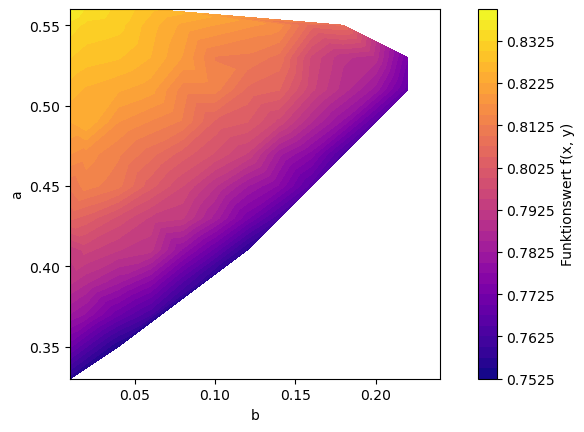

1.04


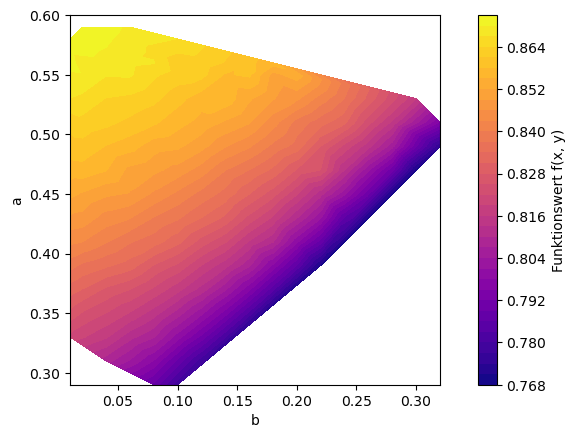

1.06


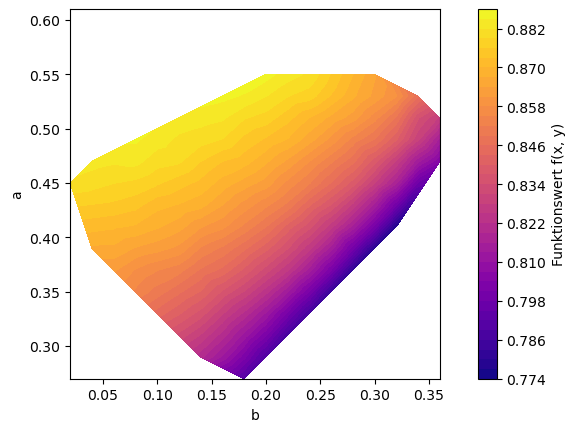

1.08


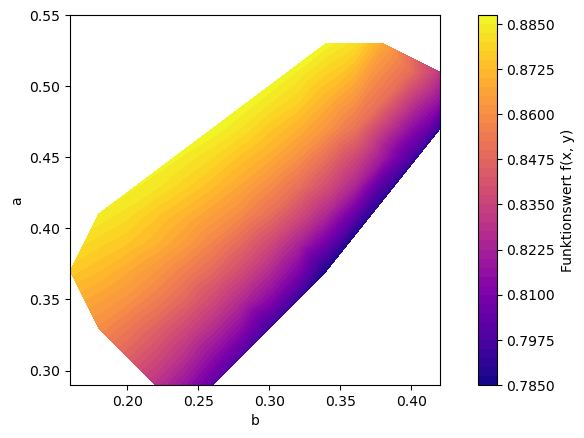

1.1


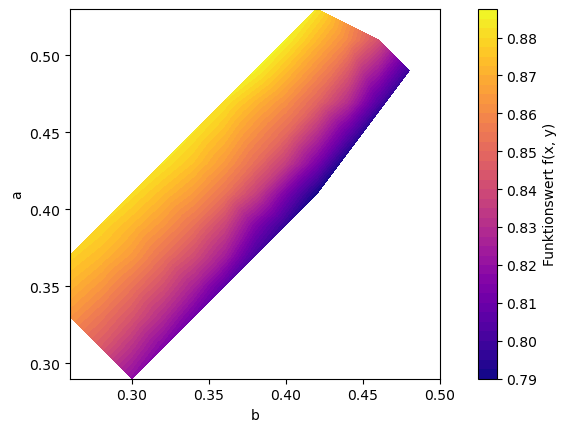

1.12


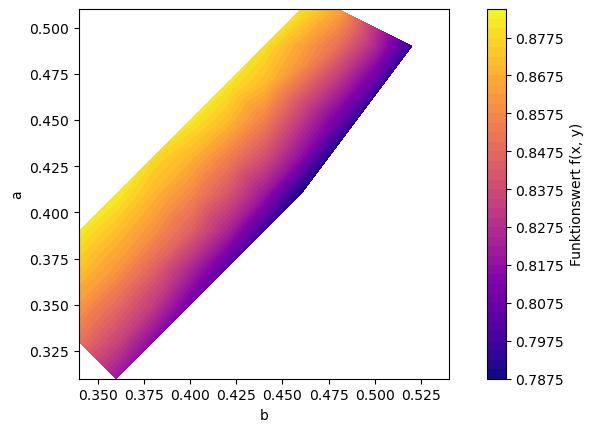

1.14


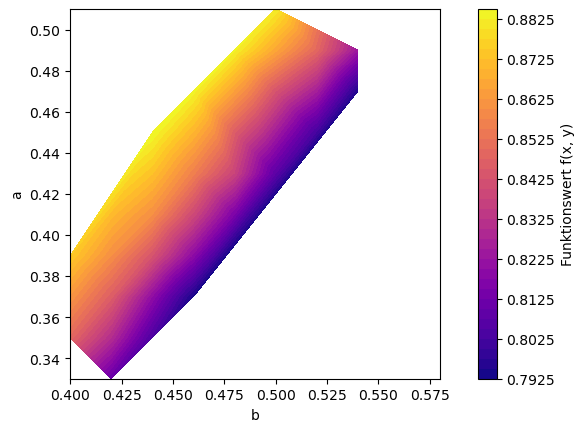

1.32


In [149]:
# Ratio with 6 holes
unique_dist = np.unique(dist_array)
dist_sort = np.sort(unique_dist)
for i, dist_temp in enumerate(dist_sort):
    a_array_temp = a_array_with_neighbors_list[i]
    b_array_temp = b_array_with_neighbors_list[i]
    ratio_array_temp = ratio_array_with_neighbors_list[i]
    print(dist_temp)

    if a_array_temp.size > 3:
    # Triangulation
        triang = tri.Triangulation(a_array_temp, b_array_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, ratio_array_temp, cmap='plasma',levels= 40)

        plt.colorbar(label='Funktionswert f(x, y)')
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

1.02


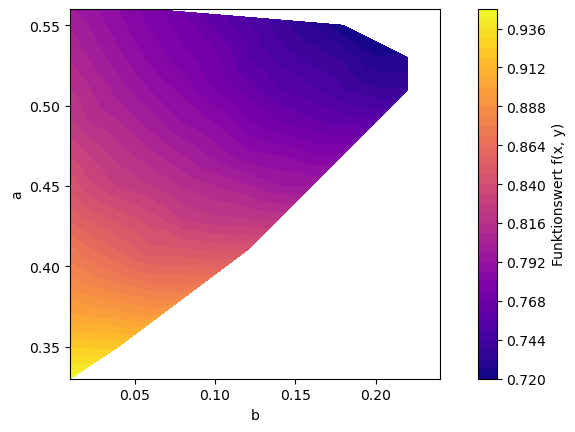

1.04


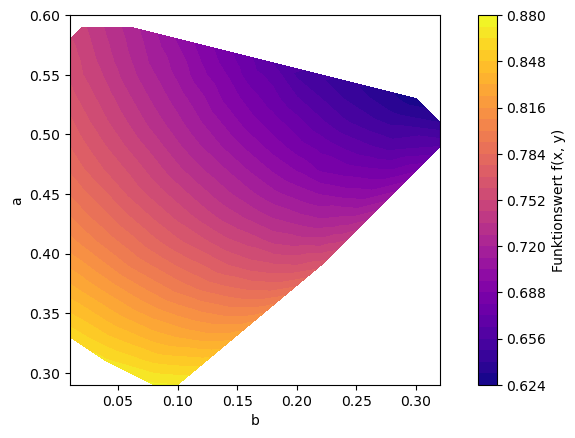

1.06


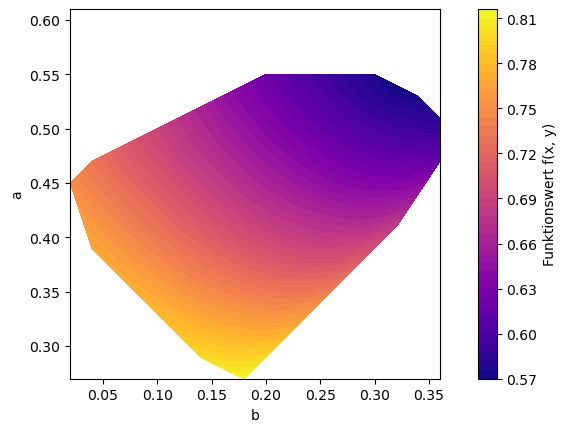

1.08


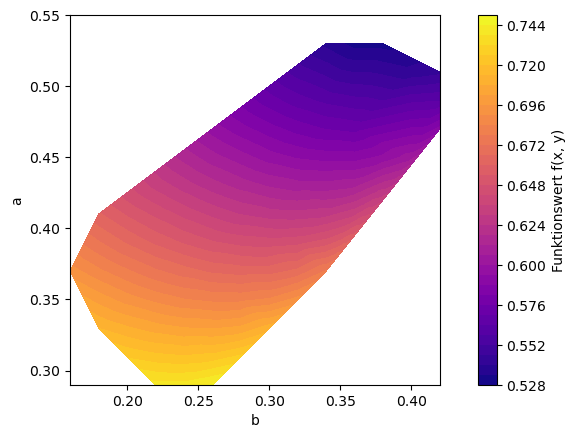

1.1


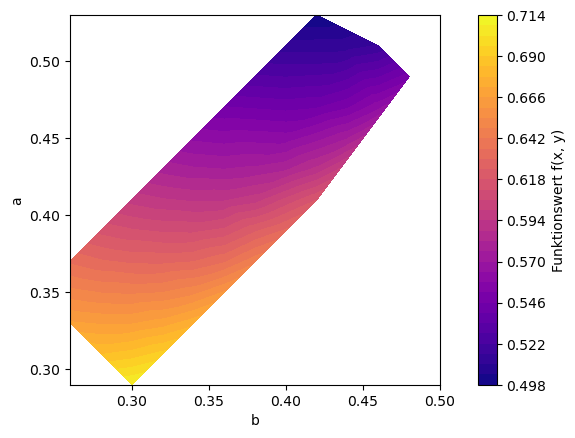

1.12


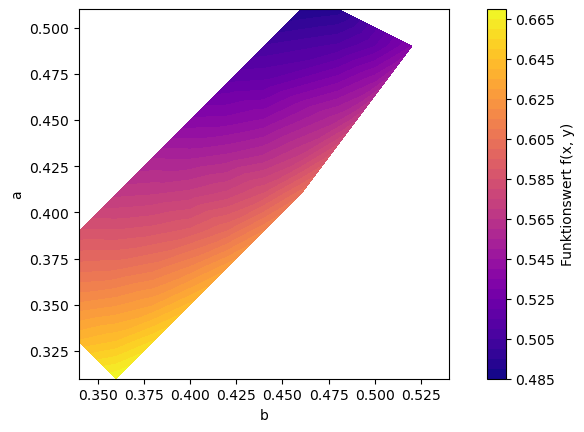

1.14


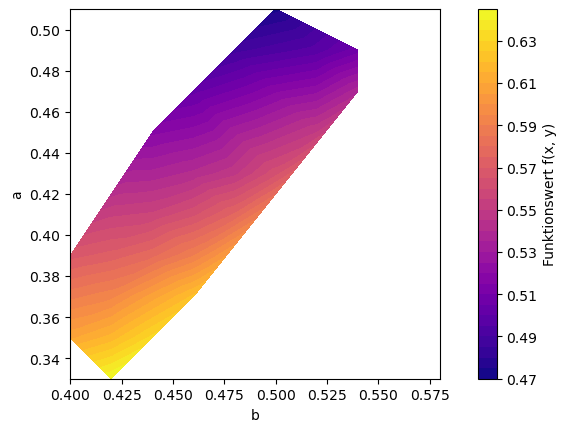

1.32


In [150]:
# xa with 6 holes
unique_dist = np.unique(dist_array)
dist_sort = np.sort(unique_dist)
for i, dist_temp in enumerate(dist_sort):
    a_array_temp = a_array_with_neighbors_list[i]
    b_array_temp = b_array_with_neighbors_list[i]
    xa_array_temp = xa_array_with_neighbors_list[i]
    print(dist_temp)
    
    if a_array_temp.size > 3:
    # Triangulation
        triang = tri.Triangulation(a_array_temp, b_array_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, xa_array_temp, cmap='plasma',levels= 40)

        plt.colorbar(label='Funktionswert f(x, y)')
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

1.02


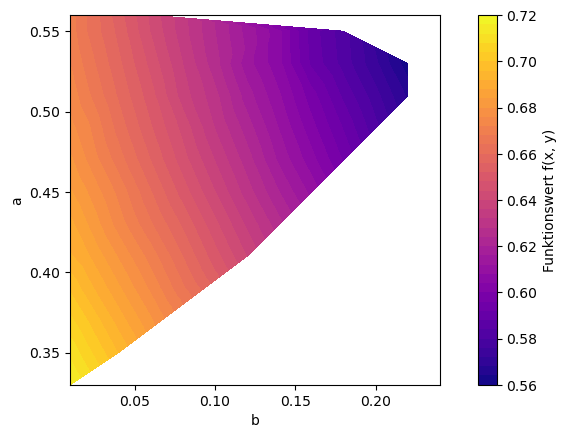

1.04


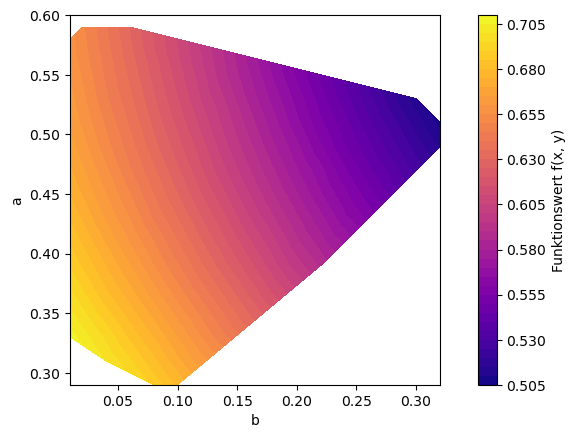

1.06


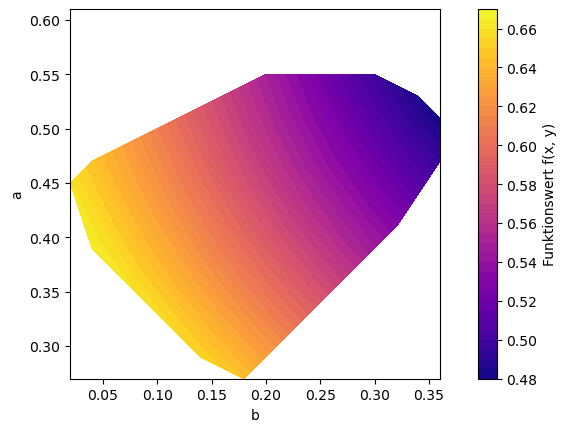

1.08


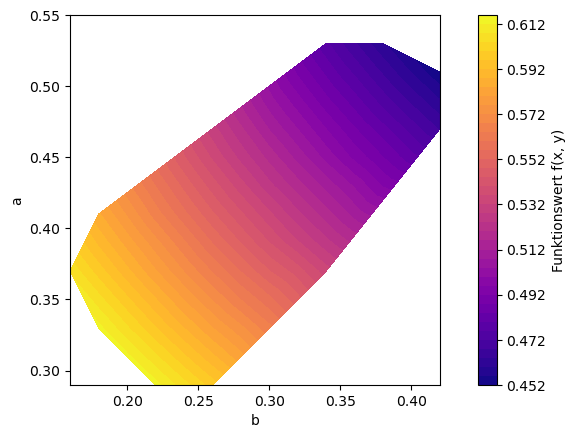

1.1


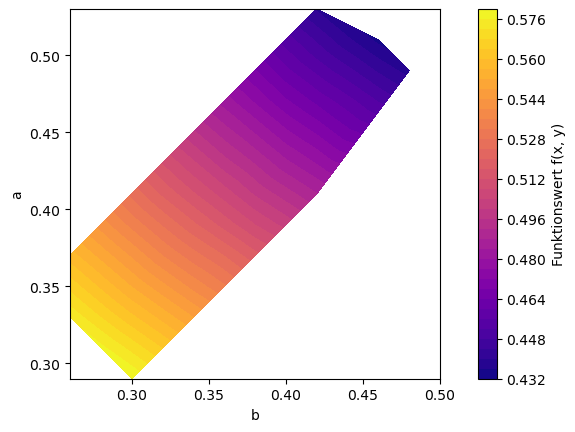

1.12


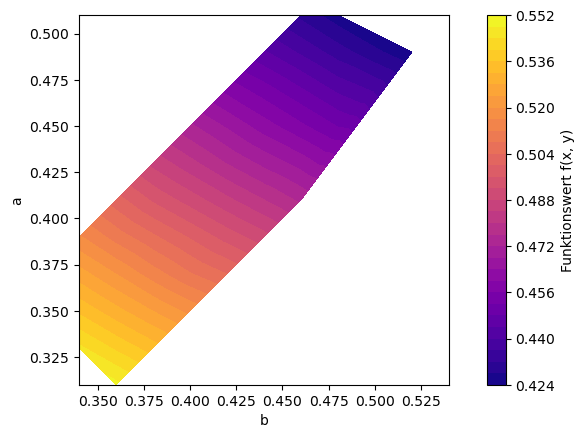

1.14


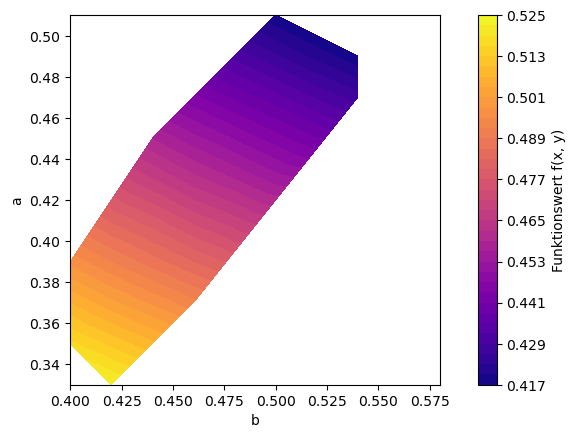

1.32


In [151]:
# xi with 6 holes
unique_dist = np.unique(dist_array)
dist_sort = np.sort(unique_dist)
for i, dist_temp in enumerate(dist_sort):
    a_array_temp = a_array_with_neighbors_list[i]
    b_array_temp = b_array_with_neighbors_list[i]
    xi_array_temp = xi_array_with_neighbors_list[i]
    print(dist_temp)
    
    if a_array_temp.size > 3:
    # Triangulation
        triang = tri.Triangulation(a_array_temp, b_array_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, xi_array_temp, cmap='plasma',levels= 40)

        plt.colorbar(label='Funktionswert f(x, y)')
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

# Behalte nur die Punkte, die Nachbarpunkte besitzen 5 Löcher

In [152]:
unique_dist_5_holes = np.unique(dist_array_5_holes)
dist_sort_5_holes = np.sort(unique_dist_5_holes)
a_array_with_neighbors_list_5_holes = []
b_array_with_neighbors_list_5_holes = []
xa_array_with_neighbors_list_5_holes = []
xi_array_with_neighbors_list_5_holes = []
ratio_array_with_neighbors_list_5_holes = []
for dist_temp in dist_sort_5_holes:
    mask_dist_temp_5_holes = (dist_array_5_holes == dist_temp)
    a_array_temp_5_holes = a_array_5_holes[mask_dist_temp_5_holes]
    b_array_temp_5_holes = b_array_5_holes[mask_dist_temp_5_holes]
    xa_array_temp_5_holes = xa_array_5_holes[mask_dist_temp_5_holes]
    xi_array_temp_5_holes = xi_array_5_holes[mask_dist_temp_5_holes]
    ratio_array_temp_5_holes = ratio_array_5_holes[mask_dist_temp_5_holes]
    
    # Calculate the distance between all the "a" and all the "b" parameters for the current distance
    a_dist_5_holes = a_array_temp_5_holes[:,None]-a_array_temp_5_holes
    b_dist_5_holes = b_array_temp_5_holes[:,None]-b_array_temp_5_holes
    a_mask_dist = (np.abs(a_dist_5_holes) < 0.021)
    a_mask_0 = (np.abs(a_dist_5_holes) < 0.001)
    b_mask_dist = (np.abs(b_dist_5_holes ) < 0.021)
    b_mask_0 = (np.abs(b_dist_5_holes) < 0.001)
    
    is_neighbor_mask = ((~a_mask_0) & a_mask_dist & b_mask_0)|(a_mask_0 & b_mask_dist & (~b_mask_0)) | (a_mask_dist & (~a_mask_0) & b_mask_dist & (~b_mask_0))  | (a_array_temp_5_holes<=0.02) | (b_array_temp_5_holes<=0.02)
    np.fill_diagonal(is_neighbor_mask, False)
    has_neighbor_mask = np.any(is_neighbor_mask, axis = 1)
    a_array_with_neighbors = a_array_temp_5_holes[has_neighbor_mask]
    b_array_with_neighbors = b_array_temp_5_holes[has_neighbor_mask]
    xa_array_with_neighbors = xa_array_temp_5_holes[has_neighbor_mask]
    xi_array_with_neighbors = xi_array_temp_5_holes[has_neighbor_mask]
    ratio_array_with_neighbors = ratio_array_temp_5_holes[has_neighbor_mask]
    
    a_array_with_neighbors_list_5_holes.append(a_array_with_neighbors) 
    b_array_with_neighbors_list_5_holes.append(b_array_with_neighbors) 
    xa_array_with_neighbors_list_5_holes.append(xa_array_with_neighbors) 
    xi_array_with_neighbors_list_5_holes.append(xi_array_with_neighbors) 
    ratio_array_with_neighbors_list_5_holes.append(ratio_array_with_neighbors) 

In [153]:
delete_points = np.array([[1.02,1.06,1.06], [0.30,0.36,0.37], [0.65,0.60,0.59]])
unique_dist_delete = np.unique(delete_points[0])
for i , dist_delete in enumerate(unique_dist_delete):
    mask_delete_dist = (delete_points[0,:] == dist_delete)
    idx_dist = np.argwhere(dist_sort_5_holes == dist_delete)[0,0]
    a_array_with_neighbors_list_dist = a_array_with_neighbors_list_5_holes[idx_dist]
    b_array_with_neighbors_list_dist = b_array_with_neighbors_list_5_holes[idx_dist]
    xa_array_with_neighbors_list_dist = xa_array_with_neighbors_list_5_holes[idx_dist]
    xi_array_with_neighbors_list_dist = xi_array_with_neighbors_list_5_holes[idx_dist]
    ratio_array_with_neighbors_list_dist = ratio_array_with_neighbors_list_5_holes[idx_dist]

    a_delete = delete_points[1,mask_delete_dist]
    b_delete = delete_points[2,mask_delete_dist]
    mask_delete = ((a_array_with_neighbors_list_dist == a_delete[:,None]) & (b_array_with_neighbors_list_dist == b_delete[:,None]))
    mask_delete_all_points_per_dist = ~np.any(mask_delete, axis=0)
    a_array_with_neighbors_list_5_holes[idx_dist] = a_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    b_array_with_neighbors_list_5_holes[idx_dist] = b_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    xa_array_with_neighbors_list_5_holes[idx_dist] = xa_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    xi_array_with_neighbors_list_5_holes[idx_dist] = xi_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]
    ratio_array_with_neighbors_list_5_holes[idx_dist] = ratio_array_with_neighbors_list_dist[mask_delete_all_points_per_dist]

1.02


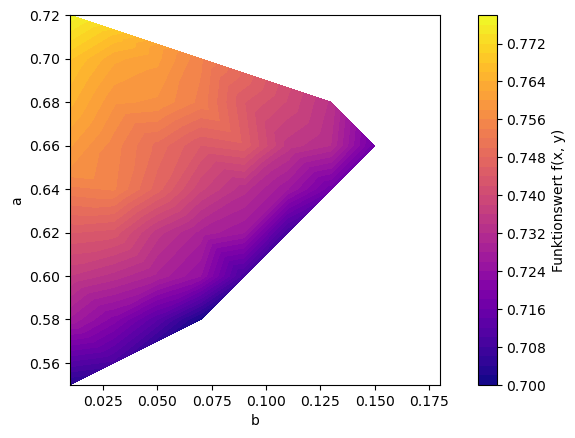

1.04


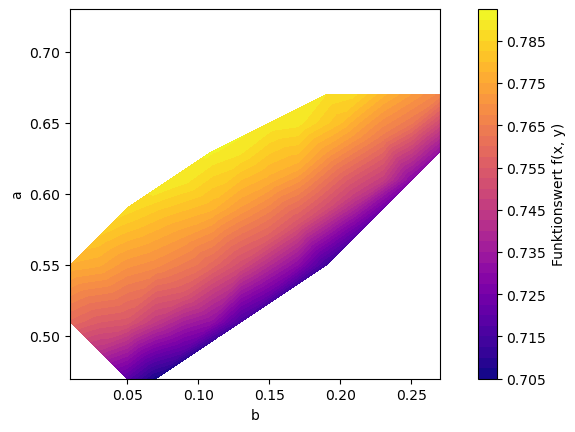

1.06


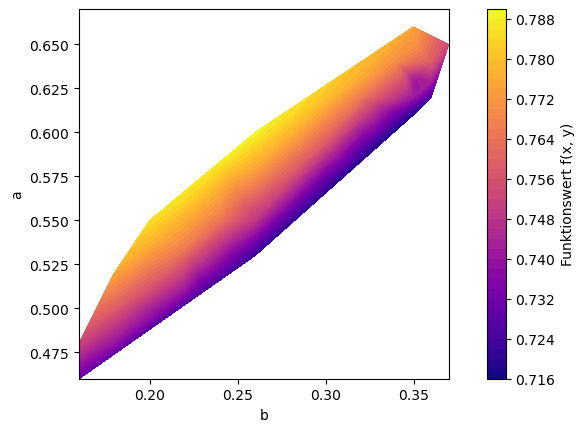

1.08


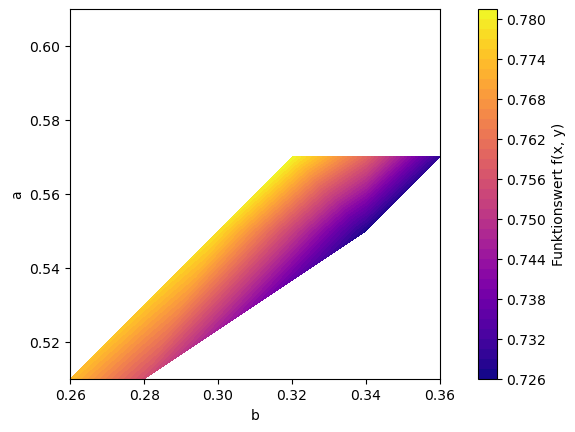

In [154]:
# Ratio with 5 holes
unique_dist_5_holes = np.unique(dist_array_5_holes)
dist_sort_5_holes = np.sort(unique_dist_5_holes)
for i, dist_temp in enumerate(dist_sort_5_holes):
    a_array_temp = a_array_with_neighbors_list_5_holes[i]
    b_array_temp = b_array_with_neighbors_list_5_holes[i]
    ratio_array_temp = ratio_array_with_neighbors_list_5_holes[i]
    print(dist_temp)

    if a_array_temp.size > 3:
    # Triangulation
        triang = tri.Triangulation(a_array_temp, b_array_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, ratio_array_temp, cmap='plasma',levels= 40)

        plt.colorbar(label='Funktionswert f(x, y)')
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

1.02


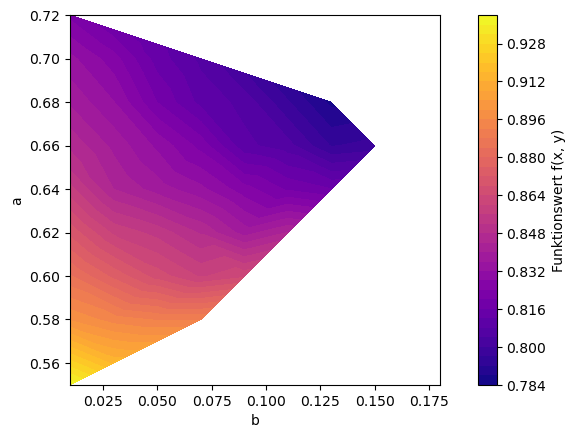

1.04


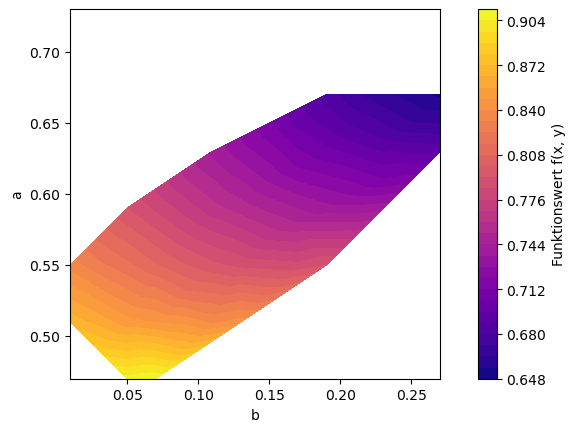

1.06


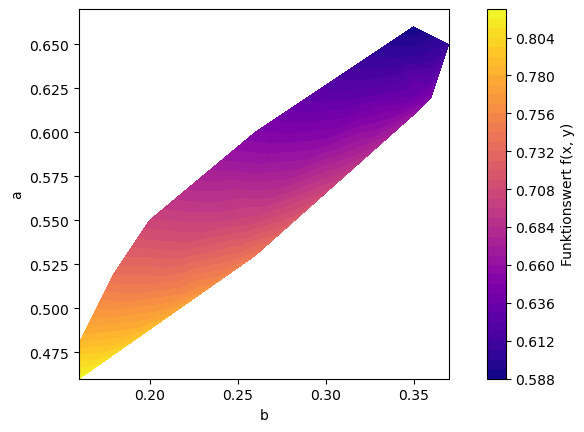

1.08


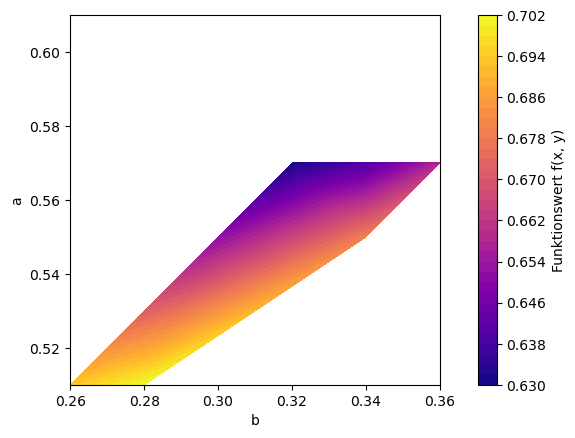

In [155]:
# xa with 5 holes
unique_dist_5_holes = np.unique(dist_array_5_holes)
dist_sort_5_holes = np.sort(unique_dist_5_holes)
for i, dist_temp in enumerate(dist_sort_5_holes):
    a_array_temp = a_array_with_neighbors_list_5_holes[i]
    b_array_temp = b_array_with_neighbors_list_5_holes[i]
    xa_array_temp = xa_array_with_neighbors_list_5_holes[i]
    print(dist_temp)

    if a_array_temp.size > 3:
    # Triangulation
        triang = tri.Triangulation(a_array_temp, b_array_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, xa_array_temp, cmap='plasma',levels= 40)

        plt.colorbar(label='Funktionswert f(x, y)')
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

1.02


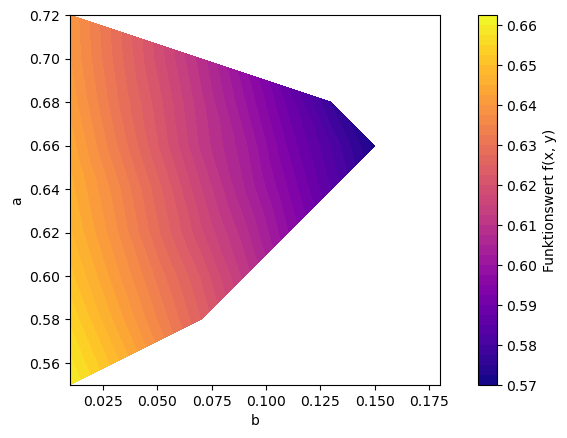

1.04


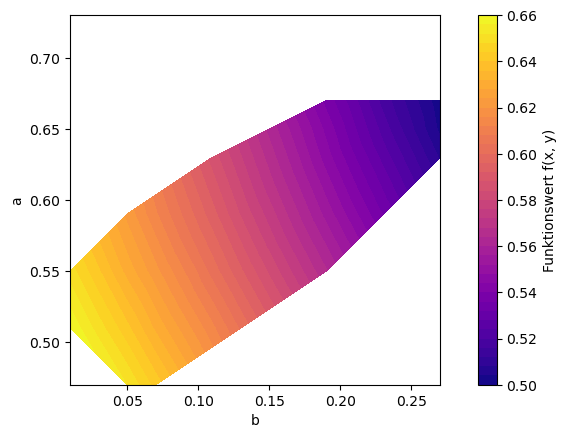

1.06


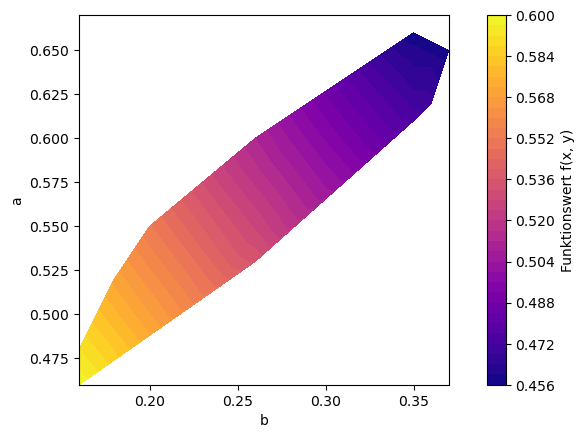

1.08


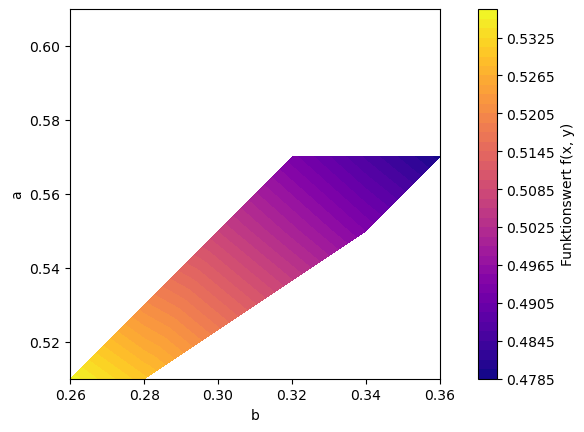

In [156]:
# xi with 5 holes
unique_dist_5_holes = np.unique(dist_array_5_holes)
dist_sort_5_holes = np.sort(unique_dist_5_holes)
for i, dist_temp in enumerate(dist_sort_5_holes):
    a_array_temp = a_array_with_neighbors_list_5_holes[i]
    b_array_temp = b_array_with_neighbors_list_5_holes[i]
    xi_array_temp = xi_array_with_neighbors_list_5_holes[i]
    print(dist_temp)

    if a_array_temp.size > 3:
    # Triangulation
        triang = tri.Triangulation(a_array_temp, b_array_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, xi_array_temp, cmap='plasma',levels= 40)

        plt.colorbar(label='Funktionswert f(x, y)')
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

# Model

In [157]:
x_6_holes = np.hstack(a_array_with_neighbors_list)
y_6_holes = np.hstack(b_array_with_neighbors_list)
x_5_holes = np.hstack(a_array_with_neighbors_list_5_holes)
y_5_holes = np.hstack(b_array_with_neighbors_list_5_holes)
x = np.hstack((x_5_holes, x_6_holes))
y = np.hstack((y_5_holes, y_6_holes))

In [158]:
a_shape = []
dist_all_list = []

for i, a_i in enumerate(a_array_with_neighbors_list_5_holes):
    dist_all_list.append(np.repeat(dist_sort_5_holes[i], a_i.shape[0]))


for i, a_i in enumerate(a_array_with_neighbors_list):
    dist_all_list.append(np.repeat(dist_sort[i], a_i.shape[0]))

dist_all = np.hstack(dist_all_list)
z = dist_all

In [159]:
n_holes = np.hstack((np.repeat(5, x_5_holes.shape),np.repeat(6, x_6_holes.shape)))

In [160]:
z = np.real(z)
x = np.real(x)
y = np.real(y)

In [161]:
f_xa_6_holes = np.hstack(xa_array_with_neighbors_list)
f_xi_6_holes = np.hstack(xi_array_with_neighbors_list)
f_ratio_6_holes = np.hstack(ratio_array_with_neighbors_list)

f_xa_5_holes = np.hstack(xa_array_with_neighbors_list_5_holes)
f_xi_5_holes = np.hstack(xi_array_with_neighbors_list_5_holes)
f_ratio_5_holes = np.hstack(ratio_array_with_neighbors_list_5_holes)

f_xa = np.hstack((f_xa_5_holes, f_xa_6_holes))
f_xi = np.hstack((f_xi_5_holes, f_xi_6_holes))
f_ratio = np.hstack((f_ratio_5_holes, f_ratio_6_holes))

In [162]:
A = np.column_stack([n_holes*x*x*x*x, n_holes*y*y*y*y, n_holes*z*z*z*z, n_holes*x*x*x*y, n_holes*x*x*x*z, n_holes*y*y*y*x, n_holes*y*y*y*z, n_holes*z*z*z*x, n_holes*z*z*z*y, n_holes*x*x*y*y, n_holes*x*x*y*z, n_holes*x*x*z*z, n_holes*y*y*x*z,  n_holes*y*y*z*z, n_holes*z*z*x*y, n_holes*x*x*x, n_holes*y*y*y, n_holes*z*z*z, n_holes*x*x*y, n_holes*x*x*z, n_holes*y*y*x, n_holes*y*y*z, n_holes*z*z*x, n_holes*z*z*y, n_holes*x*y*z, n_holes*x*x, n_holes*y*y, n_holes*z*z, n_holes*x*y, n_holes*x*z, n_holes*y*z, n_holes*x, n_holes*y, n_holes*z, n_holes, x*x*x*x, y*y*y*y, z*z*z*z, x*x*x*y, x*x*x*z, y*y*y*x, y*y*y*z, z*z*z*x, z*z*z*y, x*x*y*y, x*x*y*z, x*x*z*z, y*y*x*z,  y*y*z*z, z*z*x*y, x*x*x, y*y*y, z*z*z, x*x*y, x*x*z, y*y*x, y*y*z, z*z*x, z*z*y, x*y*z, x*x, y*y, z*z, x*y, x*z, y*z, x, y, z, np.ones_like(x)])

In [163]:
params_f_xa, *_ = np.linalg.lstsq(A,f_xa,rcond=None)
params_f_xi, *_ = np.linalg.lstsq(A,f_xi,rcond=None)
params_f_ratio, *_ = np.linalg.lstsq(A,f_ratio,rcond=None)

In [164]:
df = pd.DataFrame({"xa": params_f_xa,  "xi": params_f_xi, "ratio": params_f_ratio})
df.to_csv("parameters_models_xa_xi_ratio.csv", index=False)

In [165]:
def quartic_model_with_holes(params,x,y,z,n_holes):
    part_with_holes = params[0]*n_holes*x*x*x*x + params[1]*n_holes*y*y*y*y + params[2]*n_holes*z*z*z*z + params[3]*n_holes*x*x*x*y + params[4]*n_holes*x*x*x*z + params[5]*n_holes*y*y*y*x + params[6]*n_holes*y*y*y*z + params[7]*n_holes*z*z*z*x + params[8]*n_holes*z*z*z*y + params[9]*n_holes*x*x*y*y + params[10]*n_holes*x*x*y*z + params[11]*n_holes*x*x*z*z + params[12]*n_holes*y*y*x*z + params[13]*n_holes*y*y*z*z + params[14]*n_holes*z*z*x*y + params[15]*n_holes*x*x*x + params[16]*n_holes*y*y*y + params[17]*n_holes*z*z*z + params[18]*n_holes*x*x*y + params[19]*n_holes*x*x*z + params[20]*n_holes*y*y*x + params[21]*n_holes*y*y*z + params[22]*n_holes*z*z*x + params[23]*n_holes*z*z*y + params[24]*n_holes*x*y*z + params[25]*n_holes*x*x + params[26]*n_holes*y*y + params[27]*n_holes*z*z + params[28]*n_holes*x*y + params[29]*n_holes*x*z + params[30]*n_holes*y*z + params[31]*n_holes*x + params[32]*n_holes*y + params[33]*n_holes*z + params[34]*n_holes
    part_without_holes = params[35]*x*x*x*x + params[36]*y*y*y*y + params[37]*z*z*z*z + params[38]*x*x*x*y + params[39]*x*x*x*z + params[40]*y*y*y*x + params[41]*y*y*y*z + params[42]*z*z*z*x + params[43]*z*z*z*y + params[44]*x*x*y*y + params[45]*x*x*y*z + params[46]*x*x*z*z + params[47]*y*y*x*z + params[48]*y*y*z*z + params[49]*z*z*x*y + params[50]*x*x*x + params[51]*y*y*y + params[52]*z*z*z + params[53]*x*x*y + params[54]*x*x*z + params[55]*y*y*x + params[56]*y*y*z + params[57]*z*z*x + params[58]*z*z*y + params[59]*x*y*z + params[60]*x*x + params[61]*y*y + params[62]*z*z + params[63]*x*y + params[64]*x*z + params[65]*y*z + params[66]*x + params[67]*y + params[68]*z + params[69]*1
    return part_with_holes + part_without_holes

In [166]:
def define_x_y_points_per_dist(dist, a, b):
    dist_unique = np.sort(np.unique(dist))
    dist_list = []
    a_list = []
    b_list = []
    for dist_temp in dist_unique:
        dist_mask = (dist == dist_temp)
        a_dist_temp = a[dist_mask]
        b_dist_temp = b[dist_mask]
        b_unique = np.sort(np.unique(b_dist_temp))
        for b_temp in b_unique:
            b_mask = (b_dist_temp == b_temp)
            a_dist_b_temp = a_dist_temp[b_mask]
            a_min_temp = np.min(a_dist_b_temp)
            a_max_temp = np.max(a_dist_b_temp)
            a_linspace = np.arange(a_min_temp, a_max_temp + 0.01, 0.01)
            b_linspace = np.repeat(b_temp, a_linspace.size)
            dist_linspace = np.repeat(dist_temp, a_linspace.size)
            a_list.append(a_linspace)
            b_list.append(b_linspace)
            dist_list.append(dist_linspace)
    a_array = np.hstack(a_list)
    b_array = np.hstack(b_list)
    dist_array = np.hstack(dist_list)
    return dist_array, a_array, b_array

In [167]:
def define_x_y_points_per_dist_and_n_holes(n_holes, dist, a, b):
    n_holes_list = []
    dist_list = []
    a_list = []
    b_list = []
    n_holes_unique = np.sort(np.unique(n_holes))
    print(n_holes_unique)
    for n_holes_temp in n_holes_unique:
        n_holes_mask = (n_holes == n_holes_temp)
        dist_n_holes_temp = dist[n_holes_mask]
        a_n_holes_temp = a[n_holes_mask]
        b_n_holes_temp = b[n_holes_mask]
        dist_unique = np.sort(np.unique(dist_n_holes_temp))
        for dist_temp in dist_unique:
            dist_mask = (dist_n_holes_temp == dist_temp)
            a_dist_temp = a_n_holes_temp[dist_mask]
            b_dist_temp = b_n_holes_temp[dist_mask]
            b_unique = np.sort(np.unique(b_dist_temp))
            for b_temp in b_unique:
                b_mask = (b_dist_temp == b_temp)
                a_dist_b_temp = a_dist_temp[b_mask]
                a_min_temp = np.min(a_dist_b_temp)
                a_max_temp = np.max(a_dist_b_temp)
                a_linspace = np.arange(a_min_temp, a_max_temp + 0.01, 0.01)
                b_linspace = np.repeat(b_temp, a_linspace.size)
                dist_linspace = np.repeat(dist_temp, a_linspace.size)
                n_holes_linspace = np.repeat(n_holes_temp, a_linspace.size)
                a_list.append(a_linspace)
                b_list.append(b_linspace)
                dist_list.append(dist_linspace)
                n_holes_list.append(n_holes_linspace)
    a_array = np.hstack(a_list)
    b_array = np.hstack(b_list)
    dist_array = np.hstack(dist_list)
    n_holes_array = np.hstack(n_holes_list)
    return n_holes_array, dist_array, a_array, b_array

In [168]:
n_holes_mesh, dist_mesh, x_mesh, y_mesh = define_x_y_points_per_dist_and_n_holes(n_holes, z, x, y)

[5 6]


# Xa Ergebnis und Fehler

In [169]:
from IPython.display import Markdown, display

In [170]:
display(Markdown(
rf"""
$$
\begin{{aligned}}
    &{params_f_xa[0]} x^4+ {params_f_xa[1]} y^4 + {params_f_xa[2]} z^4 + {params_f_xa[3]} x^3 y + {params_f_xa[4]} x^3 z \\
    &+ {params_f_xa[5]}y^3 x + {params_f_xa[6]} y^3 z + {params_f_xa[7]} z^3 x + {params_f_xa[8]} z^3 y + {params_f_xa[9]} x^2 y^2\\
    &+ {params_f_xa[10]} x^2 y z + {params_f_xa[11]} x^2 z^2 + {params_f_xa[12]} y^2 x z + {params_f_xa[13]} y^2 z^2 \\
    &+ {params_f_xa[14]} z^2 x y + {params_f_xa[15]} x^3 + {params_f_xa[16]} y^3 + {params_f_xa[17]} z^3 + {params_f_xa[18]} x^2 y\\
    &+ {params_f_xa[19]} x^2 z + {params_f_xa[20]} y^2 x + {params_f_xa[21]} y^2 z + {params_f_xa[22]} z^2 x \\
    &+ {params_f_xa[23]} z^2 y + {params_f_xa[24]} x y z + {params_f_xa[25]} x^2 + {params_f_xa[26]} y^2 + {params_f_xa[27]} z^2\\
    &+ {params_f_xa[28]} x y + {params_f_xa[29]} x z + {params_f_xa[30]} y z + {params_f_xa[31]} x + {params_f_xa[32]} y \\
    &+ {params_f_xa[33]} z + {params_f_xa[34]}
\end{{aligned}}
$$
"""
))


$$
\begin{aligned}
    &-16.27620322429724 x^4+ -118.90588406887878 y^4 + 25763.02154996333 z^4 + 105.15487612786616 x^3 y + 748.7222673035462 x^3 z \\
    &+ 190.55641239719097y^3 x + -2020.3911344290625 y^3 z + 96419.08626096143 z^3 x + -116742.30261707713 z^3 y + -213.45338041583256 x^2 y^2\\
    &+ -3045.9368697391756 x^2 y z + -14834.142823926564 x^2 z^2 + 3938.594170335363 y^2 x z + -23794.39246397375 y^2 z^2 \\
    &+ 35665.70433815612 z^2 x y + -843.7776438124538 x^3 + 2372.5415956720803 y^3 + -59886.88513255725 z^3 + 3416.186527821288 x^2 y\\
    &+ 32453.51104018989 x^2 z + -4420.615464154701 y^2 x + 52750.067112756136 y^2 z + -318134.0686998886 z^2 x \\
    &+ 388124.32155563 z^2 y + -78279.15982853655 x y z + -17777.7240380425 x^2 + -29356.83514449248 y^2 + 13424.24884982859 z^2\\
    &+ 43016.47882574185 x y + 349935.1216093658 x z + -430274.7102939204 y z + -128330.99070319466 x + 159099.12076685435 y \\
    &+ 50813.28839021738 z + -30153.11056615718
\end{aligned}
$$


In [171]:
Z_all = []
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])
    
        Z_temp = quartic_model_with_holes(params_f_xa,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
        Z_all.append(Z_temp)

Number of holes is 5 and dist is 1.02
Number of holes is 5 and dist is 1.04
Number of holes is 5 and dist is 1.06
Number of holes is 5 and dist is 1.08
Number of holes is 6 and dist is 1.02
Number of holes is 6 and dist is 1.04
Number of holes is 6 and dist is 1.06
Number of holes is 6 and dist is 1.08
Number of holes is 6 and dist is 1.1
Number of holes is 6 and dist is 1.12
Number of holes is 6 and dist is 1.14


In [172]:
Z_all_array = np.hstack(Z_all)
Z_min = np.min(Z_all_array)
Z_min

np.float64(0.4731155905756168)

In [173]:
Z_max = np.max(Z_all_array)
Z_max

np.float64(0.9418678734218702)

In [174]:
norm = mcolors.Normalize(vmin=Z_min, vmax = Z_max)

In [175]:
def condition_no_intersection(dist, a, b, n_holes, params):
    return dist - b - quartic_model_with_holes(params,a,b,dist,n_holes)

In [176]:
from scipy.optimize import brentq

In [177]:
def calculate_width_maximum_width_of_ellipses(n_ellipses,distance,length):
    alpha12 = np.pi/n_ellipses
    width = np.sqrt(distance*distance - length*length/(np.tan(alpha12)*np.tan(alpha12)))
    return width

In [178]:
import os

Number of holes is 5 and dist is 1.02


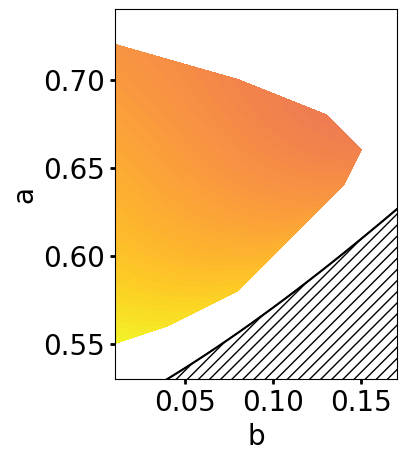

Number of holes is 5 and dist is 1.04


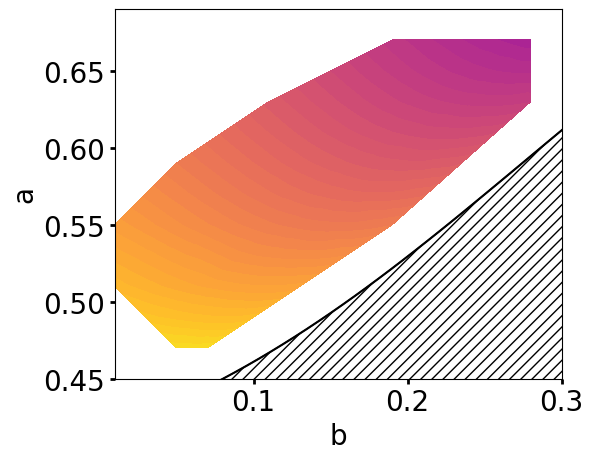

Number of holes is 5 and dist is 1.06


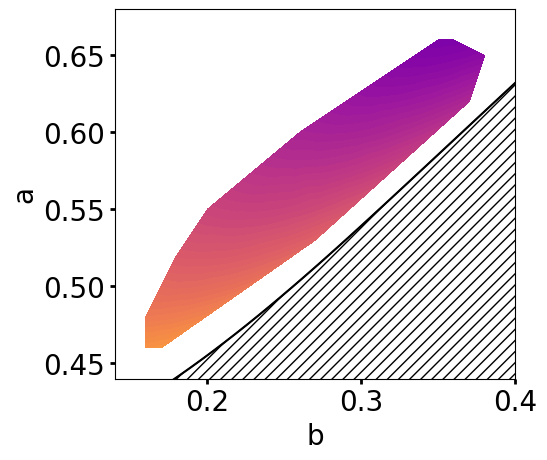

Number of holes is 5 and dist is 1.08


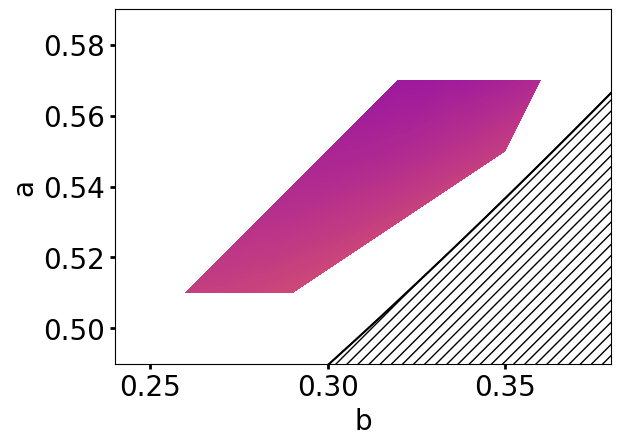

Number of holes is 6 and dist is 1.02


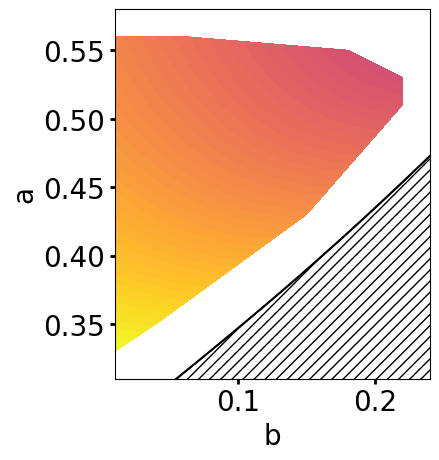

Number of holes is 6 and dist is 1.04


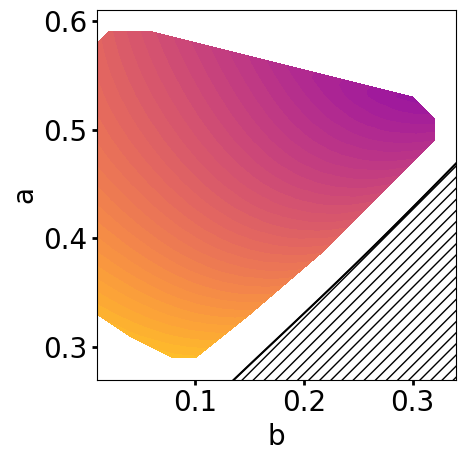

Number of holes is 6 and dist is 1.06


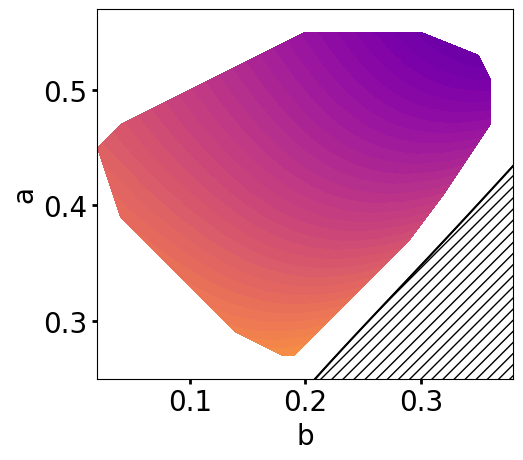

Number of holes is 6 and dist is 1.08


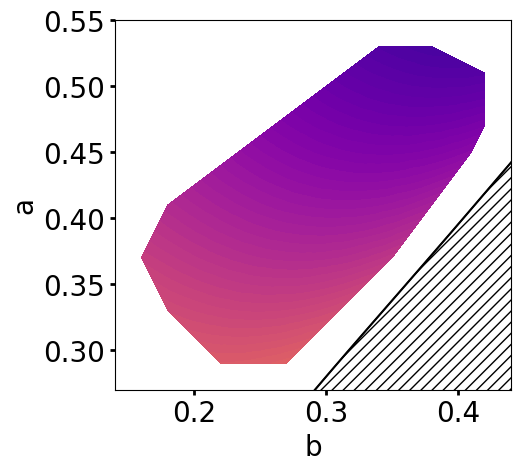

Number of holes is 6 and dist is 1.1


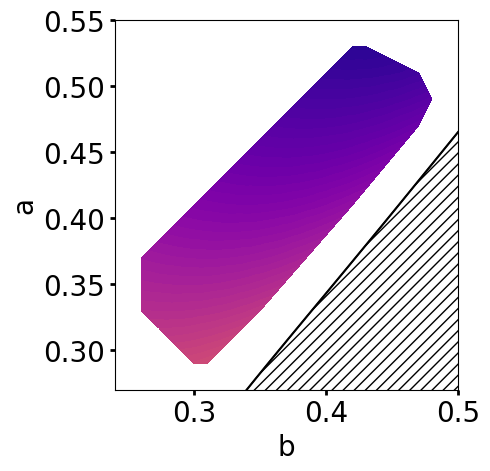

Number of holes is 6 and dist is 1.12


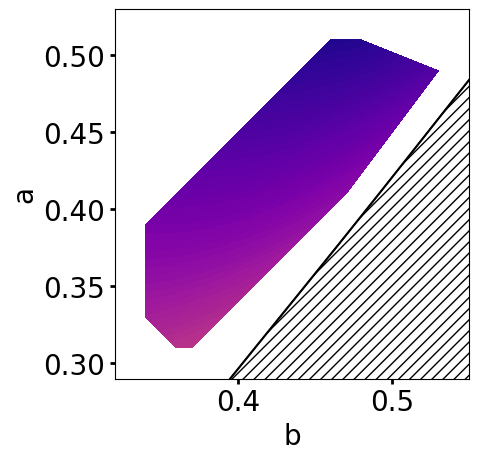

Number of holes is 6 and dist is 1.14


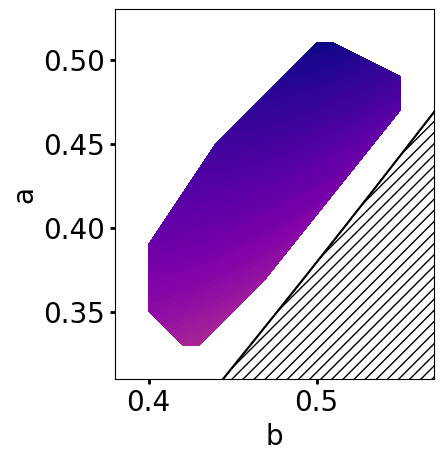

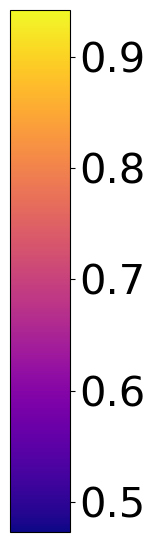

In [179]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])
    
        Z_temp = quartic_model_with_holes(params_f_xa,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
    
        X,Y = np.meshgrid(np.linspace(min(x_mesh_temp), max(x_mesh_temp), 100), np.linspace(min(y_mesh_temp), max(y_mesh_temp), 100))
        Z_all_temp = quartic_model_with_holes(params_f_xa,X,Y,dist_temp,n_holes_temp)
        
        Y_scatter = X.T[dist_temp - X.T < Z_all_temp.T]
        X_scatter = Y.T[dist_temp - X.T < Z_all_temp.T]
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        xlim_max = 1.2
        ylim_max = 0.8
        
        alpha12 = np.pi/n_ellipses
        max_length = dist_temp * np.tan(alpha12)-0.0000001
        length_linspace = np.linspace(max_length,0,100, endpoint=True)
        length_full_plot = np.concatenate((length_linspace, np.zeros((100))))
        
        width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist_temp, length_linspace)
        
        width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))
        
        #b_values = np.linspace(x_mesh_temp[np.argmin(y_mesh_temp)], max(x_mesh_temp)+0.5, 100)
        b_values = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values = np.full_like(b_values, np.nan)
        for i, b in enumerate(b_values):
            def condition_no_intersection(a):
                return dist_temp - b - quartic_model_with_holes(params_f_xa,b,a,dist_temp,n_holes_temp)

            try:
                a_values[i] = brentq(condition_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values[i] = np.nan
        
        # Kontur-Plot
        plt.rcParams.update({'font.size':20})
        plt.tick_params(axis='both', width=2)
        plt.tricontourf(triang, Z_temp, cmap='plasma',levels= 40, norm=norm)
        plt.plot(b_values, a_values, 'black')
        plt.fill_between(b_values, a_values, 0, facecolor='None',
            hatch='///',
            edgecolor='black',
            label='invalid / not tested')

        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        if(np.min(x_mesh_temp) <= 0.02):
            plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        else:
            plt.xlim(np.min(x_mesh_temp)-0.02, np.max(x_mesh_temp)+0.02)
        plt.ylim(np.min(y_mesh_temp)-0.02, np.max(y_mesh_temp)+0.02)
        plt.show()

sm = plt.cm.ScalarMappable(norm=norm,cmap="plasma")
fig = plt.figure(figsize=(3,6))

cax = fig.add_axes([0.4,0.08,0.2,0.87])
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar.ax.tick_params(labelsize=30)




In [180]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])

        Z_temp = quartic_model_with_holes(params_f_xa,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
    
        X,Y = np.meshgrid(np.linspace(min(x_mesh_temp), max(x_mesh_temp), 100), np.linspace(min(y_mesh_temp), max(y_mesh_temp), 100))
        Z_all_temp = quartic_model_with_holes(params_f_xa,X,Y,dist_temp,n_holes_temp)

        Y_scatter = X.T[dist_temp - X.T < Z_all_temp.T]
        X_scatter = Y.T[dist_temp - X.T < Z_all_temp.T]
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        xlim_max = 1.2
        ylim_max = 0.8
        
        alpha12 = np.pi/n_ellipses
        max_length = dist_temp * np.tan(alpha12)-0.0000001
        length_linspace = np.linspace(max_length,0,100, endpoint=True)
        length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

        width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist_temp, length_linspace)
        
        width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

        b_values = np.linspace(x_mesh_temp[np.argmin(y_mesh_temp)], max(x_mesh_temp)+0.5, 100)
        b_values = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values = np.full_like(b_values, np.nan)
        for i, b in enumerate(b_values):
            def condition_no_intersection(a):
                return dist_temp - b - quartic_model_with_holes(params_f_xa,b,a,dist_temp,n_holes_temp)

            try:
                a_values[i] = brentq(condition_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values[i] = np.nan
        
        # Kontur-Plot
        plt.rcParams.update({'font.size':20})
        plt.tick_params(axis='both', width=2)
        plt.tricontourf(triang, Z_temp, cmap='plasma',levels= 40, norm=norm)
        plt.plot(b_values, a_values, 'black')
        plt.fill_between(b_values, a_values, 0, facecolor='None',
            hatch='///',
            edgecolor='black',
            label='invalid / not tested')

        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        if(np.min(x_mesh_temp) <= 0.02):
            plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        else:
            plt.xlim(np.min(x_mesh_temp)-0.02, np.max(x_mesh_temp)+0.02)
        plt.ylim(np.min(y_mesh_temp)-0.02, np.max(y_mesh_temp)+0.02)
        os.makedirs("Plots_xa_6_and_5_holes", exist_ok = True)
        filename = f"Plots_xa_6_and_5_holes/Xa_{str(n_holes_temp).replace('.', '_')}_ellipses_distance_{str(dist_temp).replace('.', '_')}.eps"
        print(filename)
        plt.tight_layout()
        plt.savefig(filename,dpi=300)
        plt.close()

sm = plt.cm.ScalarMappable(norm=norm,cmap="plasma")
fig = plt.figure(figsize=(3,6))

cax = fig.add_axes([0.4,0.08,0.2,0.87])
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar.ax.tick_params(labelsize=30)
filename = f"Plots_xa_6_and_5_holes/Xa_colorbar.eps"
print(filename)
plt.savefig(filename,dpi=300)
plt.close()

Number of holes is 5 and dist is 1.02
Plots_xa_6_and_5_holes/Xa_5_ellipses_distance_1_02.eps
Number of holes is 5 and dist is 1.04
Plots_xa_6_and_5_holes/Xa_5_ellipses_distance_1_04.eps
Number of holes is 5 and dist is 1.06
Plots_xa_6_and_5_holes/Xa_5_ellipses_distance_1_06.eps
Number of holes is 5 and dist is 1.08
Plots_xa_6_and_5_holes/Xa_5_ellipses_distance_1_08.eps
Number of holes is 6 and dist is 1.02
Plots_xa_6_and_5_holes/Xa_6_ellipses_distance_1_02.eps
Number of holes is 6 and dist is 1.04
Plots_xa_6_and_5_holes/Xa_6_ellipses_distance_1_04.eps
Number of holes is 6 and dist is 1.06
Plots_xa_6_and_5_holes/Xa_6_ellipses_distance_1_06.eps
Number of holes is 6 and dist is 1.08
Plots_xa_6_and_5_holes/Xa_6_ellipses_distance_1_08.eps
Number of holes is 6 and dist is 1.1
Plots_xa_6_and_5_holes/Xa_6_ellipses_distance_1_1.eps
Number of holes is 6 and dist is 1.12
Plots_xa_6_and_5_holes/Xa_6_ellipses_distance_1_12.eps
Number of holes is 6 and dist is 1.14
Plots_xa_6_and_5_holes/Xa_6_ellips

Number of holes is 5 and dist is 1.02


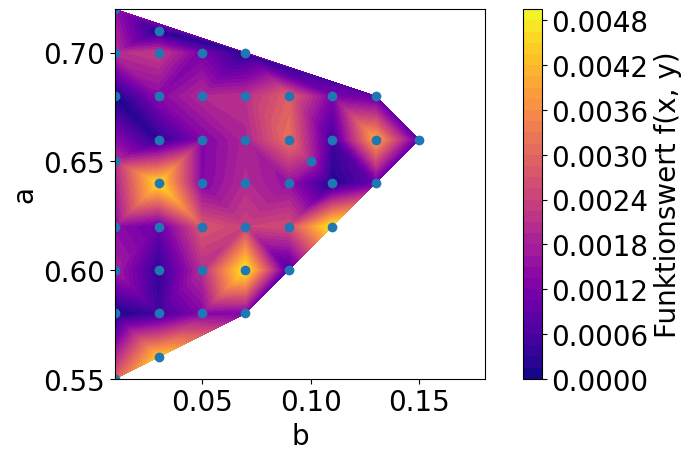

Number of holes is 5 and dist is 1.04


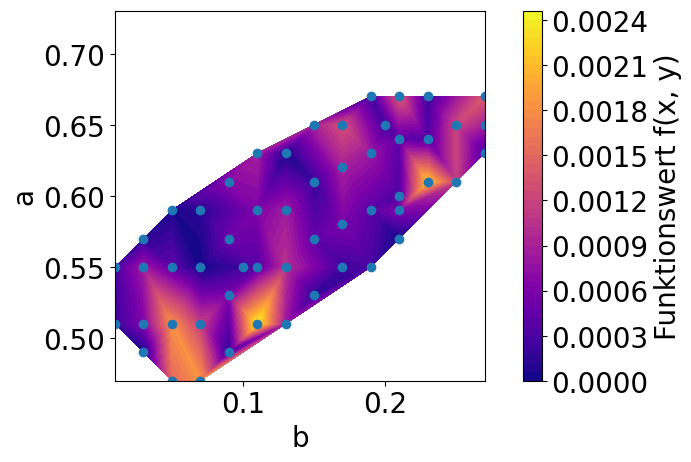

Number of holes is 5 and dist is 1.06


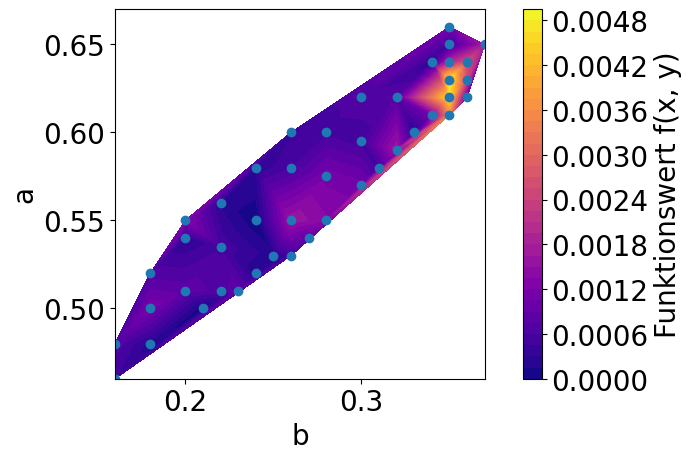

Number of holes is 5 and dist is 1.08


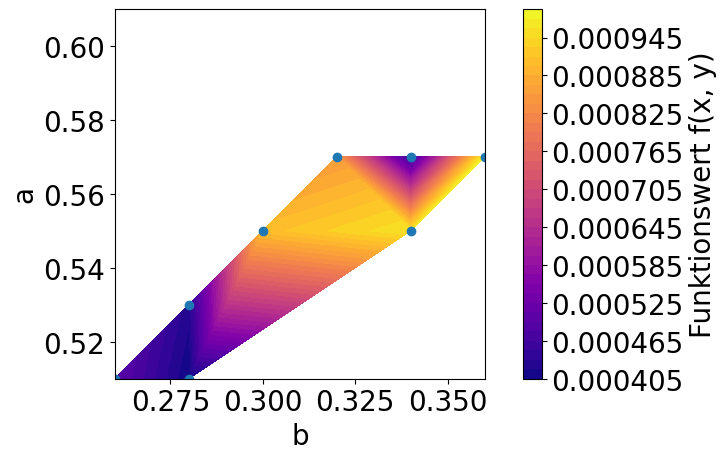

Number of holes is 6 and dist is 1.02


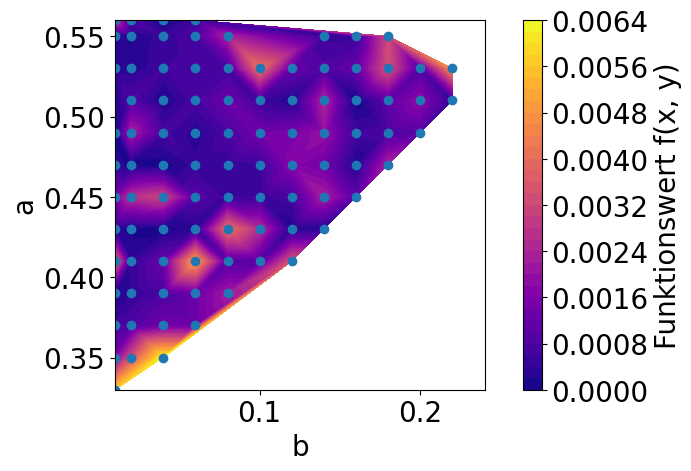

Number of holes is 6 and dist is 1.04


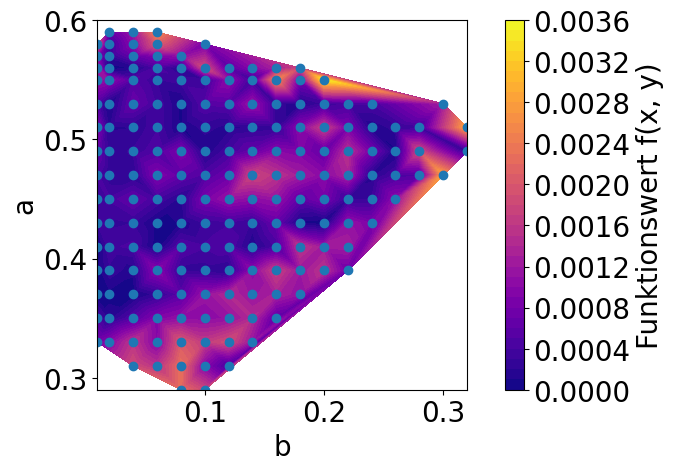

Number of holes is 6 and dist is 1.06


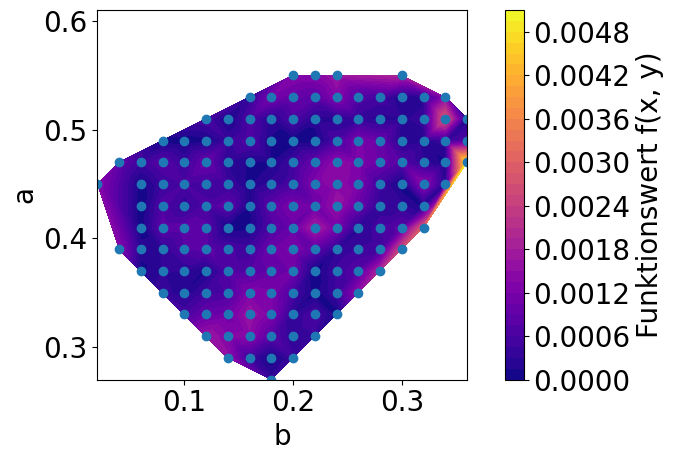

Number of holes is 6 and dist is 1.08


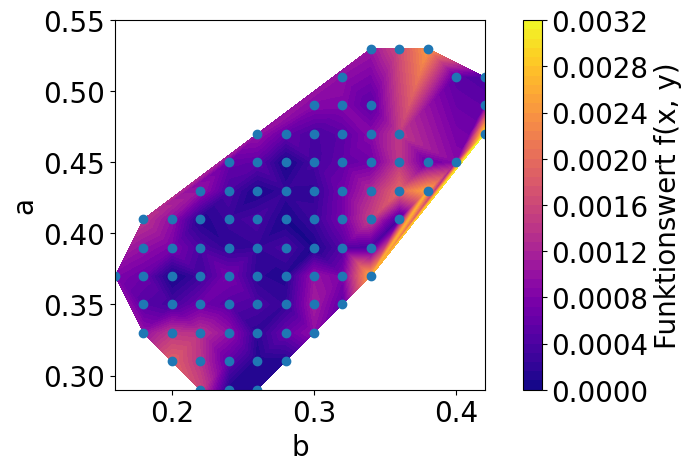

Number of holes is 6 and dist is 1.1


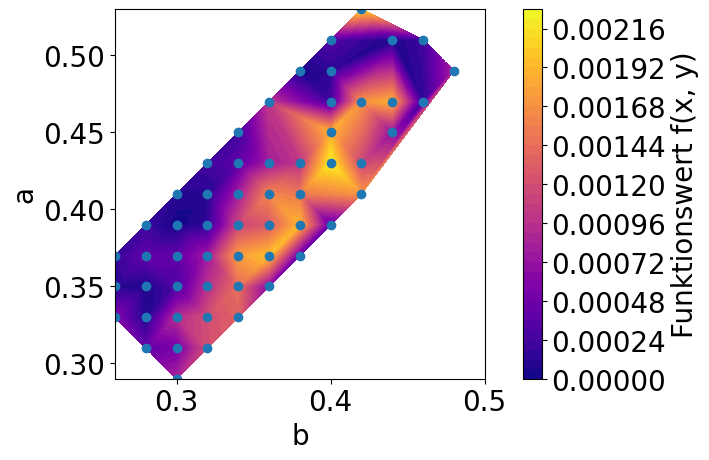

Number of holes is 6 and dist is 1.12


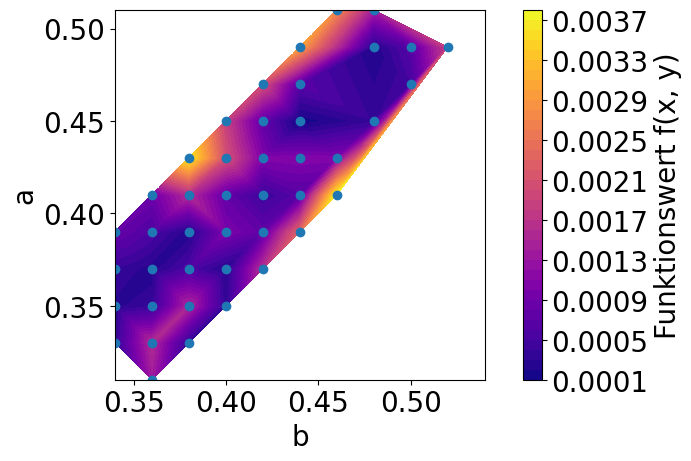

Number of holes is 6 and dist is 1.14


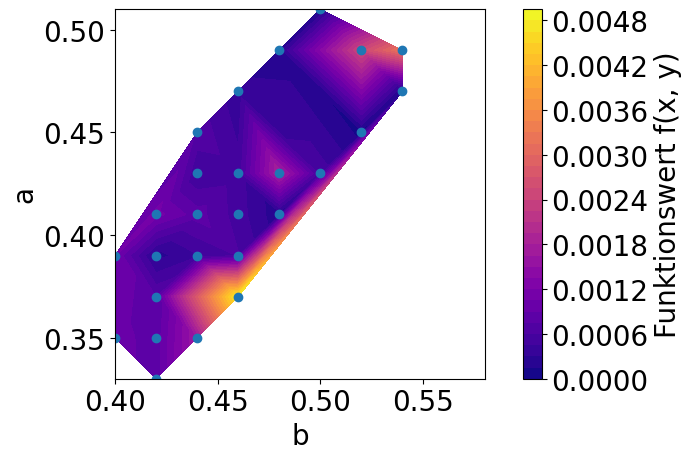

In [181]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes == n_holes_temp)
    z_n_holes_temp = z[n_holes_mask]
    x_n_holes_temp = x[n_holes_mask]
    y_n_holes_temp = y[n_holes_mask]
    n_holes_n_holes_temp = n_holes[n_holes_mask]
    for dist_temp in np.sort(np.unique(z_n_holes_temp)):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        z_mask = (z_n_holes_temp == dist_temp)

        n_holes_all_temp = (n_holes_n_holes_temp[z_mask])
        z_temp = (z_n_holes_temp[z_mask])
        x_temp = (x_n_holes_temp[z_mask])
        y_temp = (y_n_holes_temp[z_mask])

        xa_temp = f_xa[n_holes_mask][z_mask]
        
        Z_temp = quartic_model_with_holes(params_f_xa,x_temp,y_temp,z_temp, n_holes_all_temp)
        Z_diff = np.abs(Z_temp - xa_temp)
    
        triang = tri.Triangulation(x_temp, y_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, Z_diff, cmap='plasma',levels= 40)
        plt.colorbar(label='Funktionswert f(x, y)')
        plt.scatter(x_temp,y_temp)
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

# Xi Ergebnis und Fehler

In [182]:
display(Markdown(
rf"""
$$
\begin{{aligned}}
&{params_f_xi[0]} x^4+ {params_f_xi[1]} y^4 + {params_f_xi[2]} z^4 + {params_f_xi[3]} x^3 y + {params_f_xi[4]} x^3 z \\
    &+ {params_f_xi[5]}y^3 x + {params_f_xi[6]} y^3 z + {params_f_xi[7]} z^3 x + {params_f_xi[8]} z^3 y + {params_f_xi[9]} x^2 y^2\\
    &+ {params_f_xi[10]} x^2 y z + {params_f_xi[11]} x^2 z^2 + {params_f_xi[12]} y^2 x z + {params_f_xi[13]} y^2 z^2 \\
    &+ {params_f_xi[14]} z^2 x y + {params_f_xi[15]} x^3 + {params_f_xi[16]} y^3 + {params_f_xi[17]} z^3 + {params_f_xi[18]} x^2 y\\
    &+ {params_f_xi[19]} x^2 z + {params_f_xi[20]} y^2 x + {params_f_xi[21]} y^2 z + {params_f_xi[22]} z^2 x \\
    &+ {params_f_xi[23]} z^2 y + {params_f_xi[24]} x y z + {params_f_xi[25]} x^2 + {params_f_xi[26]} y^2 + {params_f_xi[27]} z^2\\
    &+ {params_f_xi[28]} x y + {params_f_xi[29]} x z + {params_f_xi[30]} y z + {params_f_xi[31]} x + {params_f_xi[32]} y \\
    &+ {params_f_xi[33]} z + {params_f_xi[34]}
\end{{aligned}}
$$
"""
))


$$
\begin{aligned}
&-6.637577595045209 x^4+ 4.399826832958553 y^4 + 700.7631161755509 z^4 + 2.218666224515995 x^3 y + 59.17104428947771 x^3 z \\
    &+ 9.051780375107418y^3 x + 25.174742504152114 y^3 z + 1819.569444248258 z^3 x + -2606.0051089963786 z^3 y + -18.93454778449161 x^2 y^2\\
    &+ -130.36087945589136 x^2 y z + -303.03406277364945 x^2 z^2 + 255.88070345532532 y^2 x z + -146.19536160282888 y^2 z^2 \\
    &+ 1135.2739630837839 z^2 x y + -58.94646561624556 x^3 + -38.300479420875135 y^3 + -1672.331831102644 z^3 + 155.57975976378805 x^2 y\\
    &+ 685.8173274736561 x^2 z + -276.9560591727562 y^2 x + 228.20414226706845 y^2 z + -6319.598322059474 z^2 x \\
    &+ 8208.681761241507 z^2 y + -2621.9895337321173 x y z + -391.57811753952467 x^2 + -67.48378700566921 y^2 + 678.801507503622 z^2\\
    &+ 1502.6294683348044 x y + 7306.22551877116 x z + -8556.904535343987 y z + -2810.1981851958367 x + 2947.3666279543813 y \\
    &+ 846.7378133111109 z + -552.7825821727702
\end{aligned}
$$


In [183]:
Z_all = []
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])
    
        Z_temp = quartic_model_with_holes(params_f_xi,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
        Z_all.append(Z_temp)

Number of holes is 5 and dist is 1.02
Number of holes is 5 and dist is 1.04
Number of holes is 5 and dist is 1.06
Number of holes is 5 and dist is 1.08
Number of holes is 6 and dist is 1.02
Number of holes is 6 and dist is 1.04
Number of holes is 6 and dist is 1.06
Number of holes is 6 and dist is 1.08
Number of holes is 6 and dist is 1.1
Number of holes is 6 and dist is 1.12
Number of holes is 6 and dist is 1.14


In [184]:
Z_all_array = np.hstack(Z_all)
Z_min = np.min(Z_all_array)
Z_min

np.float64(0.4145240930492946)

In [185]:
Z_max = np.max(Z_all_array)
Z_max

np.float64(0.716206131832223)

In [186]:
norm = mcolors.Normalize(vmin=Z_min, vmax = Z_max)

Number of holes is 5 and dist is 1.02


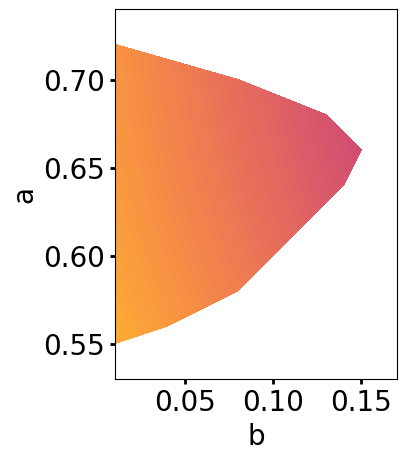

Number of holes is 5 and dist is 1.04


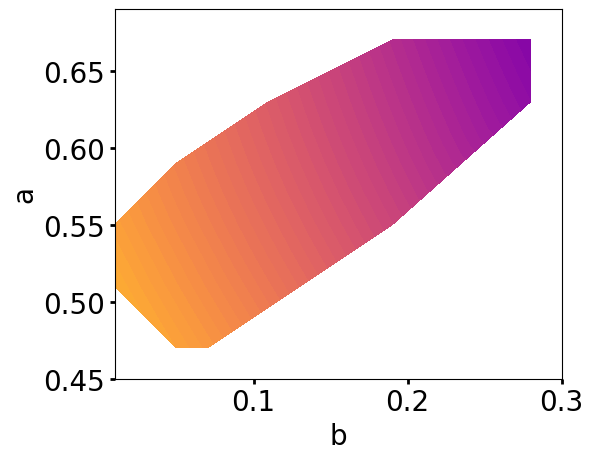

Number of holes is 5 and dist is 1.06


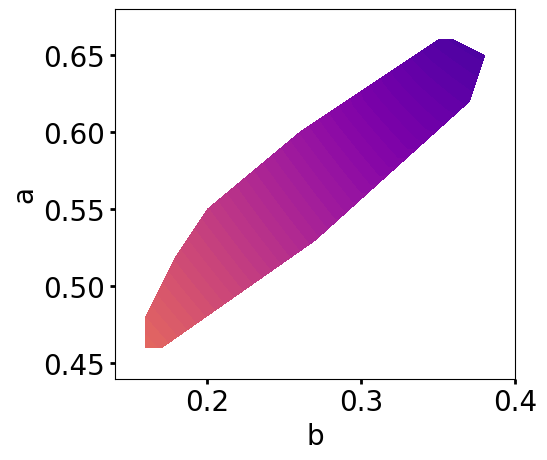

Number of holes is 5 and dist is 1.08


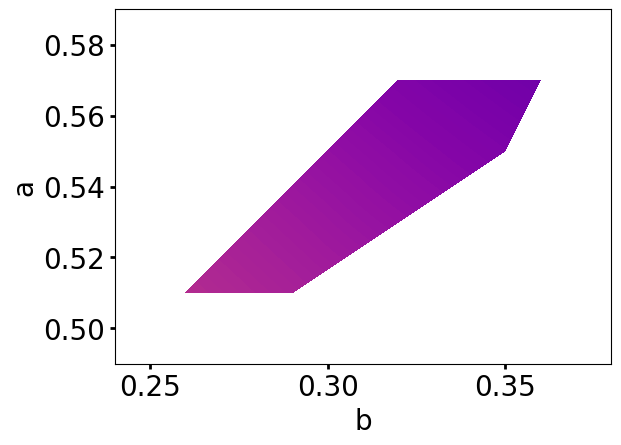

Number of holes is 6 and dist is 1.02


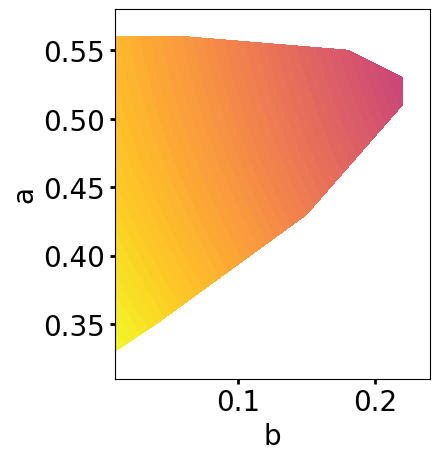

Number of holes is 6 and dist is 1.04


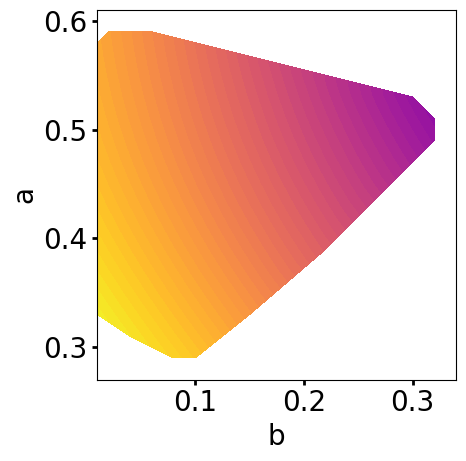

Number of holes is 6 and dist is 1.06


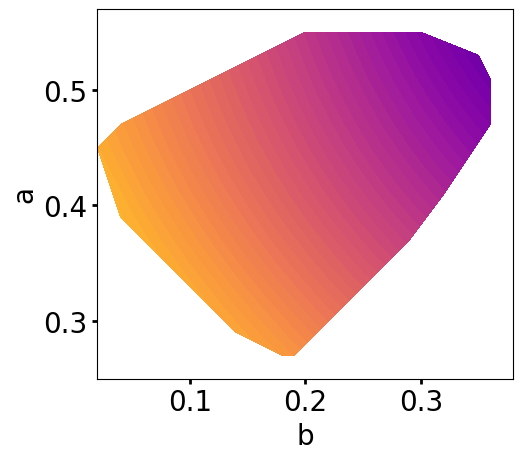

Number of holes is 6 and dist is 1.08


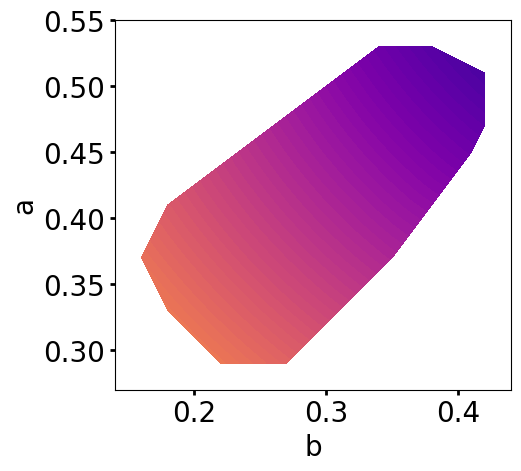

Number of holes is 6 and dist is 1.1


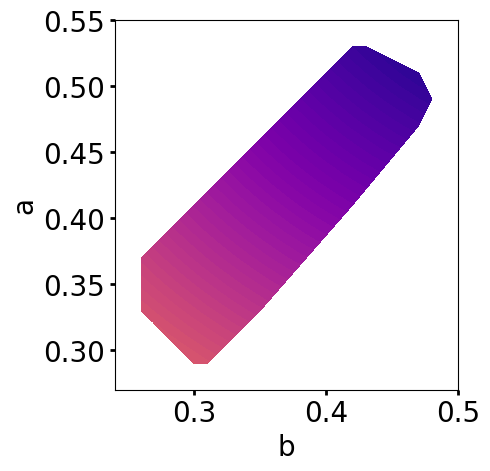

Number of holes is 6 and dist is 1.12


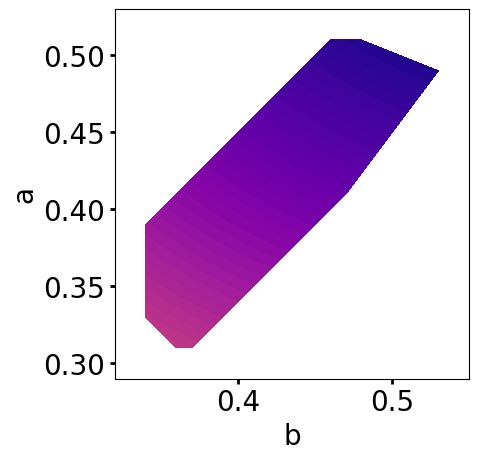

Number of holes is 6 and dist is 1.14


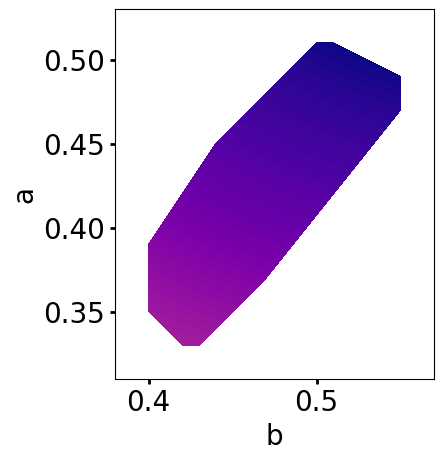

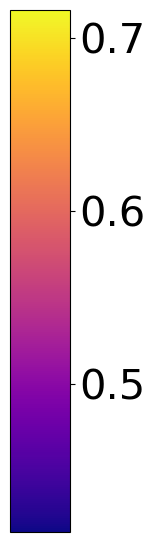

In [187]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])

        Z_temp = quartic_model_with_holes(params_f_xi,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
    
        X,Y = np.meshgrid(np.linspace(min(x_mesh_temp), max(x_mesh_temp), 100), np.linspace(min(y_mesh_temp), max(y_mesh_temp), 100))
        Z_all_temp = quartic_model_with_holes(params_f_xi,X,Y,dist_temp,n_holes_temp)

        Y_scatter = X.T[dist_temp - X.T < Z_all_temp.T]
        X_scatter = Y.T[dist_temp - X.T < Z_all_temp.T]
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        xlim_max = 1.2
        ylim_max = 0.8
        
        alpha12 = np.pi/n_ellipses
        max_length = dist_temp * np.tan(alpha12)-0.0000001
        length_linspace = np.linspace(max_length,0,100, endpoint=True)
        length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

        width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist_temp, length_linspace)
        
        width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

        b_values = np.linspace(x_mesh_temp[np.argmin(y_mesh_temp)], max(x_mesh_temp)+0.5, 100)
        b_values = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values = np.full_like(b_values, np.nan)
        for i, b in enumerate(b_values):
            def condition_no_intersection(a):
                return dist_temp - b - quartic_model_with_holes(params_f_xi,b,a,dist_temp,n_holes_temp)
            try:
                a_values[i] = brentq(condition_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values[i] = np.nan
        
        # Kontur-Plot
        plt.rcParams.update({'font.size':20})
        plt.tick_params(axis='both', width=2)
        plt.tricontourf(triang, Z_temp, cmap='plasma',levels= 40, norm=norm)
        plt.plot(b_values, a_values, 'black')
        plt.fill_between(b_values, a_values, 0, facecolor='None',
            hatch='///',
            edgecolor='black',
            label='invalid / not tested')

        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        if(np.min(x_mesh_temp) <= 0.02):
            plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        else:
            plt.xlim(np.min(x_mesh_temp)-0.02, np.max(x_mesh_temp)+0.02)
        #plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        plt.ylim(np.min(y_mesh_temp)-0.02, np.max(y_mesh_temp)+0.02)
        plt.show()

sm = plt.cm.ScalarMappable(norm=norm,cmap="plasma")
fig = plt.figure(figsize=(3,6))

cax = fig.add_axes([0.4,0.08,0.2,0.87])
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar.ax.tick_params(labelsize=30)


In [188]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])

        Z_temp = quartic_model_with_holes(params_f_xi,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
    
        X,Y = np.meshgrid(np.linspace(min(x_mesh_temp), max(x_mesh_temp), 100), np.linspace(min(y_mesh_temp), max(y_mesh_temp), 100))
        Z_all_temp = quartic_model_with_holes(params_f_xi,X,Y,dist_temp,n_holes_temp)

        Y_scatter = X.T[dist_temp - X.T < Z_all_temp.T]
        X_scatter = Y.T[dist_temp - X.T < Z_all_temp.T]
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        xlim_max = 1.2
        ylim_max = 0.8
        
        alpha12 = np.pi/n_ellipses
        max_length = dist_temp * np.tan(alpha12)-0.0000001
        length_linspace = np.linspace(max_length,0,100, endpoint=True)
        length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

        width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist_temp, length_linspace)
        
        width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

        b_values = np.linspace(x_mesh_temp[np.argmin(y_mesh_temp)], max(x_mesh_temp)+0.5, 100)
        b_values = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values = np.full_like(b_values, np.nan)
        for i, b in enumerate(b_values):
            def condition_no_intersection(a):
                return dist_temp - b - quartic_model_with_holes(params_f_xi,b,a,dist_temp,n_holes_temp)
            try:
                a_values[i] = brentq(condition_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values[i] = np.nan
        
        # Kontur-Plot
        plt.rcParams.update({'font.size':20})
        plt.tick_params(axis='both', width=2)
        plt.tricontourf(triang, Z_temp, cmap='plasma',levels= 40, norm=norm)
        plt.plot(b_values, a_values, 'black')
        plt.fill_between(b_values, a_values, 0, facecolor='None',
            hatch='///',
            edgecolor='black',
            label='invalid / not tested')

        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        if(np.min(x_mesh_temp) <= 0.02):
            plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        else:
            plt.xlim(np.min(x_mesh_temp)-0.02, np.max(x_mesh_temp)+0.02)
        plt.ylim(np.min(y_mesh_temp)-0.02, np.max(y_mesh_temp)+0.02)
        
        os.makedirs("Plots_xi_6_and_5_holes", exist_ok = True)
        filename = f"Plots_xi_6_and_5_holes/Xi_{str(n_holes_temp).replace('.', '_')}_ellipses_distance_{str(dist_temp).replace('.', '_')}.eps"
        print(filename)
        plt.tight_layout()
        plt.savefig(filename,dpi=300)
        plt.close()

sm = plt.cm.ScalarMappable(norm=norm,cmap="plasma")
fig = plt.figure(figsize=(3,6))

cax = fig.add_axes([0.4,0.08,0.2,0.87])
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar.ax.tick_params(labelsize=30)
filename = f"Plots_xi_6_and_5_holes/Xi_colorbar.eps"
print(filename)
plt.savefig(filename,dpi=300)
plt.close()

Number of holes is 5 and dist is 1.02
Plots_xi_6_and_5_holes/Xi_5_ellipses_distance_1_02.eps
Number of holes is 5 and dist is 1.04
Plots_xi_6_and_5_holes/Xi_5_ellipses_distance_1_04.eps
Number of holes is 5 and dist is 1.06
Plots_xi_6_and_5_holes/Xi_5_ellipses_distance_1_06.eps
Number of holes is 5 and dist is 1.08
Plots_xi_6_and_5_holes/Xi_5_ellipses_distance_1_08.eps
Number of holes is 6 and dist is 1.02
Plots_xi_6_and_5_holes/Xi_6_ellipses_distance_1_02.eps
Number of holes is 6 and dist is 1.04
Plots_xi_6_and_5_holes/Xi_6_ellipses_distance_1_04.eps
Number of holes is 6 and dist is 1.06
Plots_xi_6_and_5_holes/Xi_6_ellipses_distance_1_06.eps
Number of holes is 6 and dist is 1.08
Plots_xi_6_and_5_holes/Xi_6_ellipses_distance_1_08.eps
Number of holes is 6 and dist is 1.1
Plots_xi_6_and_5_holes/Xi_6_ellipses_distance_1_1.eps
Number of holes is 6 and dist is 1.12
Plots_xi_6_and_5_holes/Xi_6_ellipses_distance_1_12.eps
Number of holes is 6 and dist is 1.14
Plots_xi_6_and_5_holes/Xi_6_ellips

Start 5
Number of holes is 5 and dist is 1.02


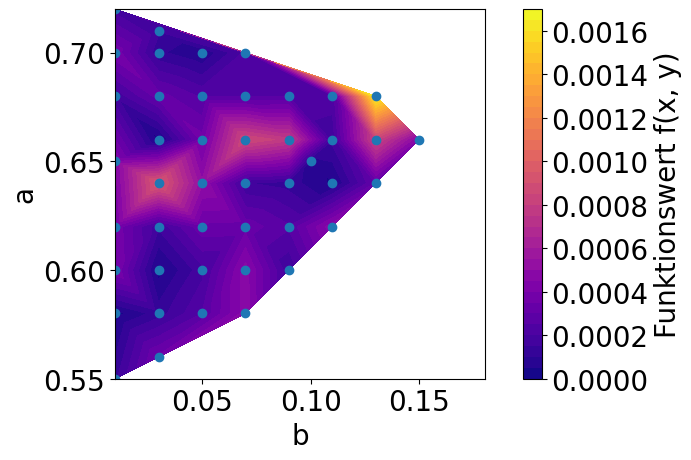

Number of holes is 5 and dist is 1.04


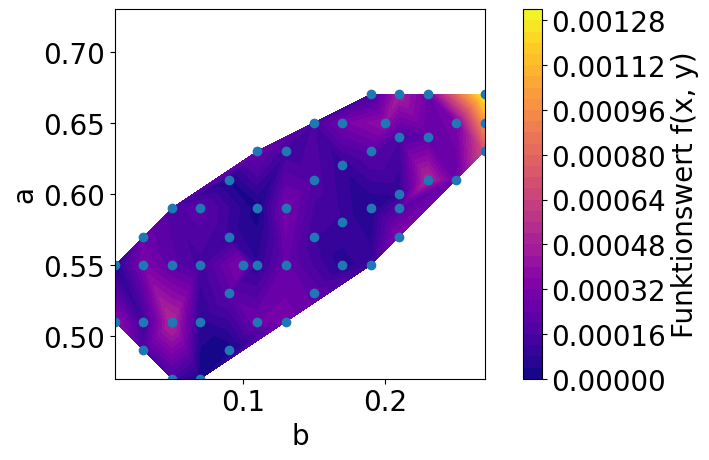

Number of holes is 5 and dist is 1.06


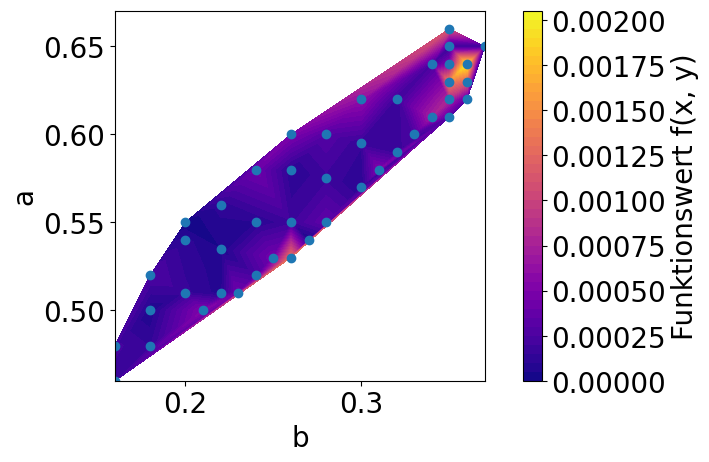

Number of holes is 5 and dist is 1.08


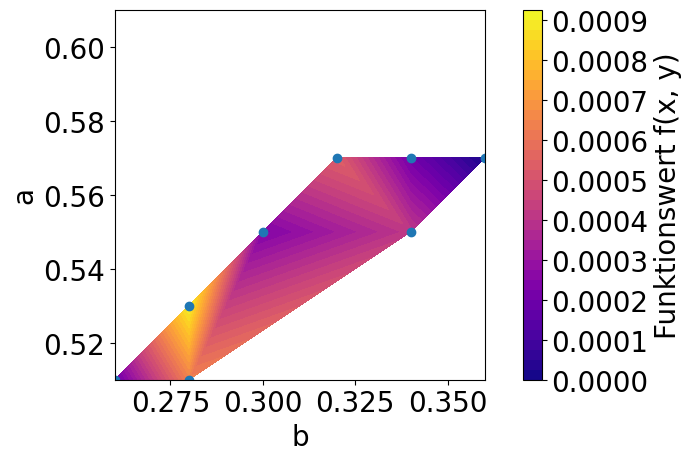

Start 6
Number of holes is 6 and dist is 1.02


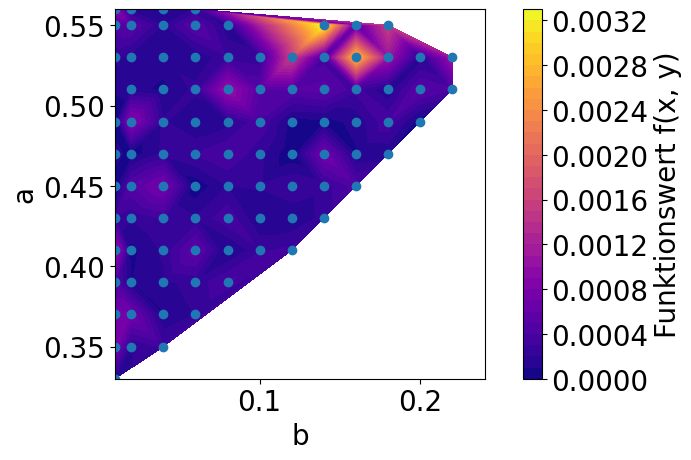

Number of holes is 6 and dist is 1.04


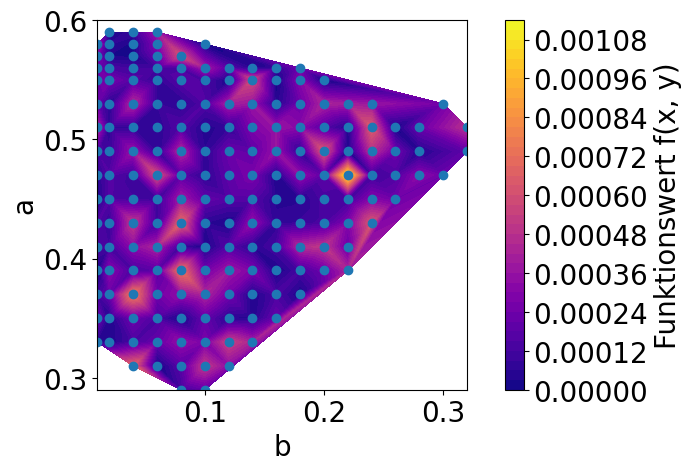

Number of holes is 6 and dist is 1.06


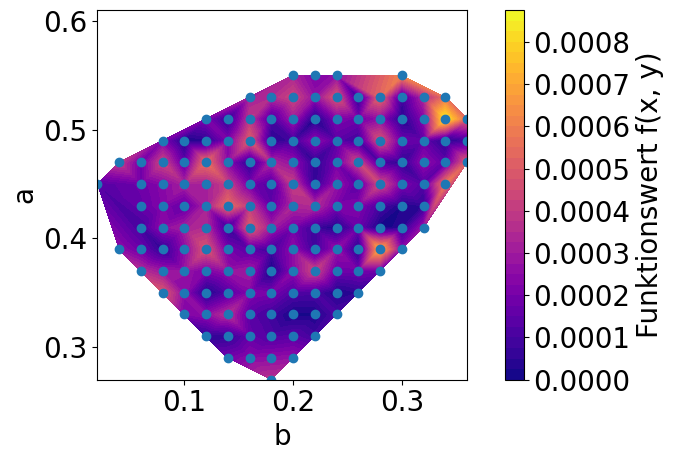

Number of holes is 6 and dist is 1.08


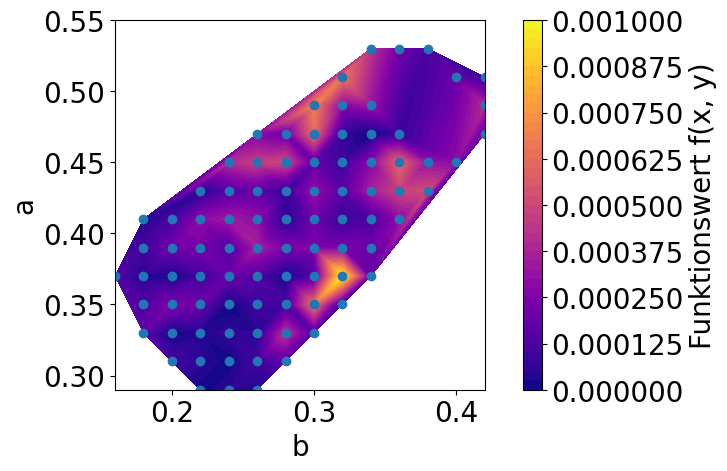

Number of holes is 6 and dist is 1.1


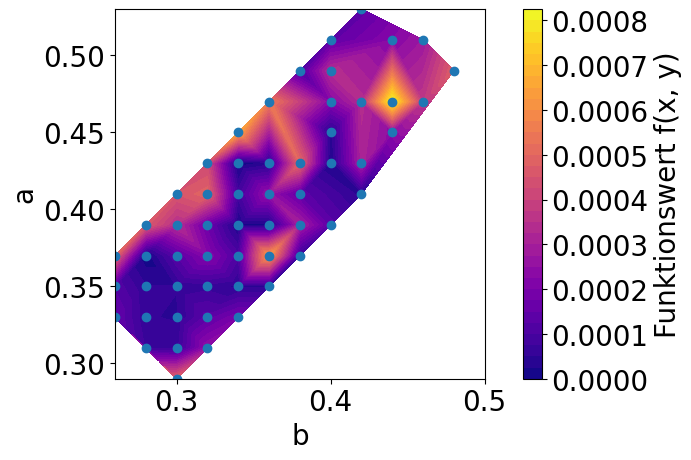

Number of holes is 6 and dist is 1.12


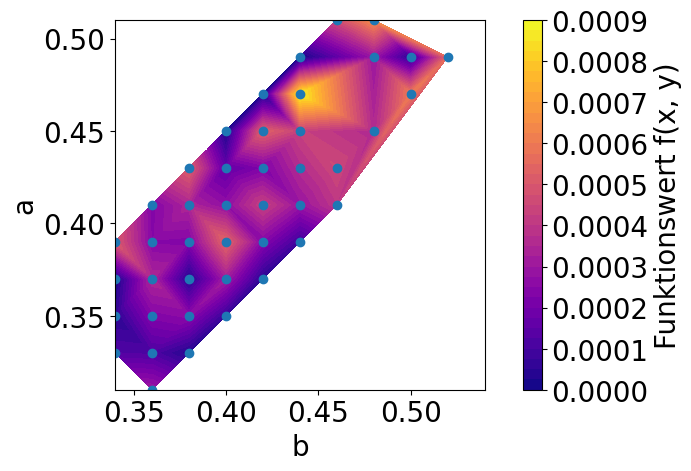

Number of holes is 6 and dist is 1.14


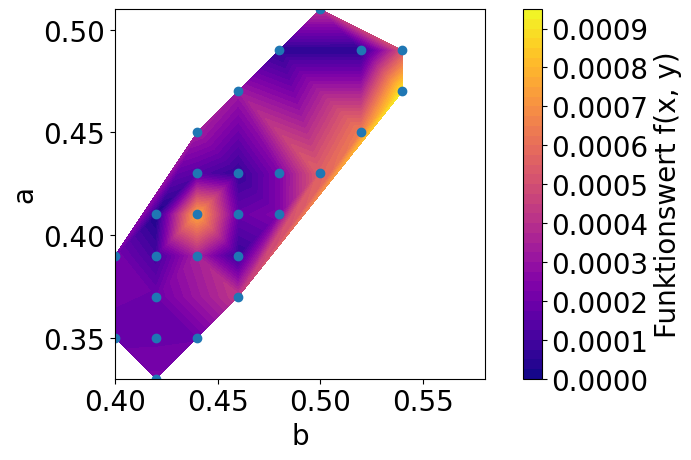

In [189]:
for n_holes_temp in np.unique(n_holes_mesh):
    print(f"Start {n_holes_temp}")
    n_holes_mask = (n_holes == n_holes_temp)
    z_n_holes_temp = z[n_holes_mask]
    x_n_holes_temp = x[n_holes_mask]
    y_n_holes_temp = y[n_holes_mask]
    n_holes_n_holes_temp = n_holes[n_holes_mask]
    for dist_temp in np.sort(np.unique(z_n_holes_temp)):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        z_mask = (z_n_holes_temp == dist_temp)

        n_holes_all_temp = (n_holes_n_holes_temp[z_mask])
        z_temp = (z_n_holes_temp[z_mask])
        x_temp = (x_n_holes_temp[z_mask])
        y_temp = (y_n_holes_temp[z_mask])

        xi_temp = f_xi[n_holes_mask][z_mask]
        
        Z_temp = quartic_model_with_holes(params_f_xi,x_temp,y_temp,z_temp, n_holes_all_temp)
        Z_diff = np.abs(Z_temp - xi_temp)
    
        triang = tri.Triangulation(x_temp, y_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, Z_diff, cmap='plasma',levels= 40)
        plt.colorbar(label='Funktionswert f(x, y)')
        plt.scatter(x_temp,y_temp)
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

# Ratio Ergebnis und Fehler

In [190]:
display(Markdown(
rf"""
$$
\begin{{aligned}}
&{params_f_ratio[0]} x^4+ {params_f_ratio[1]} y^4 + {params_f_ratio[2]} z^4 + {params_f_ratio[3]} x^3 y + {params_f_ratio[4]} x^3 z \\
    &+ {params_f_ratio[5]}y^3 x + {params_f_ratio[6]} y^3 z + {params_f_ratio[7]} z^3 x + {params_f_ratio[8]} z^3 y + {params_f_ratio[9]} x^2 y^2\\
    &+ {params_f_ratio[10]} x^2 y z + {params_f_ratio[11]} x^2 z^2 + {params_f_ratio[12]} y^2 x z + {params_f_ratio[13]} y^2 z^2 \\
    &+ {params_f_ratio[14]} z^2 x y + {params_f_ratio[15]} x^3 + {params_f_ratio[16]} y^3 + {params_f_ratio[17]} z^3 + {params_f_ratio[18]} x^2 y\\
    &+ {params_f_ratio[19]} x^2 z + {params_f_ratio[20]} y^2 x + {params_f_ratio[21]} y^2 z + {params_f_ratio[22]} z^2 x \\
    &+ {params_f_ratio[23]} z^2 y + {params_f_ratio[24]} x y z + {params_f_ratio[25]} x^2 + {params_f_ratio[26]} y^2 + {params_f_ratio[27]} z^2\\
    &+ {params_f_ratio[28]} x y + {params_f_ratio[29]} x z + {params_f_ratio[30]} y z + {params_f_ratio[31]} x + {params_f_ratio[32]} y \\
    &+ {params_f_ratio[33]} z + {params_f_ratio[34]}
\end{{aligned}}
$$
"""
))


$$
\begin{aligned}
&1.640003301222296 x^4+ 90.34787089257864 y^4 + -18684.58296907515 z^4 + -72.53559571993152 x^3 y + -492.00480982642995 x^3 z \\
    &+ -108.73458022553919y^3 x + 1465.1948731613559 y^3 z + -75775.41004484883 z^3 x + 87131.72461737771 z^3 y + 114.55783074688439 x^2 y^2\\
    &+ 2021.1634698080384 x^2 y z + 11642.305429908067 x^2 z^2 + -2425.2382511713167 y^2 x z + 17880.8519085841 y^2 z^2 \\
    &+ -25933.516925972075 z^2 x y + 565.1087485933774 x^3 + -1732.6066128723116 y^3 + 43786.975585461056 z^3 + -2242.486801523588 x^2 y\\
    &+ -25284.329806916143 x^2 z + 2716.6950706378057 y^2 x + -39581.418317964846 y^2 z + 248581.63360474166 z^2 x \\
    &+ -289639.9844549963 z^2 y + 56456.910357719375 x y z + 13743.430311863222 x^2 + 22005.345807060876 y^2 + -10724.915050792672 z^2\\
    &+ -30779.29419629764 x y + -271840.0012275626 x z + 321049.64255851816 y z + 99106.84485868976 x + -118697.95682800458 y \\
    &+ -35952.96907230371 z + 21605.289644719014
\end{aligned}
$$


In [191]:
Z_all = []
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])
    
        Z_temp = quartic_model_with_holes(params_f_ratio,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
        Z_all.append(Z_temp)

Number of holes is 5 and dist is 1.02
Number of holes is 5 and dist is 1.04
Number of holes is 5 and dist is 1.06
Number of holes is 5 and dist is 1.08
Number of holes is 6 and dist is 1.02
Number of holes is 6 and dist is 1.04
Number of holes is 6 and dist is 1.06
Number of holes is 6 and dist is 1.08
Number of holes is 6 and dist is 1.1
Number of holes is 6 and dist is 1.12
Number of holes is 6 and dist is 1.14


In [192]:
Z_all_array = np.hstack(Z_all)
Z_min = np.min(Z_all_array)
Z_min

np.float64(0.6953862591471989)

In [193]:
Z_max = np.max(Z_all_array)
Z_max

np.float64(0.886161364876898)

In [194]:
norm = mcolors.Normalize(vmin=Z_min, vmax = Z_max)

Number of holes is 5 and dist is 1.02


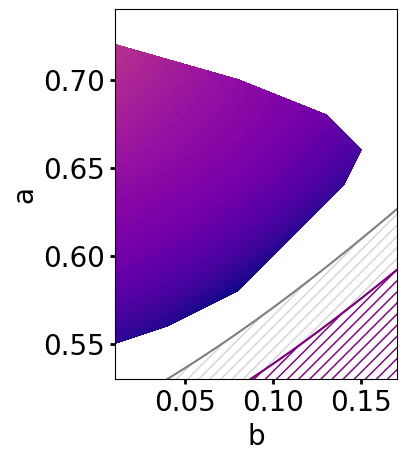

Number of holes is 5 and dist is 1.04


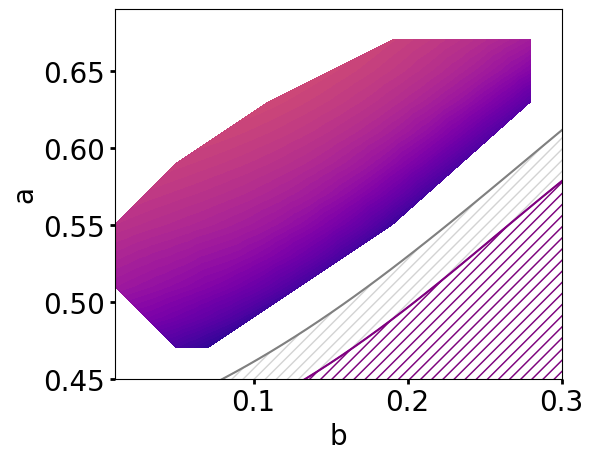

Number of holes is 5 and dist is 1.06


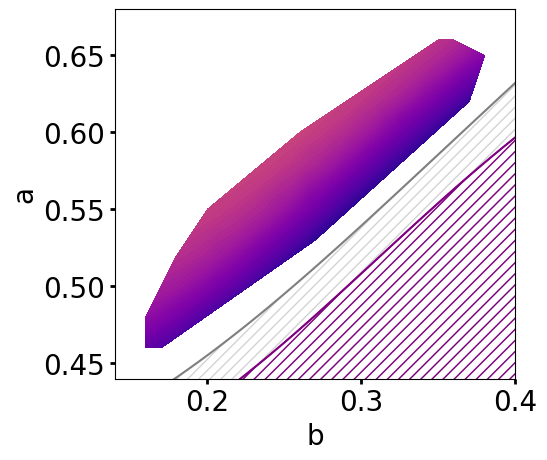

Number of holes is 5 and dist is 1.08


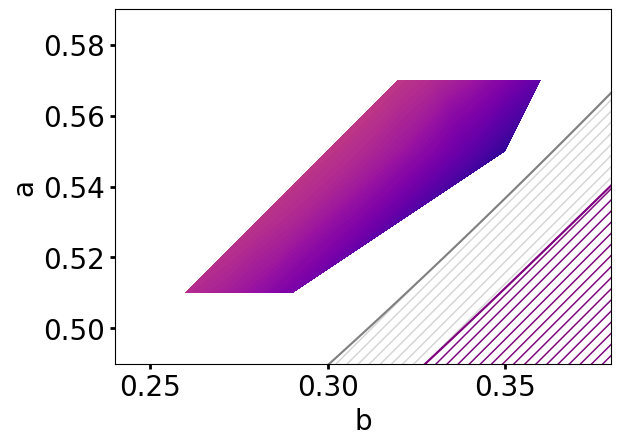

Number of holes is 6 and dist is 1.02


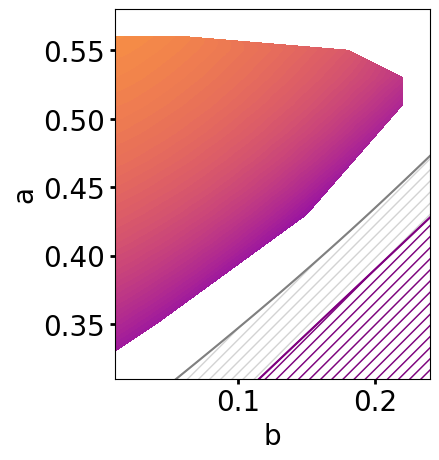

Number of holes is 6 and dist is 1.04


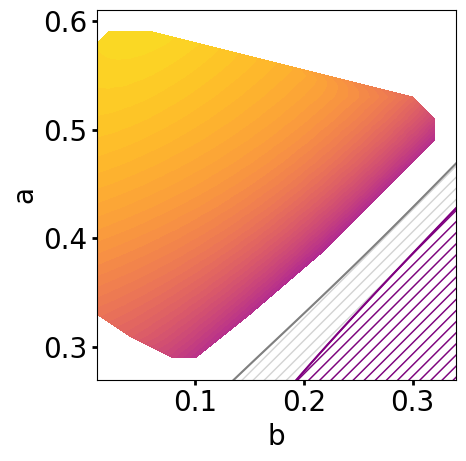

Number of holes is 6 and dist is 1.06


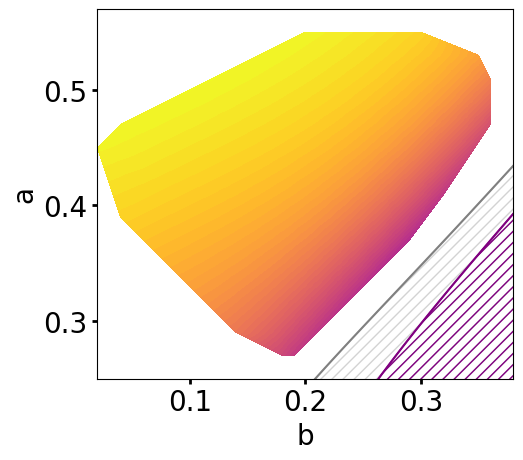

Number of holes is 6 and dist is 1.08


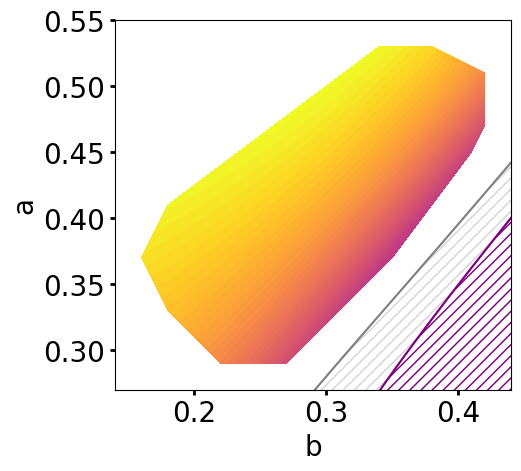

Number of holes is 6 and dist is 1.1


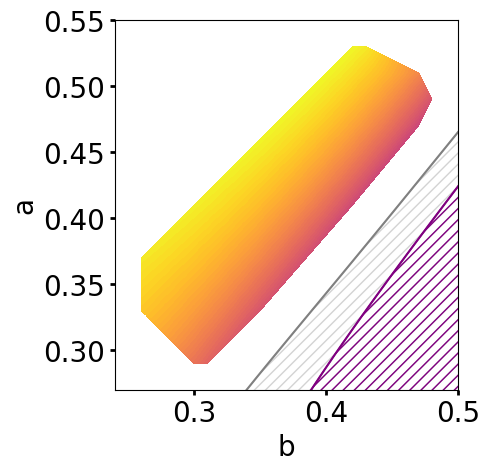

Number of holes is 6 and dist is 1.12


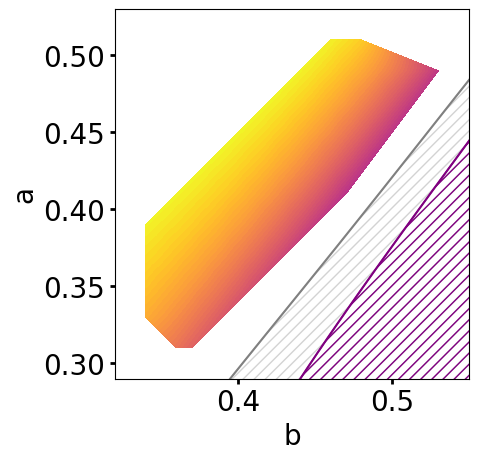

Number of holes is 6 and dist is 1.14


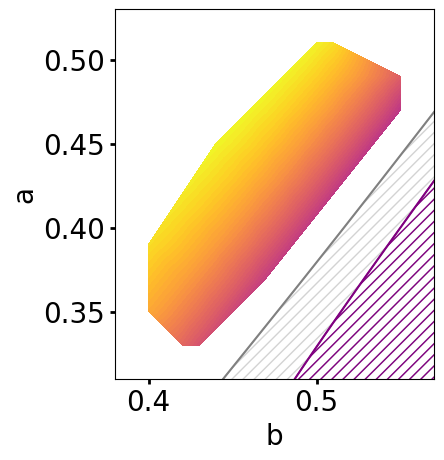

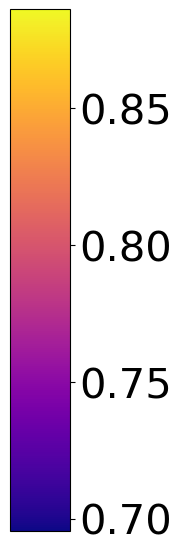

In [195]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])

        Z_temp = quartic_model_with_holes(params_f_ratio,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
    
        X,Y = np.meshgrid(np.linspace(min(x_mesh_temp), max(x_mesh_temp), 100), np.linspace(min(y_mesh_temp), max(y_mesh_temp), 100))
        Z_all_temp = quartic_model_with_holes(params_f_ratio,X,Y,dist_temp,n_holes_temp)

        Y_scatter = X[(Z_all_temp < 1-2/n_holes_temp) | (Z_all_temp > 1)]
        X_scatter = Y[(Z_all_temp < 1-2/n_holes_temp) | (Z_all_temp > 1)]
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        xlim_max = 1.2
        ylim_max = 0.8
        
        alpha12 = np.pi/n_ellipses
        max_length = dist_temp * np.tan(alpha12)-0.0000001
        length_linspace = np.linspace(max_length,0,100, endpoint=True)
        length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

        width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist_temp, length_linspace)
        
        width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

        b_values = np.linspace(x_mesh_temp[np.argmin(y_mesh_temp)], max(x_mesh_temp)+0.5, 100)
        b_values = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values = np.full_like(b_values, np.nan)
        for i, b in enumerate(b_values):
            def condition_no_intersection(a):
                return dist_temp - b - quartic_model_with_holes(params_f_xa,b,a,dist_temp,n_holes_temp)

            try:
                a_values[i] = brentq(condition_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values[i] = np.nan
        
        b_values_hyp = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values_hyp = np.full_like(b_values_hyp, np.nan)
        for i, b in enumerate(b_values_hyp):
            def condition_hypotrochoid_no_intersection(a):
                return 1-2/n_holes_temp - quartic_model_with_holes(params_f_ratio,b,a,dist_temp,n_holes_temp)
            try:
                a_values_hyp[i] = brentq(condition_hypotrochoid_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values_hyp[i] = np.nan
        
        # Kontur-Plot
        plt.rcParams.update({'font.size':20})
        plt.tick_params(axis='both', width=2)
        plt.tricontourf(triang, Z_temp, cmap='plasma',levels= 40, norm=norm)
        plt.plot(b_values, a_values, 'grey')
        plt.fill_between(b_values, a_values, 0, facecolor='None',
            hatch='///',
            edgecolor='lightgray',
            label='invalid / not tested'
            )

        plt.plot(b_values_hyp, a_values_hyp, 'purple')
        plt.fill_between(b_values_hyp, a_values_hyp, 0, facecolor='None',
            hatch='///',
            edgecolor='purple',
            label='invalid / not tested')

        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        if(np.min(x_mesh_temp) <= 0.02):
            plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        else:
            plt.xlim(np.min(x_mesh_temp)-0.02, np.max(x_mesh_temp)+0.02)
        plt.ylim(np.min(y_mesh_temp)-0.02, np.max(y_mesh_temp)+0.02)
        plt.show()

sm = plt.cm.ScalarMappable(norm=norm,cmap="plasma")
fig = plt.figure(figsize=(3,6))

cax = fig.add_axes([0.4,0.08,0.2,0.87])
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar.ax.tick_params(labelsize=30)


In [196]:
for n_holes_temp in np.unique(n_holes_mesh):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])

        Z_temp = quartic_model_with_holes(params_f_ratio,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
    
        X,Y = np.meshgrid(np.linspace(min(x_mesh_temp), max(x_mesh_temp), 100), np.linspace(min(y_mesh_temp), max(y_mesh_temp), 100))
        Z_all_temp = quartic_model_with_holes(params_f_ratio,X,Y,dist_temp,n_holes_temp)

        Y_scatter = X[(Z_all_temp < 1-2/n_holes_temp) | (Z_all_temp > 1)]
        X_scatter = Y[(Z_all_temp < 1-2/n_holes_temp) | (Z_all_temp > 1)]
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        xlim_max = 1.2
        ylim_max = 0.8
        
        alpha12 = np.pi/n_ellipses
        max_length = dist_temp * np.tan(alpha12)-0.0000001
        length_linspace = np.linspace(max_length,0,100, endpoint=True)
        length_full_plot = np.concatenate((length_linspace, np.zeros((100))))

        width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist_temp, length_linspace)
        
        width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

        b_values = np.linspace(x_mesh_temp[np.argmin(y_mesh_temp)], max(x_mesh_temp)+0.5, 100)
        b_values = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values = np.full_like(b_values, np.nan)
        for i, b in enumerate(b_values):
            def condition_no_intersection(a):
                return dist_temp - b - quartic_model_with_holes(params_f_xa,b,a,dist_temp,n_holes_temp)
            try:
                a_values[i] = brentq(condition_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values[i] = np.nan
        
        b_values_hyp = np.linspace(np.min(x_mesh_temp), max(x_mesh_temp)+0.5, 100)
        a_values_hyp = np.full_like(b_values_hyp, np.nan)
        for i, b in enumerate(b_values_hyp):
            def condition_hypotrochoid_no_intersection(a):
                return 1-2/n_holes_temp - quartic_model_with_holes(params_f_ratio,b,a,dist_temp,n_holes_temp)
            try:
                a_values_hyp[i] = brentq(condition_hypotrochoid_no_intersection, -0.01, max(y_mesh_temp))
            except:
                a_values_hyp[i] = np.nan
        
        # Kontur-Plot
        plt.rcParams.update({'font.size':20})
        plt.tick_params(axis='both', width=2)
        plt.tricontourf(triang, Z_temp, cmap='plasma',levels= 40, norm=norm)
        plt.plot(b_values, a_values, 'gray')
        plt.fill_between(b_values, a_values, 0, facecolor='None',
            hatch='///',
            edgecolor='lightgray',
            label='invalid / not tested'
            )

        plt.plot(b_values_hyp, a_values_hyp, 'purple')
        plt.fill_between(b_values_hyp, a_values_hyp, 0, facecolor='None',
            hatch='///',
            edgecolor='purple',
            label='invalid / not tested')

        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        if(np.min(x_mesh_temp) <= 0.02):
            plt.xlim(np.min(x_mesh_temp), np.max(x_mesh_temp)+0.02)
        else:
            plt.xlim(np.min(x_mesh_temp)-0.02, np.max(x_mesh_temp)+0.02)
        plt.ylim(np.min(y_mesh_temp)-0.02, np.max(y_mesh_temp)+0.02)
        
        os.makedirs("Plots_ratio_6_and_5_holes", exist_ok = True)
        filename = f"Plots_ratio_6_and_5_holes/Ratio_{str(n_holes_temp).replace('.', '_')}_ellipses_distance_{str(dist_temp).replace('.', '_')}.eps"
        print(filename)
        plt.tight_layout()
        plt.savefig(filename,dpi=300)
        plt.close()
sm = plt.cm.ScalarMappable(norm=norm,cmap="plasma")
fig = plt.figure(figsize=(3,6))

cax = fig.add_axes([0.4,0.08,0.2,0.87])
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar = fig.colorbar(sm,cax=cax,orientation="vertical")
cbar.ax.tick_params(labelsize=30)
filename = f"Plots_ratio_6_and_5_holes/Ratio_colorbar.eps"
print(filename)
plt.savefig(filename,dpi=300)
plt.close()


Number of holes is 5 and dist is 1.02
Plots_ratio_6_and_5_holes/Ratio_5_ellipses_distance_1_02.eps
Number of holes is 5 and dist is 1.04
Plots_ratio_6_and_5_holes/Ratio_5_ellipses_distance_1_04.eps
Number of holes is 5 and dist is 1.06
Plots_ratio_6_and_5_holes/Ratio_5_ellipses_distance_1_06.eps
Number of holes is 5 and dist is 1.08
Plots_ratio_6_and_5_holes/Ratio_5_ellipses_distance_1_08.eps
Number of holes is 6 and dist is 1.02
Plots_ratio_6_and_5_holes/Ratio_6_ellipses_distance_1_02.eps
Number of holes is 6 and dist is 1.04
Plots_ratio_6_and_5_holes/Ratio_6_ellipses_distance_1_04.eps
Number of holes is 6 and dist is 1.06
Plots_ratio_6_and_5_holes/Ratio_6_ellipses_distance_1_06.eps
Number of holes is 6 and dist is 1.08
Plots_ratio_6_and_5_holes/Ratio_6_ellipses_distance_1_08.eps
Number of holes is 6 and dist is 1.1
Plots_ratio_6_and_5_holes/Ratio_6_ellipses_distance_1_1.eps
Number of holes is 6 and dist is 1.12
Plots_ratio_6_and_5_holes/Ratio_6_ellipses_distance_1_12.eps
Number of ho

Start 5
Number of holes is 5 and dist is 1.02


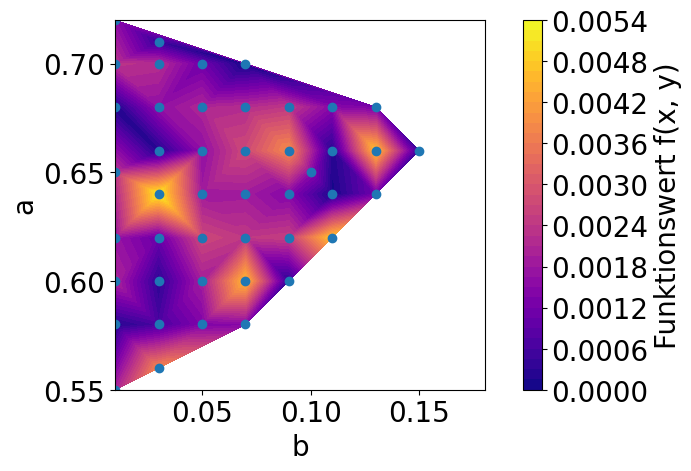

Number of holes is 5 and dist is 1.04


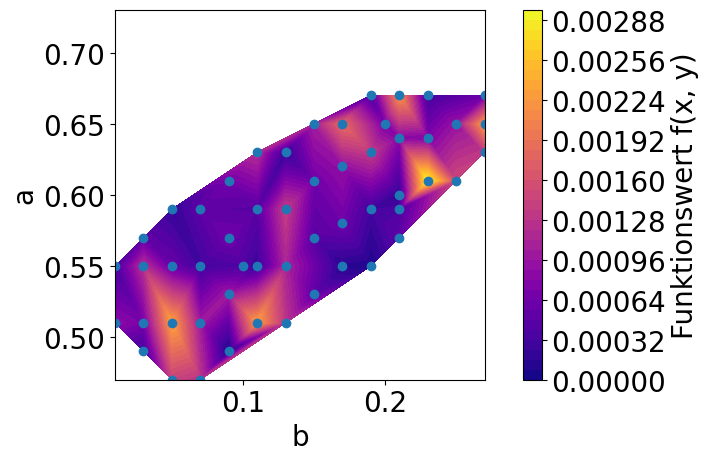

Number of holes is 5 and dist is 1.06


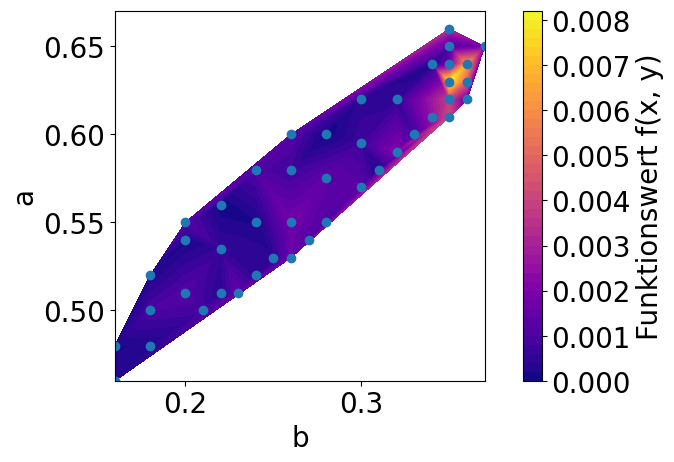

Number of holes is 5 and dist is 1.08


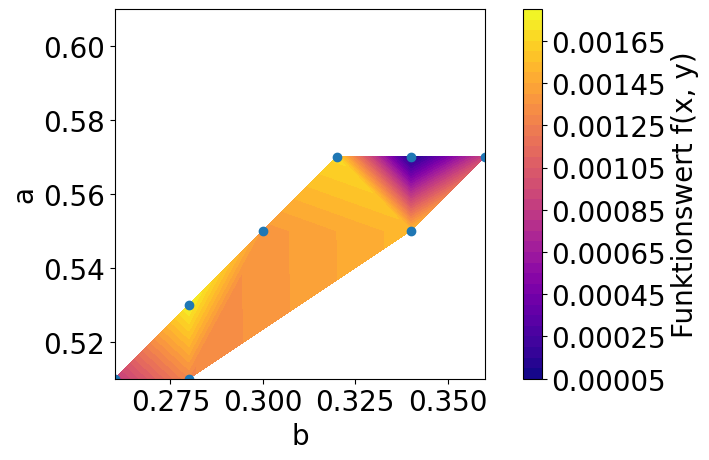

Start 6
Number of holes is 6 and dist is 1.02


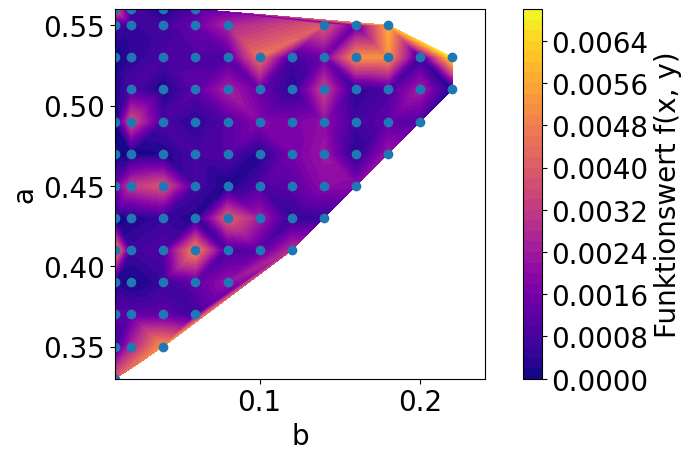

Number of holes is 6 and dist is 1.04


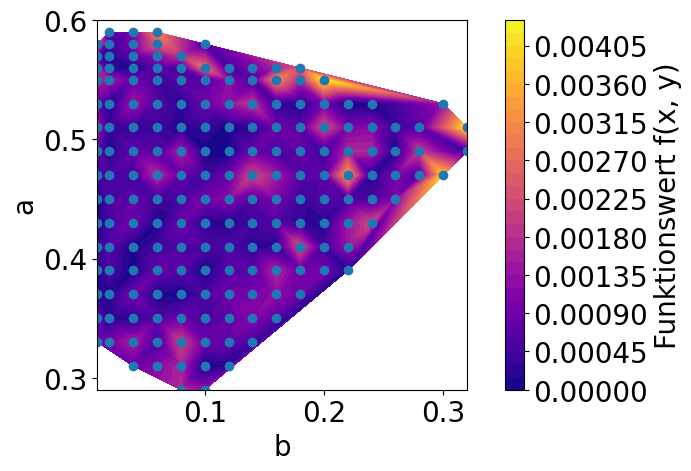

Number of holes is 6 and dist is 1.06


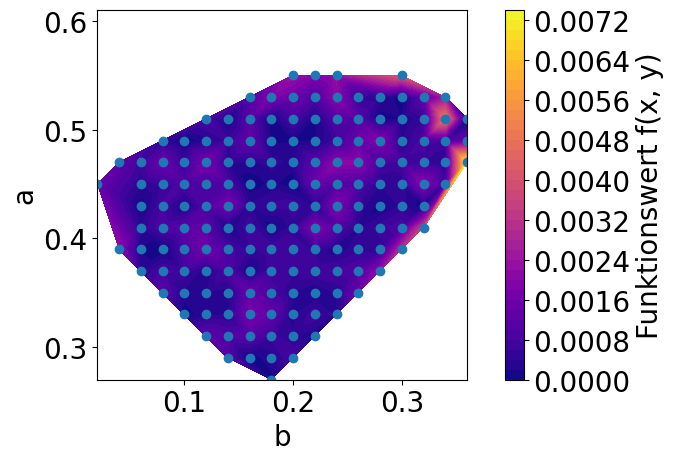

Number of holes is 6 and dist is 1.08


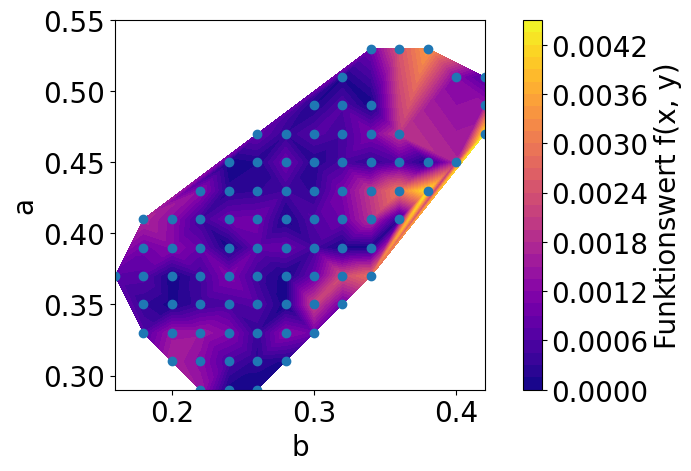

Number of holes is 6 and dist is 1.1


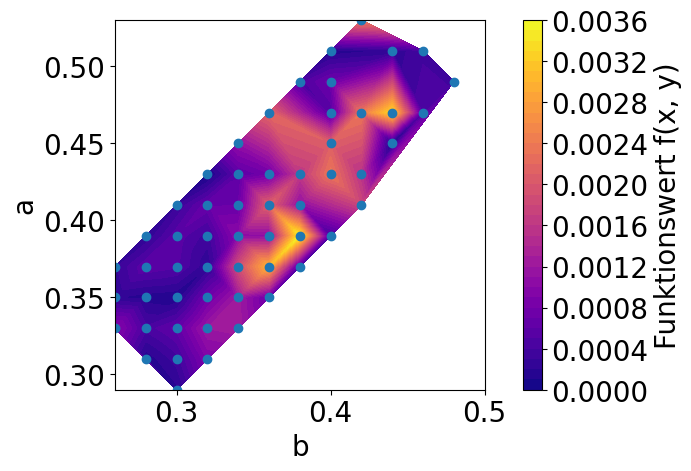

Number of holes is 6 and dist is 1.12


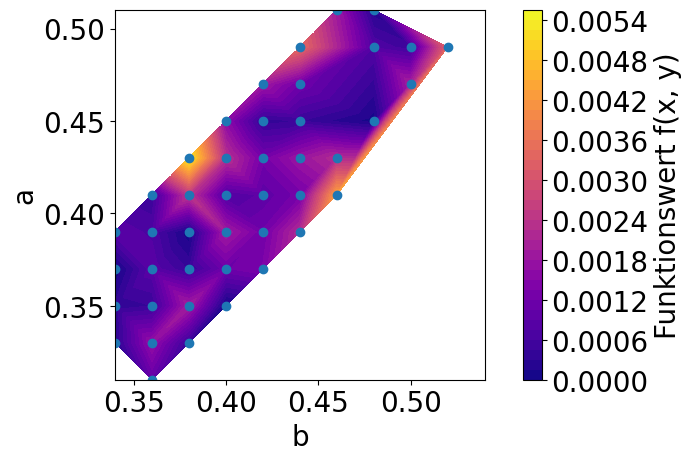

Number of holes is 6 and dist is 1.14


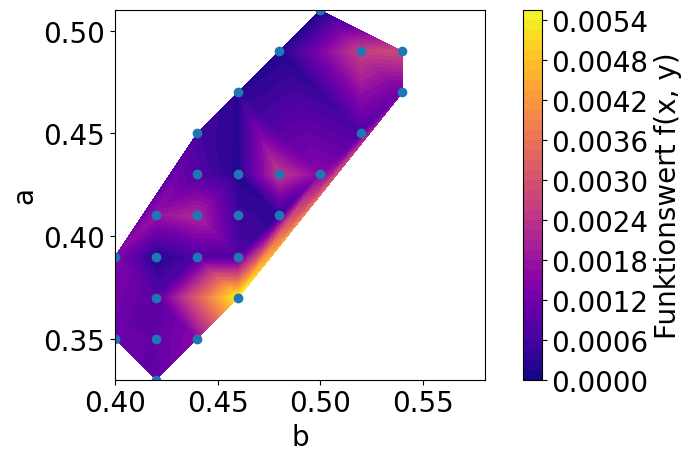

In [197]:
for n_holes_temp in np.unique(n_holes_mesh):
    print(f"Start {n_holes_temp}")
    n_holes_mask = (n_holes == n_holes_temp)
    z_n_holes_temp = z[n_holes_mask]
    x_n_holes_temp = x[n_holes_mask]
    y_n_holes_temp = y[n_holes_mask]
    n_holes_n_holes_temp = n_holes[n_holes_mask]
    for dist_temp in np.sort(np.unique(z_n_holes_temp)):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        z_mask = (z_n_holes_temp == dist_temp)

        n_holes_all_temp = (n_holes_n_holes_temp[z_mask])
        z_temp = (z_n_holes_temp[z_mask])
        x_temp = (x_n_holes_temp[z_mask])
        y_temp = (y_n_holes_temp[z_mask])

        ratio_temp = f_ratio[n_holes_mask][z_mask]

        Z_temp = quartic_model_with_holes(params_f_ratio,x_temp,y_temp,z_temp, n_holes_all_temp)
        Z_diff = np.abs(Z_temp - ratio_temp)
    
        triang = tri.Triangulation(x_temp, y_temp)
        
        # Kontur-Plot
        plt.tricontourf(triang, Z_diff, cmap='plasma',levels= 40)
        plt.colorbar(label='Funktionswert f(x, y)')
        plt.scatter(x_temp,y_temp)
        plt.xlabel('b')
        plt.ylabel('a')
        plt.axis('square')
        plt.show()

# Calculate max distance between nodal line and ellipses

Number of holes is 5 and dist is 1.02


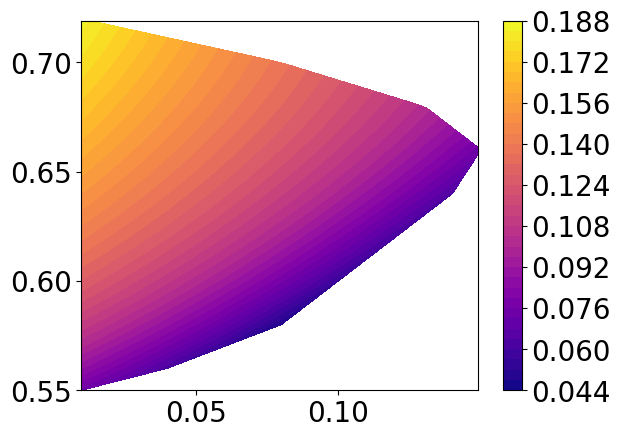

0.18543857643613593
0.18543857643613593
Number of holes is 5 and dist is 1.04


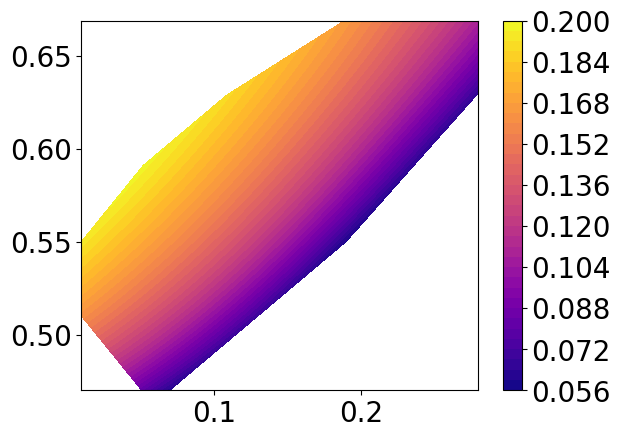

0.19784380101435828
0.19784380101435828
Number of holes is 5 and dist is 1.06


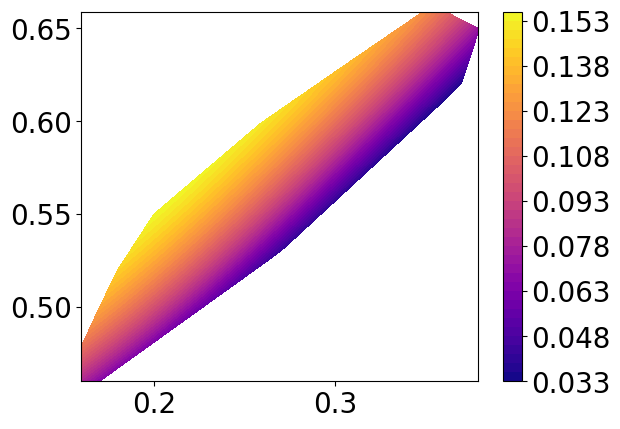

0.155597037038533
Number of holes is 5 and dist is 1.08


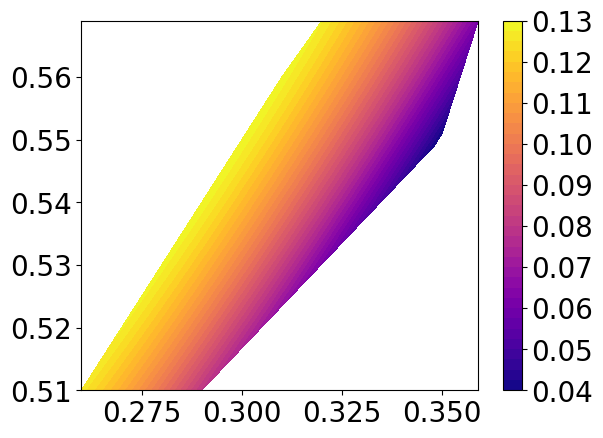

0.12963138690707277
[[1.04  0.052 0.591]
 [0.    0.    0.   ]]
Number of holes is 6 and dist is 1.02


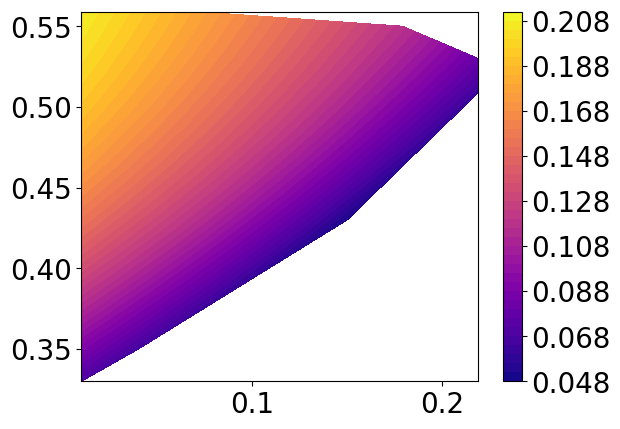

0.20814642850542442
0.20814642850542442
Number of holes is 6 and dist is 1.04


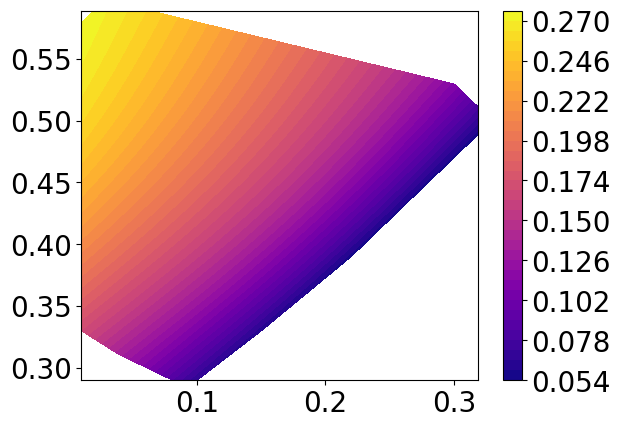

0.2752737651765347
0.2752737651765347
Number of holes is 6 and dist is 1.06


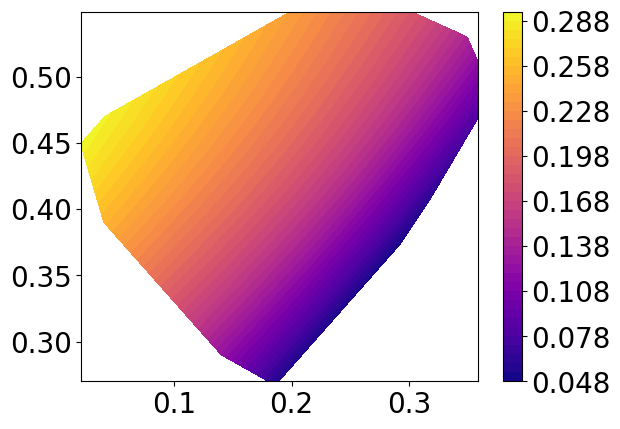

0.2918404133045116
0.2918404133045116
Number of holes is 6 and dist is 1.08


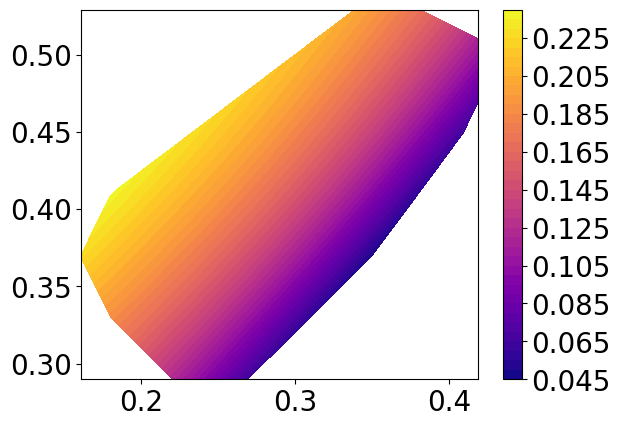

0.2373182650539093
Number of holes is 6 and dist is 1.1


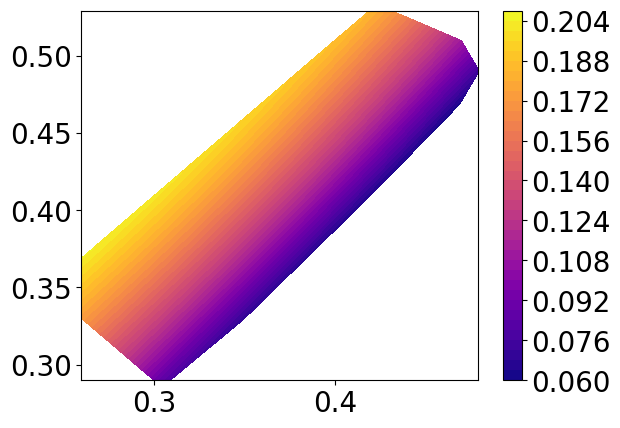

0.20435576836811387
Number of holes is 6 and dist is 1.12


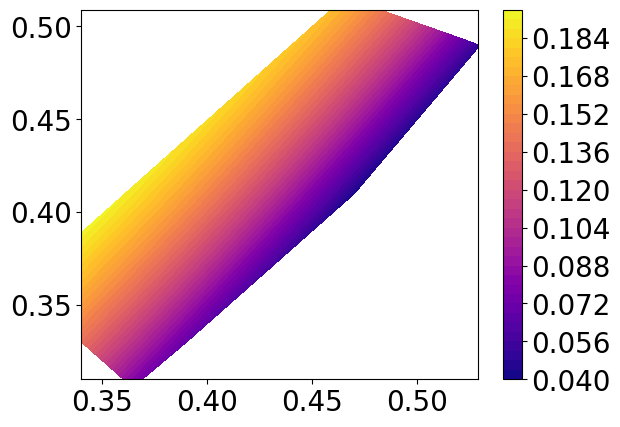

0.1942446962068789
Number of holes is 6 and dist is 1.14


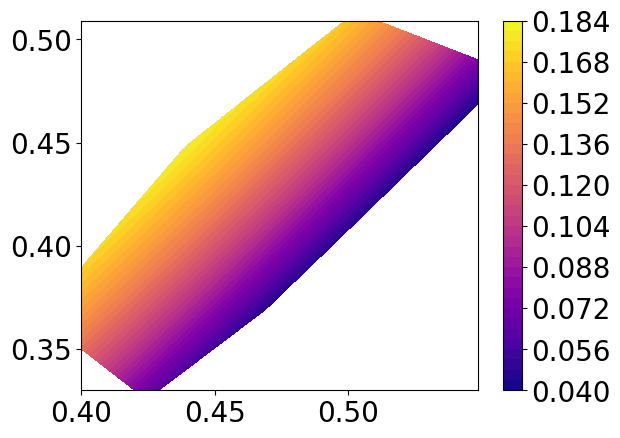

0.18015814828593268
[[1.04  0.052 0.591]
 [1.06  0.021 0.45 ]]


In [199]:
n_differnt_amount_of_holes = len(np.unique(n_holes_mesh))
max_dist_ellipses_nodal_line_n_holes = np.zeros(n_differnt_amount_of_holes)
dist_x_y_max_dist_n_holes = np.zeros((n_differnt_amount_of_holes,3))
for i_holes_temp, n_holes_temp in enumerate(np.unique(n_holes_mesh)):
    n_holes_mask = (n_holes_mesh == n_holes_temp)
    dist_n_holes_temp = dist_mesh[n_holes_mask]
    x_n_holes_temp = x_mesh[n_holes_mask]
    y_n_holes_temp = y_mesh[n_holes_mask]
    n_holes_n_holes_temp = n_holes_mesh[n_holes_mask]
    max_dist_ellipses_nodal_line = 0
    for dist_temp in np.unique(dist_n_holes_temp):
        print(f"Number of holes is {n_holes_temp} and dist is {dist_temp}")
        dist_mask = (dist_n_holes_temp == dist_temp)
        n_holes_mesh_temp = (n_holes_n_holes_temp[dist_mask])
        dist_mesh_temp = (dist_n_holes_temp[dist_mask])
        x_mesh_temp = (x_n_holes_temp[dist_mask])
        y_mesh_temp = (y_n_holes_temp[dist_mask])

        X,Y = np.meshgrid(np.arange(min(x_mesh_temp), max(x_mesh_temp), 0.001), np.arange(min(y_mesh_temp), max(y_mesh_temp), 0.001))
    
        triang = tri.Triangulation(x_mesh_temp, y_mesh_temp)

        
    
        Z_temp = quartic_model_with_holes(params_f_xa,x_mesh_temp,y_mesh_temp,dist_mesh_temp, n_holes_mesh_temp)
        dist_ellipses_nodal_line_temp = dist_temp - x_mesh_temp - Z_temp

        #cs = plt.tricontourf(triang, dist_ellipses_nodal_line_temp, cmap='plasma',levels= 40)
        triFind = triang.get_trifinder()
        tri_indices = triFind(X,Y)
        tri_mask = (tri_indices!=-1)

        X_triang = (X[tri_mask])
        Y_triang = (Y[tri_mask])
        len_triang = len(X_triang)
        n_holes_triang = np.repeat(n_holes_temp, len_triang)
        dist_triang = np.repeat(dist_temp, len_triang)
        triang_triang = tri.Triangulation(X_triang, Y_triang)
        
        Z_temp = quartic_model_with_holes(params_f_xa,X_triang,Y_triang,dist_triang, n_holes_triang)
        dist_ellipses_nodal_line_temp = dist_temp - X_triang - Z_temp

        cs = plt.tricontourf(triang_triang, dist_ellipses_nodal_line_temp, cmap='plasma',levels= 40)
        
        #plt.scatter(X_triang,Y_triang,s=0.1)
        plt.colorbar(cs)
        plt.show()
        #print(dist_ellipses_nodal_line_temp)
        max_dist_ellipses_nodal_line_temp = np.max(dist_ellipses_nodal_line_temp)
        print(max_dist_ellipses_nodal_line_temp)
        if max_dist_ellipses_nodal_line < max_dist_ellipses_nodal_line_temp:
            max_dist_ellipses_nodal_line = max_dist_ellipses_nodal_line_temp
            print(max_dist_ellipses_nodal_line)
            argmax_dist_ellipses_nodal_line_temp = np.argmax(dist_ellipses_nodal_line_temp)
            dist_max_dist = dist_triang[argmax_dist_ellipses_nodal_line_temp]
            x_max_dist = X_triang[argmax_dist_ellipses_nodal_line_temp]
            y_max_dist = Y_triang[argmax_dist_ellipses_nodal_line_temp]
    dist_x_y_max_dist_n_holes[i_holes_temp, :] = dist_max_dist, x_max_dist, y_max_dist
    print(dist_x_y_max_dist_n_holes)

In [200]:
max_dist_ellipses_nodal_line_temp

np.float64(0.18015814828593268)